# Análisis de Tests de Perlin Noise

Este notebook combina los tests de uniformidad, avalancha y patrones para el generador de hashes usado en el ruido Perlin.
> **ADVERTENCIA:** La ejecución de estos tests es un proceso intensivo que requiere de un tiempo considerable. Como referencia, en un procesador Ryzen 7 5700X utilizando todos los hilos, la ejecución tomó más de 2 horas.

## 0. Compilación de los tests, variables e imports

In [166]:
import re
import subprocess
from pathlib import Path
import math

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
from scipy.stats import chi2, binom

In [274]:
FIGSIZE            = (16, 7.5)
TITLE_FONT_SIZE    = 24
SUBTITLE_FONT_SIZE = 20
LEGEND_FONT_SIZE   = 18
LABEL_FONT_SIZE    = 16
TICK_FONT_SIZE     = 16

COLOR_BLUE         = '#1B4182'
COLOR_LIGHT_GREEN  = '#90BE6D'
COLOR_GREEN        = "#2FAE53"
COLOR_YELLOW       = '#F9C74F'
COLOR_ORANGE       = '#F9844A'
COLOR_RED          = '#C0392B'
COLOR_PURPLE       = '#9B59B6'

GRAY_DARK          = '#6E6E6E'
GRAY               = '#C0C0C0'
GRAY_LIGHT         = '#D0D0D0'
GRAY_LIGHTER       = '#E0E0E0'


plt.rc('font',   size=LABEL_FONT_SIZE)
plt.rc('axes',   titlesize=TITLE_FONT_SIZE, labelsize=LABEL_FONT_SIZE)
plt.rc('xtick',  labelsize=TICK_FONT_SIZE)
plt.rc('ytick',  labelsize=TICK_FONT_SIZE)
plt.rc('legend', fontsize=LEGEND_FONT_SIZE)
plt.rc('figure', titlesize=TITLE_FONT_SIZE)

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage[T1]{fontenc} \usepackage{mathpazo}",
    "figure.dpi": 300
})


Precompilamos todos los test

In [168]:
print("Compilando uniformity_test...")
cmd = ["zig", "build", "--release=fast"]
subprocess.run(cmd, check=True)
print(' '.join(cmd))

Compilando uniformity_test...
zig build --release=fast


Función hash a testear. Opciones disponibles `[ custom_v1 | custom_v2 | rapidhash ]`

In [169]:
HASH_FUNCTION = "custom_v1"
ARCHITECTURE = "Zen 3"

## 1. Test de Uniformidad

Analiza si la distribución de valores generados por el hash es uniforme.

### 1.1 Extracción de Datos

Compilación y ejecución del test C para obtención de métricas (frecuencias, entropía, Chi-cuadrado).

In [434]:
# Definición de rutas dinámicas basadas en hash y arquitectura
LOGS_DIR = Path(f"logs/{HASH_FUNCTION}/{ARCHITECTURE.replace(' ', '_')}")
OUTPUT_DIR = Path(f"output/{HASH_FUNCTION}/{ARCHITECTURE.replace(' ', '_')}")

# Crear subcarpetas para cada sección en logs y output
(LOGS_DIR / "uniformidad").mkdir(parents=True, exist_ok=True)
(LOGS_DIR / "avalancha").mkdir(parents=True, exist_ok=True)
(LOGS_DIR / "patrones").mkdir(parents=True, exist_ok=True)
(LOGS_DIR / "colisiones").mkdir(parents=True, exist_ok=True)
(LOGS_DIR / "throughput").mkdir(parents=True, exist_ok=True)

(OUTPUT_DIR / "uniformidad").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "avalancha").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "patrones").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "colisiones").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "throughput").mkdir(parents=True, exist_ok=True)

uniformity_output_file = LOGS_DIR / "uniformidad" / "uniformity_64b.txt"

#150 minutos
UNIFORMITY_SAMPLES = 1_000_000_000_000
LOG_START_INDEX = 100
LOG_FACTOR = 100 ** (1/100)
SEED = 0xDEADBEEFCAFEBABE

if uniformity_output_file.exists():
    print(f"Cargando datos existentes desde {uniformity_output_file}...")
    data_uniformity = uniformity_output_file.read_text()
else:
    print("\nEjecutando test...")
    cmd = ["./zig-out/bin/uniformity_64b", str(UNIFORMITY_SAMPLES), str(LOG_START_INDEX), str(LOG_FACTOR), str(SEED), HASH_FUNCTION]
    print(' '.join(cmd))

    result = subprocess.run(cmd, text=True, check=True, capture_output=True)
    data_uniformity = result.stdout
    uniformity_output_file.write_text(data_uniformity)

Cargando datos existentes desde logs/custom_v1/Zen_3/uniformidad/uniformity_64b.txt...


#### 1.1.1 Datos en bruto obtenidos

In [435]:
data_uniformity.strip().splitlines()[:5]

['{000000000000100, 65436.00, 65436.00, 65436.00, 65436.00, 6.64385619}',
 '{000000000000104, 65432.00, 65432.00, 65432.00, 65432.00, 6.70043972}',
 '{000000000000108, 65428.00, 65428.00, 65428.00, 65428.00, 6.75488750}',
 '{000000000000113, 65423.00, 65423.00, 65423.00, 65423.00, 6.82017896}',
 '{000000000000118, 65418.00, 65418.00, 66528.78, 65418.00, 6.87840576}']

In [436]:
data_uniformity.strip().splitlines()[-32:-27]

['{000408221818978, 65375.69, 65001.65, 65546.54, 65506.89, 15.99999988}',
 '{000427460720589, 65501.63, 65126.15, 65441.87, 65660.95, 15.99999989}',
 '{000447606323699, 65656.54, 65058.34, 65535.78, 65795.23, 15.99999989}',
 '{000468701359833, 65610.76, 65040.46, 65596.12, 65750.08, 15.99999990}',
 '{000490790574391, 65617.64, 65175.71, 65579.88, 65818.36, 15.99999990}']

### 1.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas ($f_{abs}$, $\chi^2$, $H$).

In [437]:
frequencies_regex = re.compile(r'(\d+): (\d+)')
frequency_matches = frequencies_regex.findall(data_uniformity)

# Formato: {Total, Chi2_W0, Chi2_W1, Chi2_W2, Chi2_W3, AvgEntropy}
metrics_log_regex = re.compile(r'\{(\d+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+)\}')
metrics_matches = metrics_log_regex.findall(data_uniformity)

f_abs = [int(value) for _, value in frequency_matches]

chi2_log = [(int(idx), [float(c0), float(c1), float(c2), float(c3)]) 
            for idx, c0, c1, c2, c3, _ in metrics_matches]

entropy_log = [(int(idx), float(ent)) for idx, _, _, _, _, ent in metrics_matches]

### 1.3 Visualización de Datos

#### 1.3.1 Distribución de Frecuencias y Desviaciones ($\delta_{rel}$)

Desviación relativa porcentual por valor de salida (0-255).

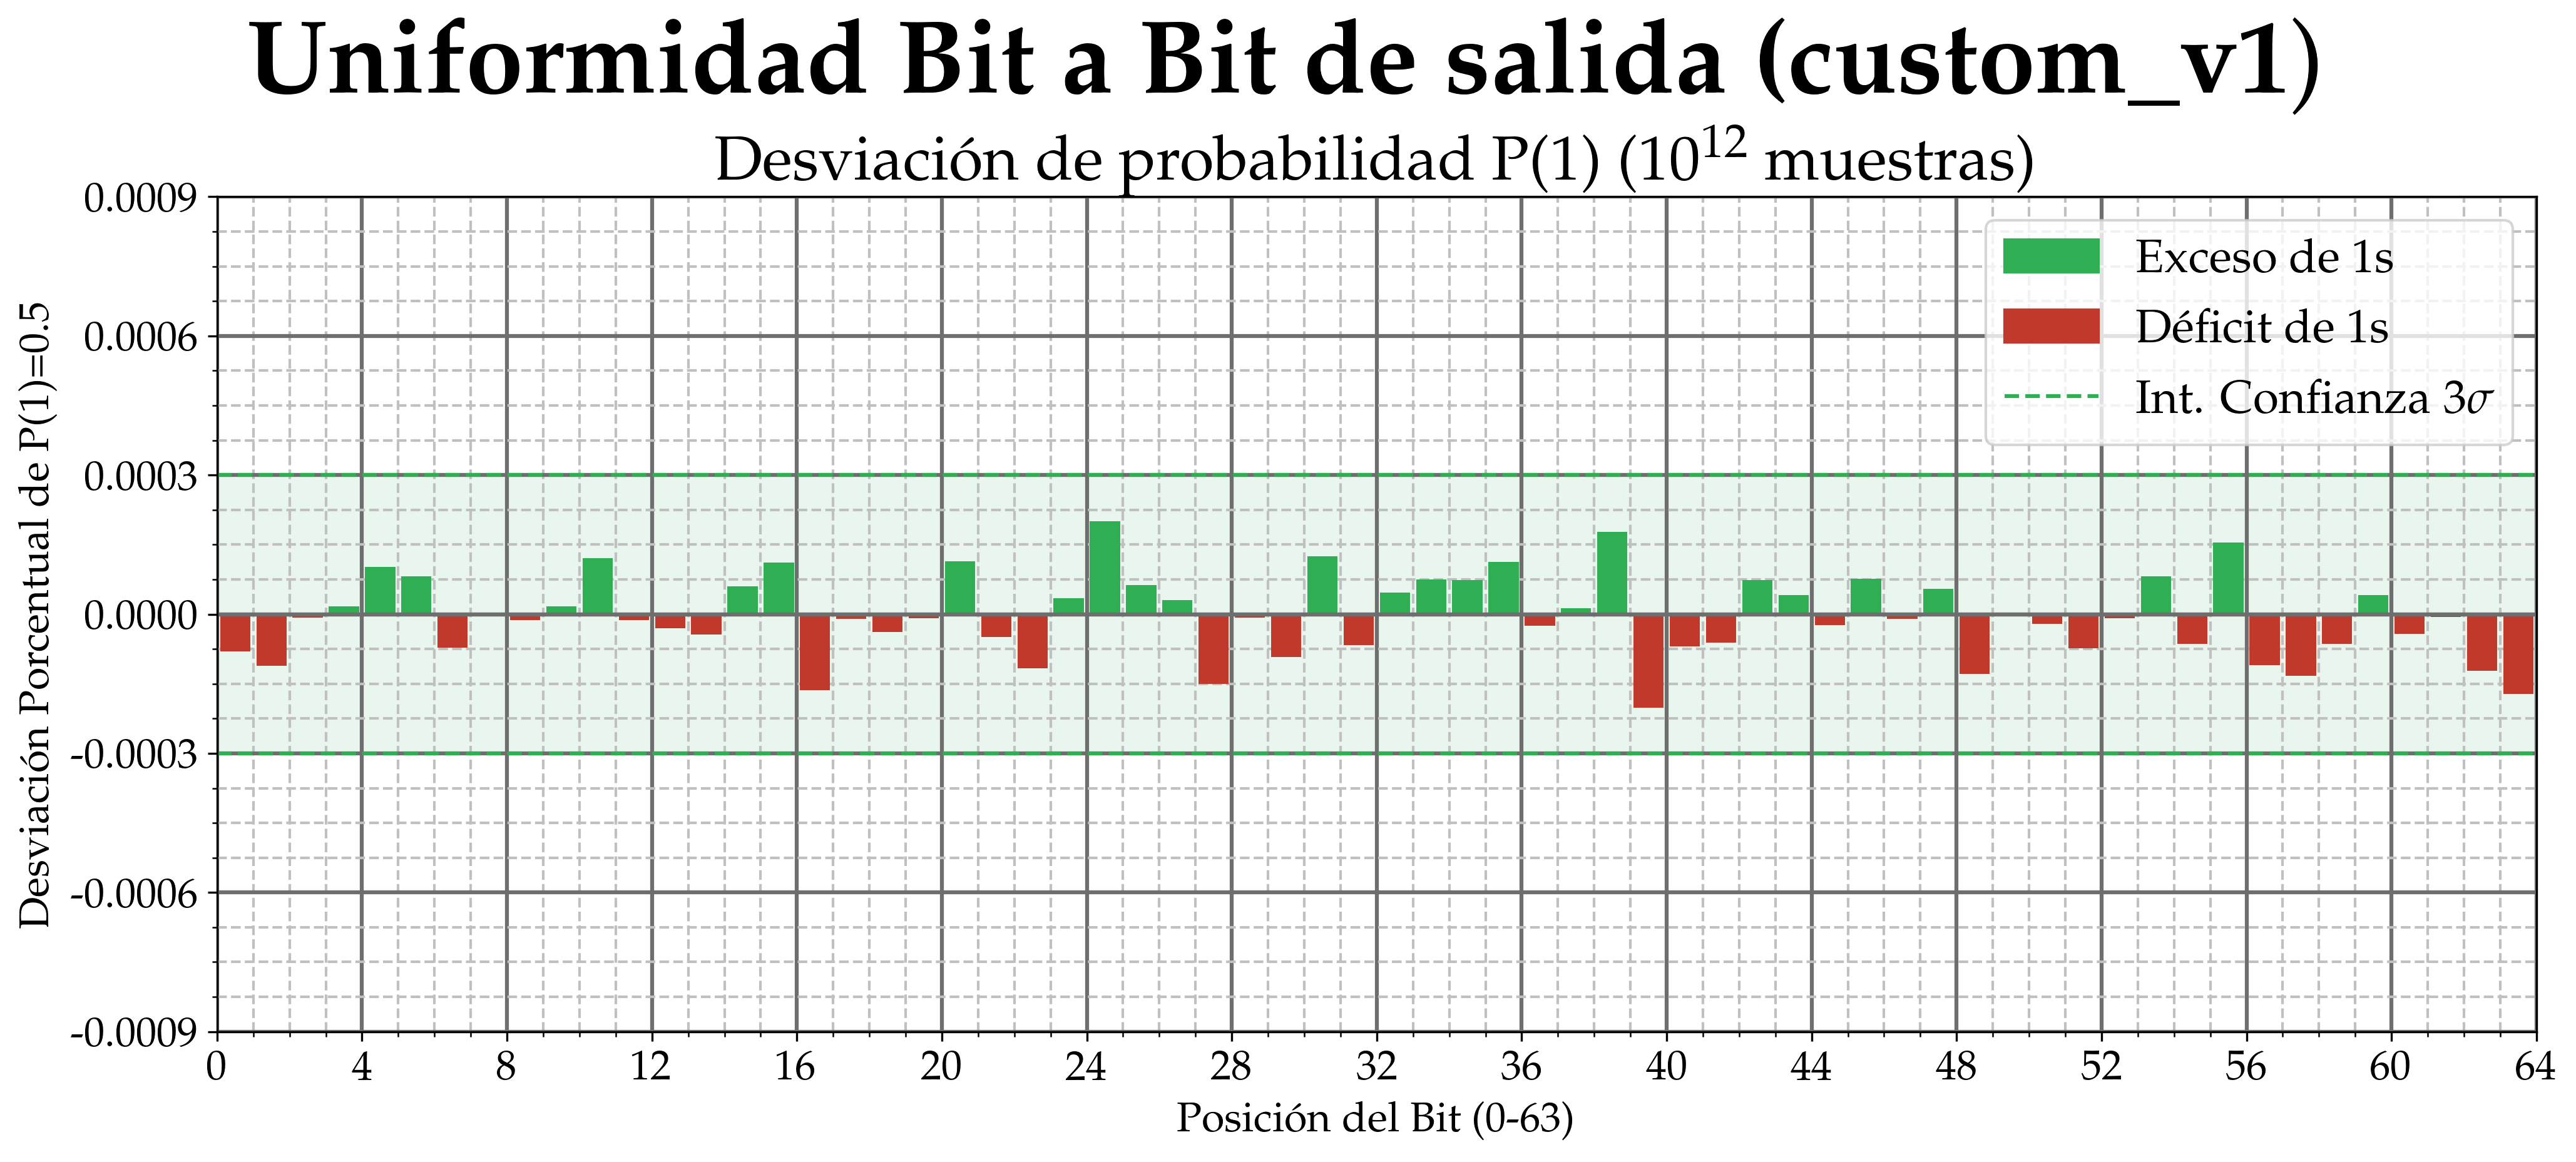

In [438]:
N = chi2_log[-1][0]
f_exp = N / 2.0
delta_rel = [(f - f_exp) / f_exp * 100 for f in f_abs]

bar_centers = [i + 0.5 for i in range(len(f_abs))]
sigma_3_pct = 300.0 / np.sqrt(N)
y_limit = 3 * sigma_3_pct

fig, ax = plt.subplots(figsize=(14,6.7))

# 1. Ejes
ax.set_xlim(0, 64)
ax.set_ylim(-y_limit, y_limit)
ax.set_xlabel('Posición del Bit (0-63)')
ax.set_ylabel('Desviación Porcentual de P(1)=0.5')

# 2. Ticks
ax.set_xticks(range(0, 65, 4))
ax.set_xticklabels([f'{x}' for x in range(0, 65, 4)])

yticks = np.linspace(-y_limit, y_limit, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.4f}%' for y in yticks])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', axis='both', linestyle='-', color=GRAY_DARK, linewidth=1.5)
ax.grid(which='minor', axis='both', linestyle='--', color=GRAY, linewidth=1)

# 4. Títulos
fig.suptitle(f'\\textbf{{Uniformidad Bit a Bit de salida ({HASH_FUNCTION}}})', 
             fontsize=40, y=0.93)
ax.set_title(f'Desviación de probabilidad P(1) (${10}^{{{np.log10(N):.0f}}}$ muestras)',
             fontsize=24)

# 5. Elementos principales
bar_colors = [COLOR_GREEN if d > 0 else COLOR_RED for d in delta_rel]
ax.bar(bar_centers, delta_rel, color=bar_colors, width=5/6, zorder=2)
ax.axhline(y=0, color=GRAY_DARK, linestyle='-', linewidth=1.5)

ax.axhline(y=sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.axhline(y=-sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.fill_between([-1, 64], -sigma_3_pct, sigma_3_pct, color=COLOR_GREEN, alpha=0.1)

positive_patch = mpatches.Patch(color=COLOR_GREEN, label='Exceso de 1s')
negative_patch = mpatches.Patch(color=COLOR_RED, label='Déficit de 1s')
confidence_line = plt.Line2D([0], [0], color=COLOR_GREEN, linestyle='--',
                             label='Int. Confianza 3$\\sigma$')
ax.legend(handles=[positive_patch, negative_patch, confidence_line], loc='upper right')

plt.tight_layout()

fig.savefig(OUTPUT_DIR / "uniformidad" / f'uniformity_bit_deviation_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()

#### 1.3.2 Convergencia del Test Chi-Cuadrado ($\chi^2$)

Evolución de $\chi^2$ respecto al número de muestras $N$. Bandas de confianza para distribución uniforme.

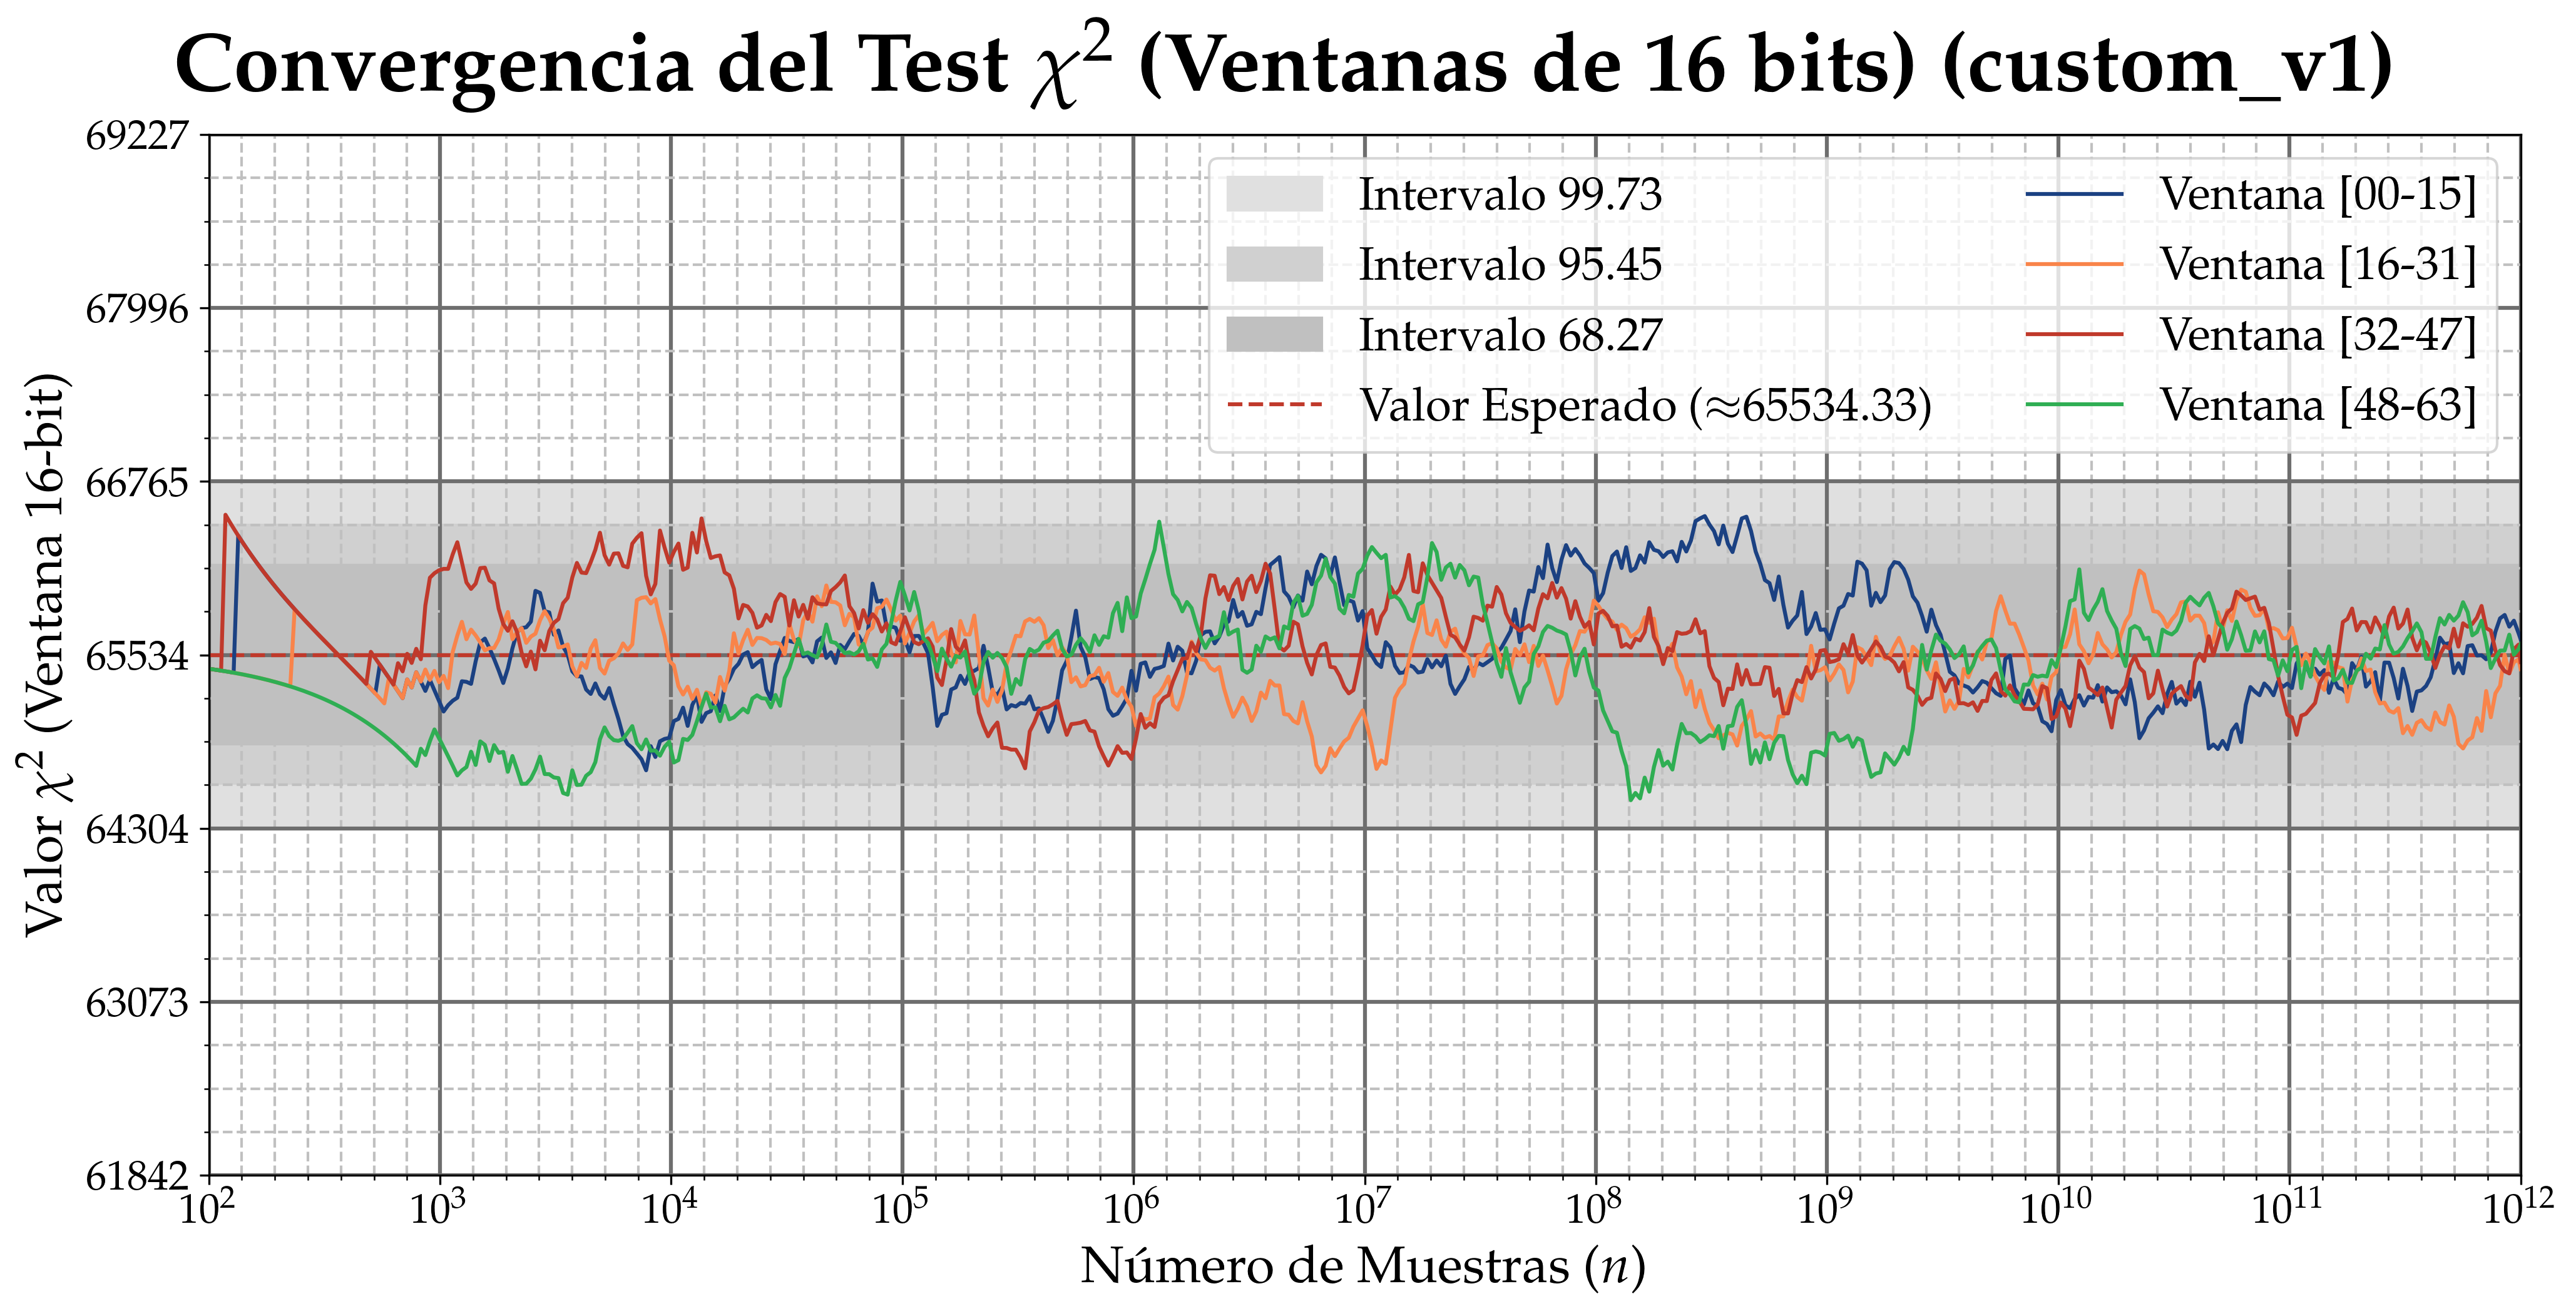

In [439]:
n_points = [x for x, _ in chi2_log]
chi2_values = np.array([vals for _, vals in chi2_log])

degrees_of_freedom = 2**16 - 1

thresholds = [
    (0.0027, GRAY_LIGHTER, '99.73% (Equiv a 3$\\sigma$)'),
    (0.0455, GRAY_LIGHT,   '95.45% (Equiv a 2$\\sigma$)'),
    (0.3173, GRAY,         '68.27% (Equiv a 1$\\sigma$)'),
]

fig, ax = plt.subplots(figsize=(14,7.5))

# 1. Ejes
ax.set_xscale('log', base=10)
ax.set_xlim(n_points[0], n_points[-1])

y_avg = chi2.ppf(0.5, degrees_of_freedom)
p_low_3s = thresholds[0][0] / 8
val_low_3s = chi2.ppf(p_low_3s, degrees_of_freedom)
val_high_3s = chi2.ppf(1 - p_low_3s, degrees_of_freedom)

margin_3s = (val_high_3s - val_low_3s) / 2.0
y_limit = margin_3s * 3.0

y_min = y_avg - y_limit
y_max = y_avg + y_limit

ax.set_ylim(y_min, y_max)
ax.set_xlabel('Número de Muestras ($n$)', fontsize=20)
ax.set_ylabel('Valor $\\chi^2$ (Ventana 16-bit)', fontsize=20)

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.FixedLocator([10**(min_pow + i/7) for i in range((max_pow - min_pow) * 7)]))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

yticks = np.linspace(y_min, y_max, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.0f}' for y in yticks])

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle(f'\\textbf{{Convergencia del Test $\\chi^2$ (Ventanas de 16 bits) ({HASH_FUNCTION})}}', 
            fontsize=32, y=0.94)

# 5. Elementos principales
for alpha, color, label in thresholds:
    p_low = alpha / 8
    val_low = chi2.ppf(p_low, degrees_of_freedom)
    val_high = chi2.ppf(1 - p_low, degrees_of_freedom)
    ax.fill_between(n_points, val_low, val_high, color=color, label=f'Intervalo {label}')

ax.axhline(y_avg, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label=f'Valor Esperado ($\\approx${y_avg:.2f})')

window_labels = ['Ventana [00-15]', 'Ventana [16-31]', 'Ventana [32-47]', 'Ventana [48-63]']

colors = [COLOR_BLUE, COLOR_ORANGE, COLOR_RED, COLOR_GREEN]
for i in range(4):
    ax.plot(n_points, chi2_values[:, i], label=window_labels[i], color=colors[i], linewidth=1.5)

ax.legend(loc='upper right', ncol=2)

plt.tight_layout()

fig.savefig(OUTPUT_DIR / "uniformidad" / f'uniformity_chi2_convergence_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()

#### 1.3.3 Convergencia de la Entropía de Shannon ($H$)

Evolución de la Entropía $H$ vs muestras $N$. Referencia teórica $H_{max} = 16.0$ bits.

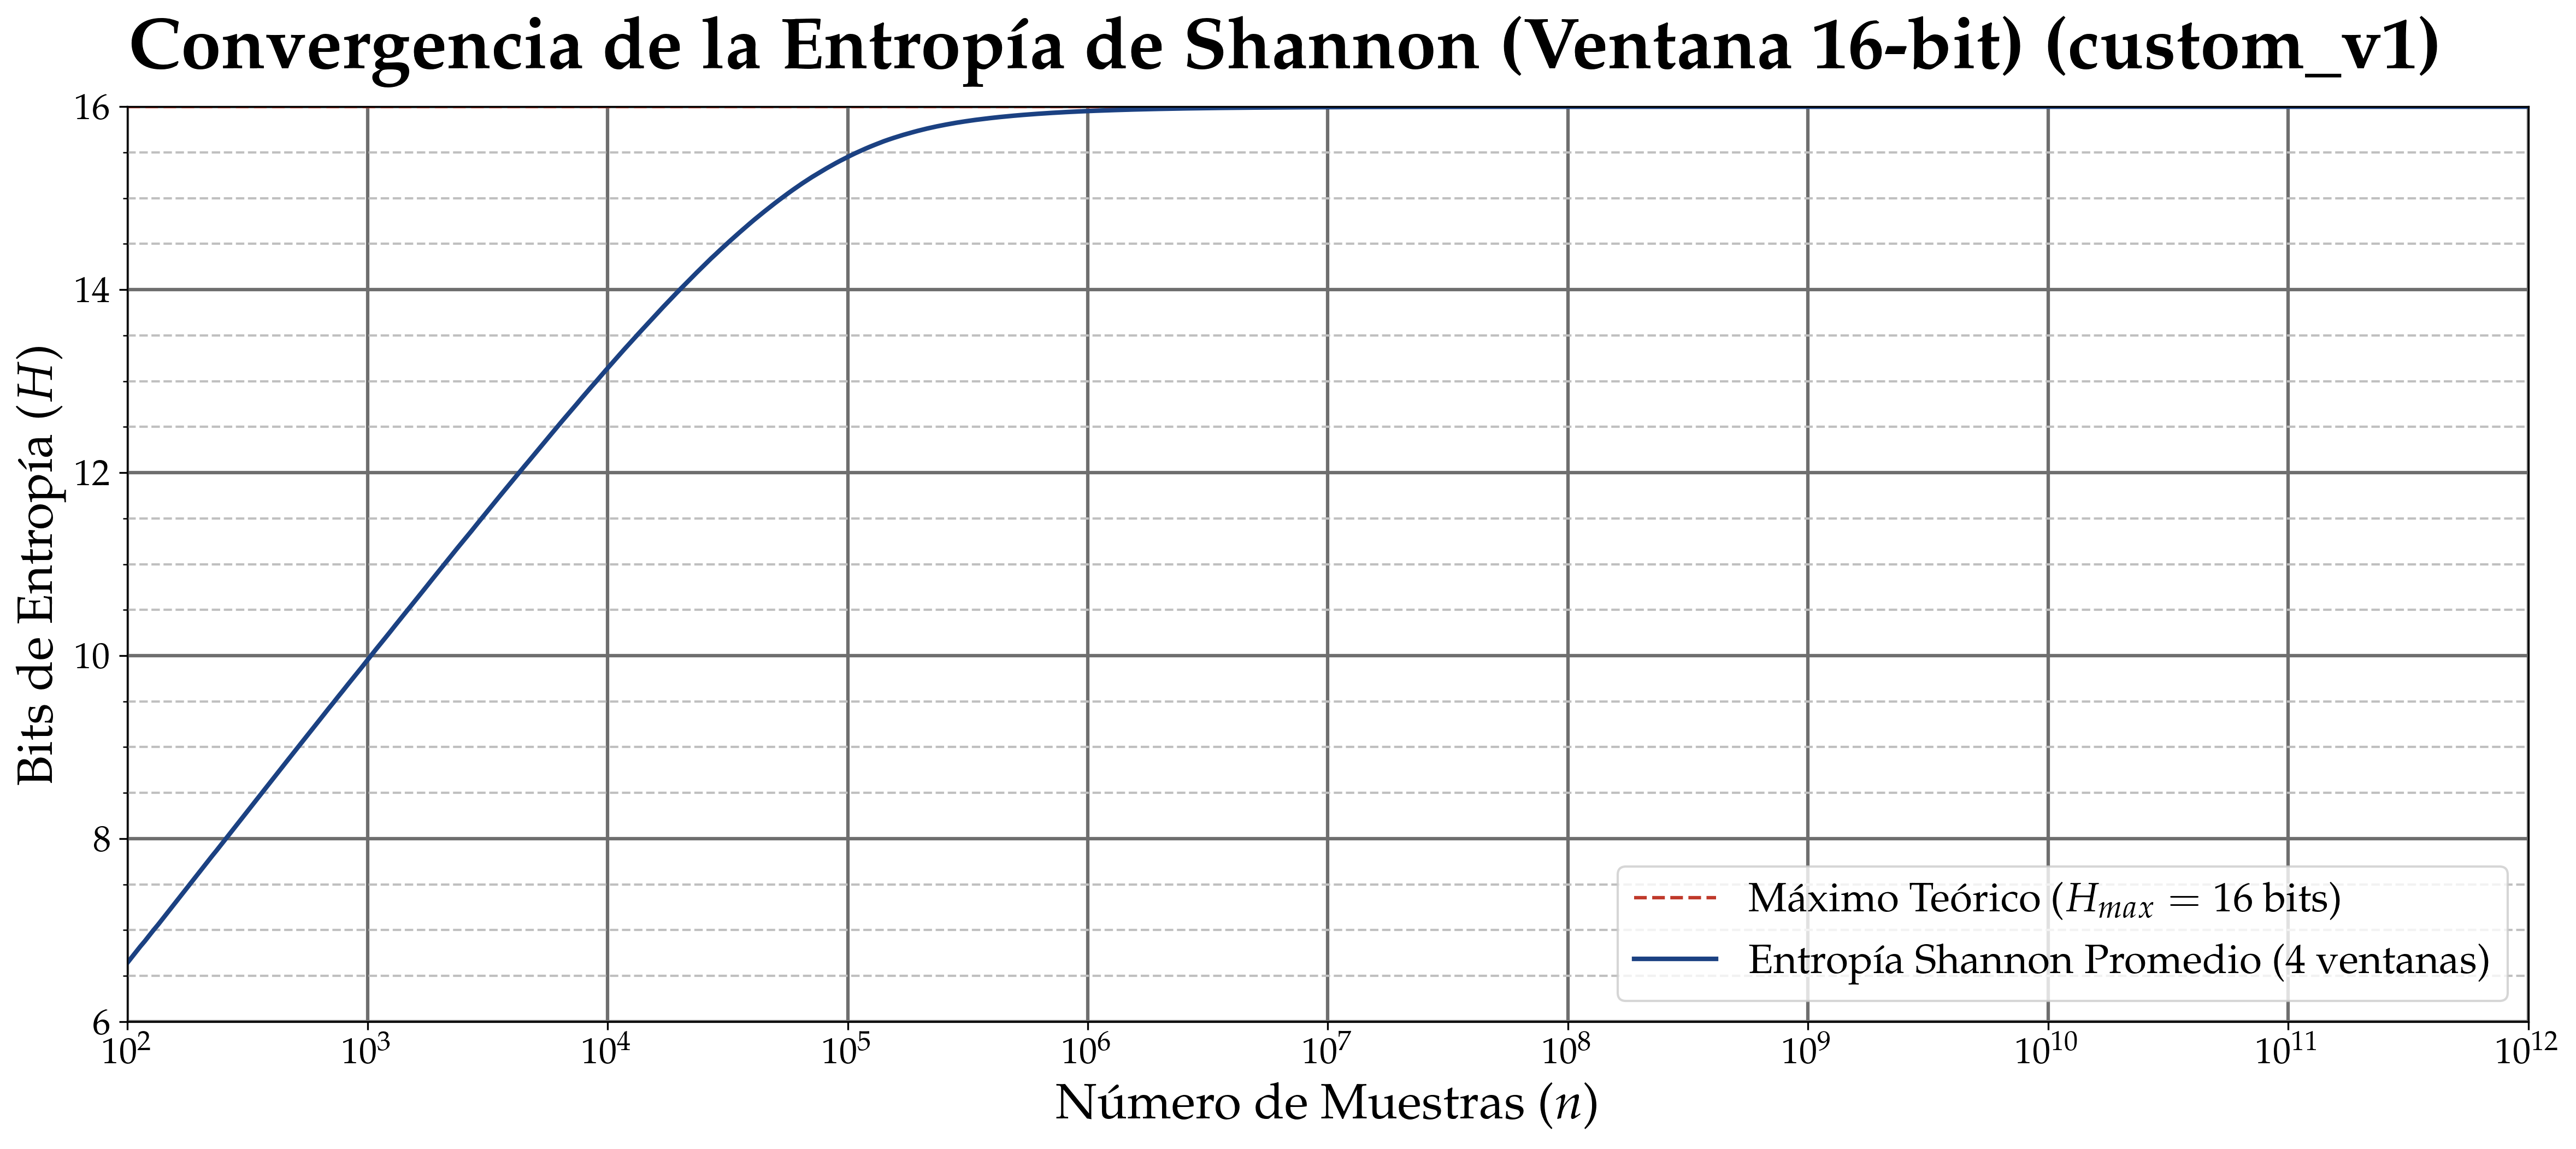

In [442]:
n_points  = [x for x, _ in chi2_log]
H_shannon = [y for _, y in entropy_log]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=LOG_FACTOR)
ax.set_xlim(n_points[0], n_points[-1])

ax.set_ylim(6, 16)

ax.set_xlabel('Número de Muestras ($n$)', fontsize=22)
ax.set_ylabel('Bits de Entropía ($H$)', fontsize=22)

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle(f'\\textbf{{Convergencia de la Entropía de Shannon (Ventana 16-bit) ({HASH_FUNCTION})}}', 
             fontsize=32, y=0.94)

# 5. Elementos principales
ax.axhline(16.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label='Máximo Teórico ($H_{max} = 16$ bits)')
ax.plot(n_points, H_shannon, label='Entropía Shannon Promedio (4 ventanas)',
        color=COLOR_BLUE, linewidth=2)

ax.legend(loc='lower right')

plt.tight_layout()

fig.savefig(OUTPUT_DIR / "uniformidad" / f'uniformity_entropy_convergence_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()

## 2. Test de Avalancha

Análisis Sensibilidad de entrada/salida (Efecto Avalancha). Objetivo: cambio de ~50% bits salida ante cambio de 1 bit entrada.

### 2.1 Extracción de Datos


Generación de métricas de avalancha: cambios en salida vs flips de 1 bit en $S, X, Y$.

In [447]:
#40 minutos
AVALANCHE_SAMPLES = 10_000_000_000
AVALANCHE_SEED = 0xDEADBEEFCAFEBABE

avalanche_output_file = LOGS_DIR / "avalancha" / "avalanche_64b.txt"

if avalanche_output_file.exists():
    print(f"Cargando datos existentes desde {avalanche_output_file}...")
    data_avalanche = avalanche_output_file.read_text()
else:
    cmd = ["./zig-out/bin/avalanche_64b", str(AVALANCHE_SAMPLES), str(AVALANCHE_SEED), HASH_FUNCTION]
    print(" ".join(cmd))

    result = subprocess.run(cmd, capture_output=True, text=True, check=True)
    data_avalanche = result.stdout
    avalanche_output_file.write_text(data_avalanche)

Cargando datos existentes desde logs/custom_v1/Zen_3/avalancha/avalanche_64b.txt...


#### 2.1.1 Datos en bruto obtenidos

In [448]:
data_avalanche.strip().splitlines()[:16]

['000, 000000000000, 000000000000, 000000000000',
 '001, 000000000000, 000000000000, 000000000000',
 '002, 000000000000, 000000000000, 000000000000',
 '003, 000000000000, 000000000000, 000000000000',
 '004, 000000000000, 000000000000, 000000000000',
 '005, 000000000001, 000000000000, 000000000000',
 '006, 000000000001, 000000000001, 000000000001',
 '007, 000000000029, 000000000021, 000000000020',
 '008, 000000000141, 000000000128, 000000000161',
 '009, 000000000972, 000000000997, 000000000984',
 '010, 000000005259, 000000005281, 000000005291',
 '011, 000000025809, 000000025893, 000000025856',
 '012, 000000113554, 000000114087, 000000114368',
 '013, 000000455813, 000000456135, 000000455711',
 '014, 000001660454, 000001660882, 000001659214',
 '015, 000005538364, 000005532163, 000005535220']

In [449]:
data_avalanche.strip().splitlines()[66:70]

['001: 319999952802, 319998465411, 320000355160 | S[4999970319,5000003872,4999990457,5000007981,5000006694,5000009329,4999855444,4999990995,5000084586,4999980114,5000006682,4999954512,4999970685,5000013529,5000009922,4999973790,4999950026,5000031062,4999962590,5000023730,5000062571,5000048071,4999943886,5000007919,5000041933,4999935773,5000093476,5000017041,4999899690,4999944640,4999979577,4999968819,4999973216,5000047812,5000093917,5000034943,5000037244,5000023177,4999978029,5000096995,5000017730,4999980234,4999985430,4999944235,5000026116,5000072619,4999963652,5000038245,4999999175,5000067997,5000045151,5000021026,5000018979,5000000650,4999973603,4999884556,4999931441,4999990811,5000040429,4999925589,5000070701,4999944020,4999952197,5000033168] X[4999925699,5000047211,4999946363,4999981072,4999938145,5000007766,4999921472,4999949067,5000037866,4999906053,5000071069,5000005307,5000054014,4999955694,4999996634,4999954201,4999984538,4999952625,4999995224,4999937778,4999981131,5000042491

### 2.2 Refinado de Datos

Procesamiento: Frecuencias Hamming ($f_h$) y media cambios/bit ($\mu$).

In [450]:
dist_regex = re.compile(r'(\d+),\s+(\d+),\s+(\d+),\s+(\d+)')
dist_data = dist_regex.findall(data_avalanche)

sac_regex = re.compile(r'(\d+):\s+(\d+),\s+(\d+),\s+(\d+)\s+\|\s+S\[(.*?)\]\s+X\[(.*?)\]\s+Y\[(.*?)\]')
sac_matches = sac_regex.findall(data_avalanche)

f_h_s = [int(r[1]) for r in dist_data]
f_h_x = [int(r[2]) for r in dist_data]
f_h_y = [int(r[3]) for r in dist_data]
f_h_total = [s + x + y for s, x, y in zip(f_h_s, f_h_x, f_h_y)]

mu_flips_s = [int(r[1]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_x = [int(r[2]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_y = [int(r[3]) / AVALANCHE_SAMPLES for r in sac_matches]

# Matrices SAC (64x64): P(flip) por cada par (bit_entrada, bit_salida)
sac_matrix_s = np.array([list(map(int, r[4].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_x = np.array([list(map(int, r[5].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_y = np.array([list(map(int, r[6].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES

### 2.3 Visualización de Datos

#### 2.3.1 Análisis de la Distribución de Hamming y Efecto Avalancha

Comparación métricas observadas vs ideal teórico (Binomial, $\mu=32.0$).

In [451]:
mu_global = np.mean([mu_flips_s, mu_flips_x, mu_flips_y])

print(f"Promedio global de bits de salida girados ($\\mu$): {mu_global:.8f} (Ideal: 32.0)")
print(f"\tDesviación respecto al ideal: {abs(32.0 - mu_global):.8f}")
print("-" * 50)
print(f"Media S ($\\mu_s$): {np.mean(mu_flips_s):.8f}")
print(f"Media X ($\\mu_x$): {np.mean(mu_flips_x):.8f}")
print(f"Media Y ($\\mu_y$): {np.mean(mu_flips_y):.8f}")

Promedio global de bits de salida girados ($\mu$): 31.99999957 (Ideal: 32.0)
	Desviación respecto al ideal: 0.00000043
--------------------------------------------------
Media S ($\mu_s$): 31.99999632
Media X ($\mu_x$): 32.00000185
Media Y ($\mu_y$): 32.00000053


In [452]:
def plot_avalanche_effect(data, title, filename_suffix):
    std_err = np.sqrt(64 * 0.5 * 0.5 / AVALANCHE_SAMPLES)
    margin = 3.0 * std_err
    ci_lower, ci_upper = 32.0 - margin, 32.0 + margin

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # 1. Ejes
    ax.set_xlim(0, 64)
    y_min = 32.0 - margin * 3
    y_max = 32.0 + margin * 3
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Posición del bit de entrada $j$ (0-63)', fontsize=20)
    ax.set_ylabel('$\\mu$ bits girados', fontsize=20)

    # 2. Ticks
    ax.set_xticks(np.arange(0, 65, 4))

    yticks = np.linspace(y_min, y_max, 7)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f'{y:.5f}' for y in yticks])

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(plt.MultipleLocator(1))

    # 3. Rejilla
    ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
    ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

    # 4. Títulos
    fig.suptitle(f'\\textbf{{{title}}}', fontsize=40, y=0.94)
    ax.set_title(f'Intervalo de confianza $3\\sigma \\approx 99.73\\%$ ($N=10^{{{int(np.log10(AVALANCHE_SAMPLES))}}}$)',
                 fontsize=24)

    # 5. Elementos principales
    ax.fill_between(range(65), ci_lower, ci_upper, color=COLOR_GREEN, alpha=0.2,
                    label='Zona de Aceptación (3$\\sigma$)')
    ax.axhline(y=32.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
               label='Media Teórica ($\\mu=32.0$)')
    ax.stairs(list(data) + [data[-1]], baseline=None, color=COLOR_BLUE, linewidth=2,
                  zorder=2, label='Media Observada ($\\mu$)', alpha=0.8)

    ax.legend(loc='upper right')

    plt.tight_layout()
    
    fig.savefig(OUTPUT_DIR / "avalancha" / f'avalanche_{filename_suffix}_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)
    
    plt.show()

#### 2.3.2 Efecto Avalancha: Variando bits de $Seed$

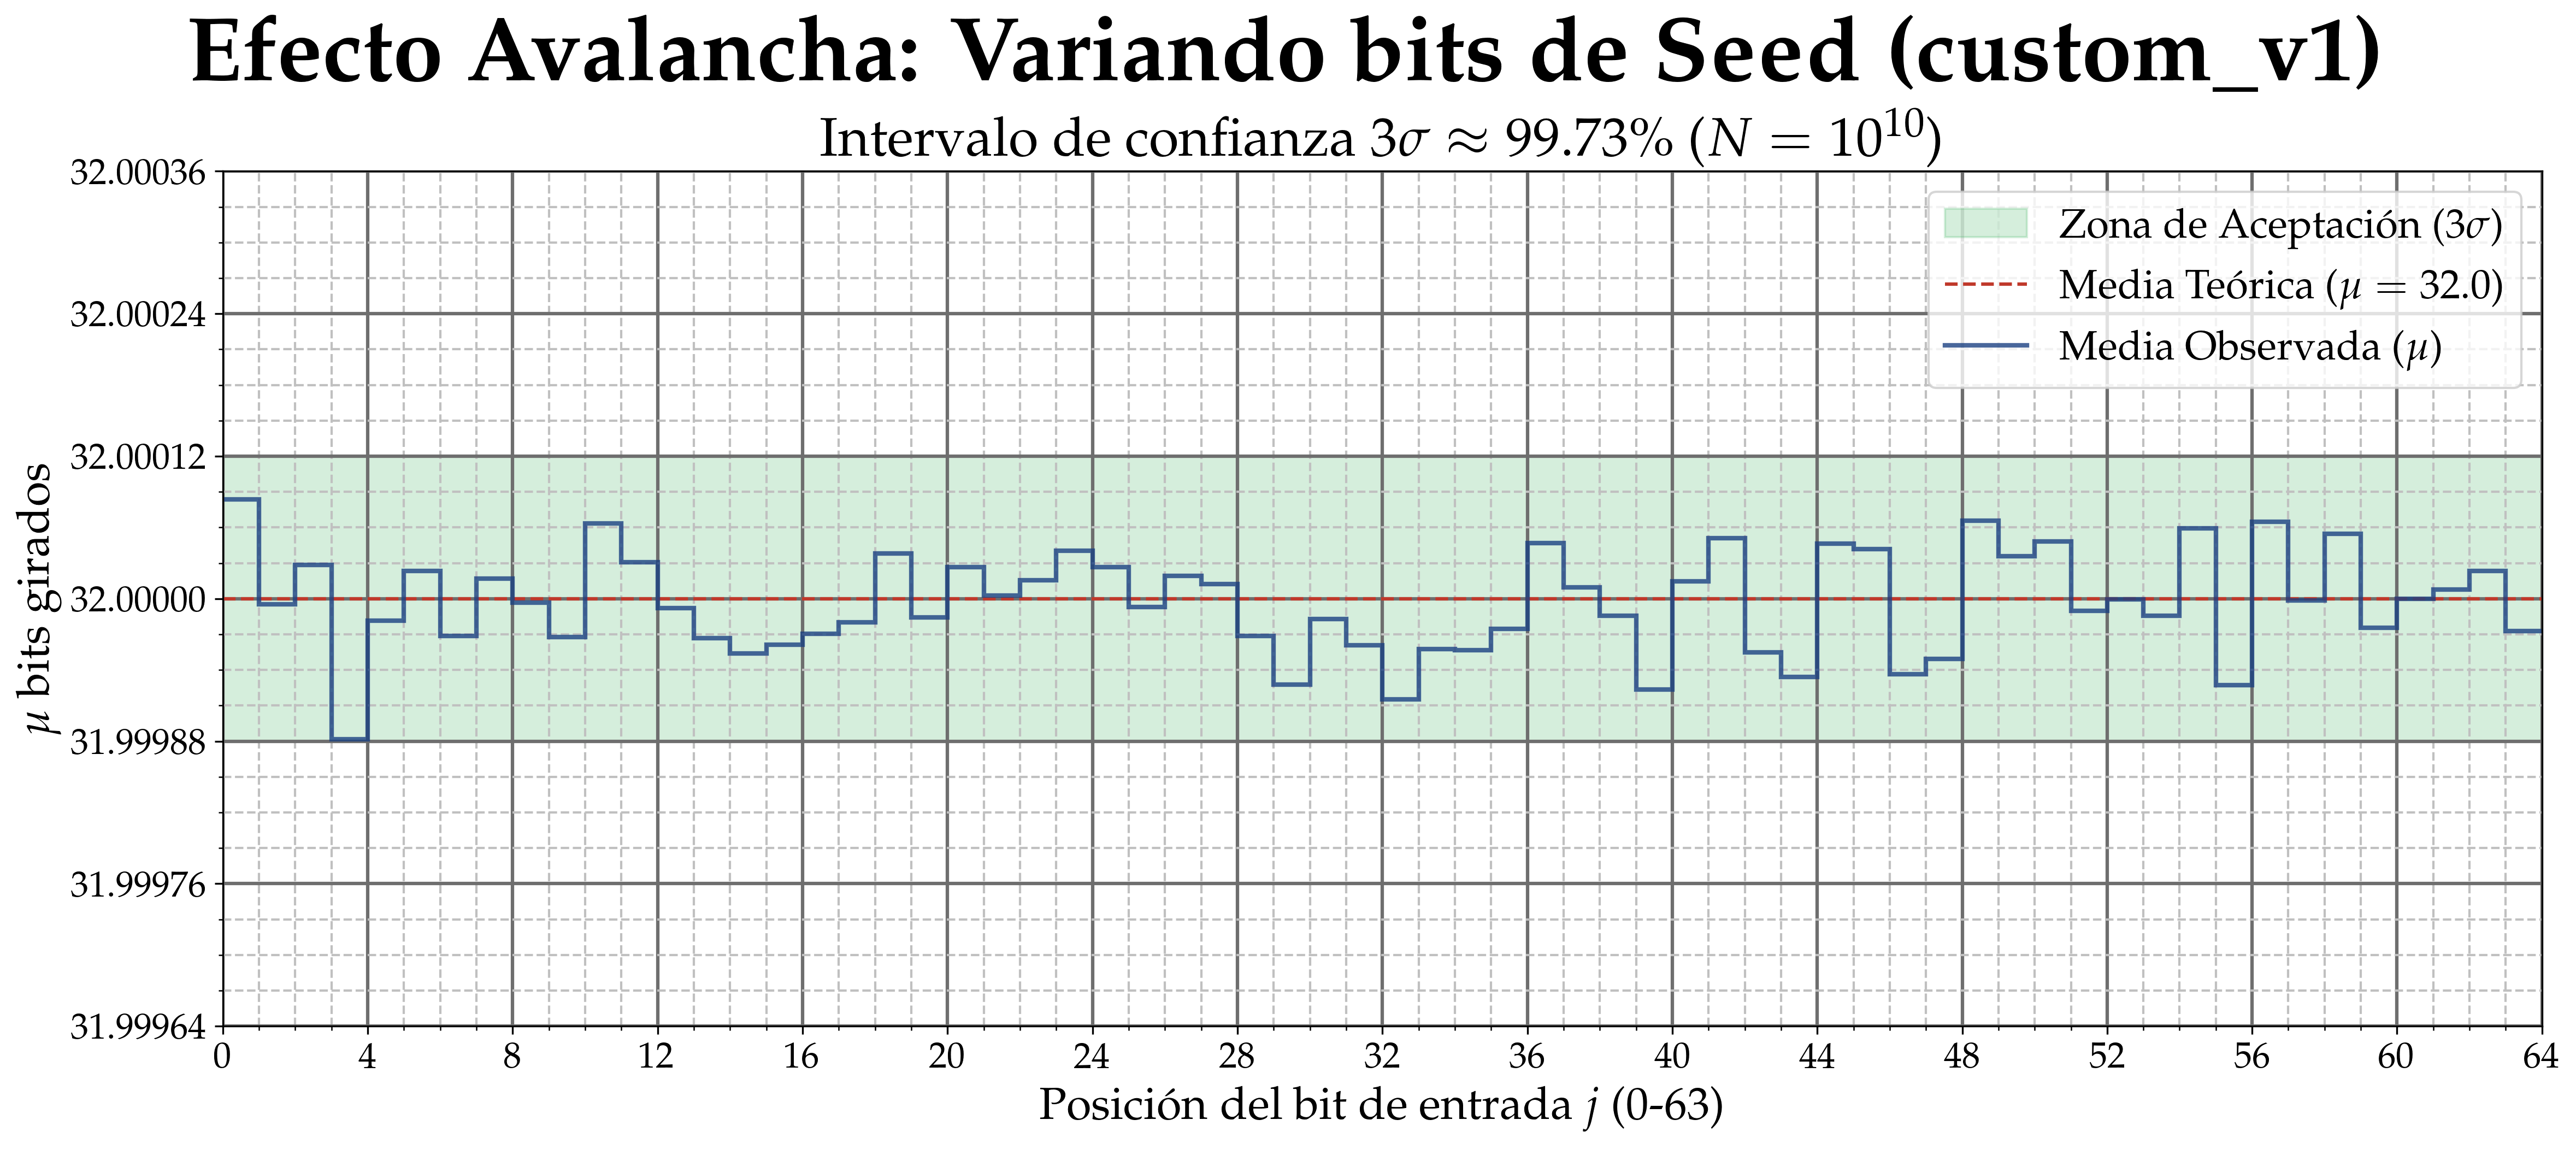

In [453]:
plot_avalanche_effect(mu_flips_s, f'Efecto Avalancha: Variando bits de $\\mathbf{{Seed}}$ ({(HASH_FUNCTION)})', 'seed')

#### 2.3.3 Efecto Avalancha: Variando bits de $X$


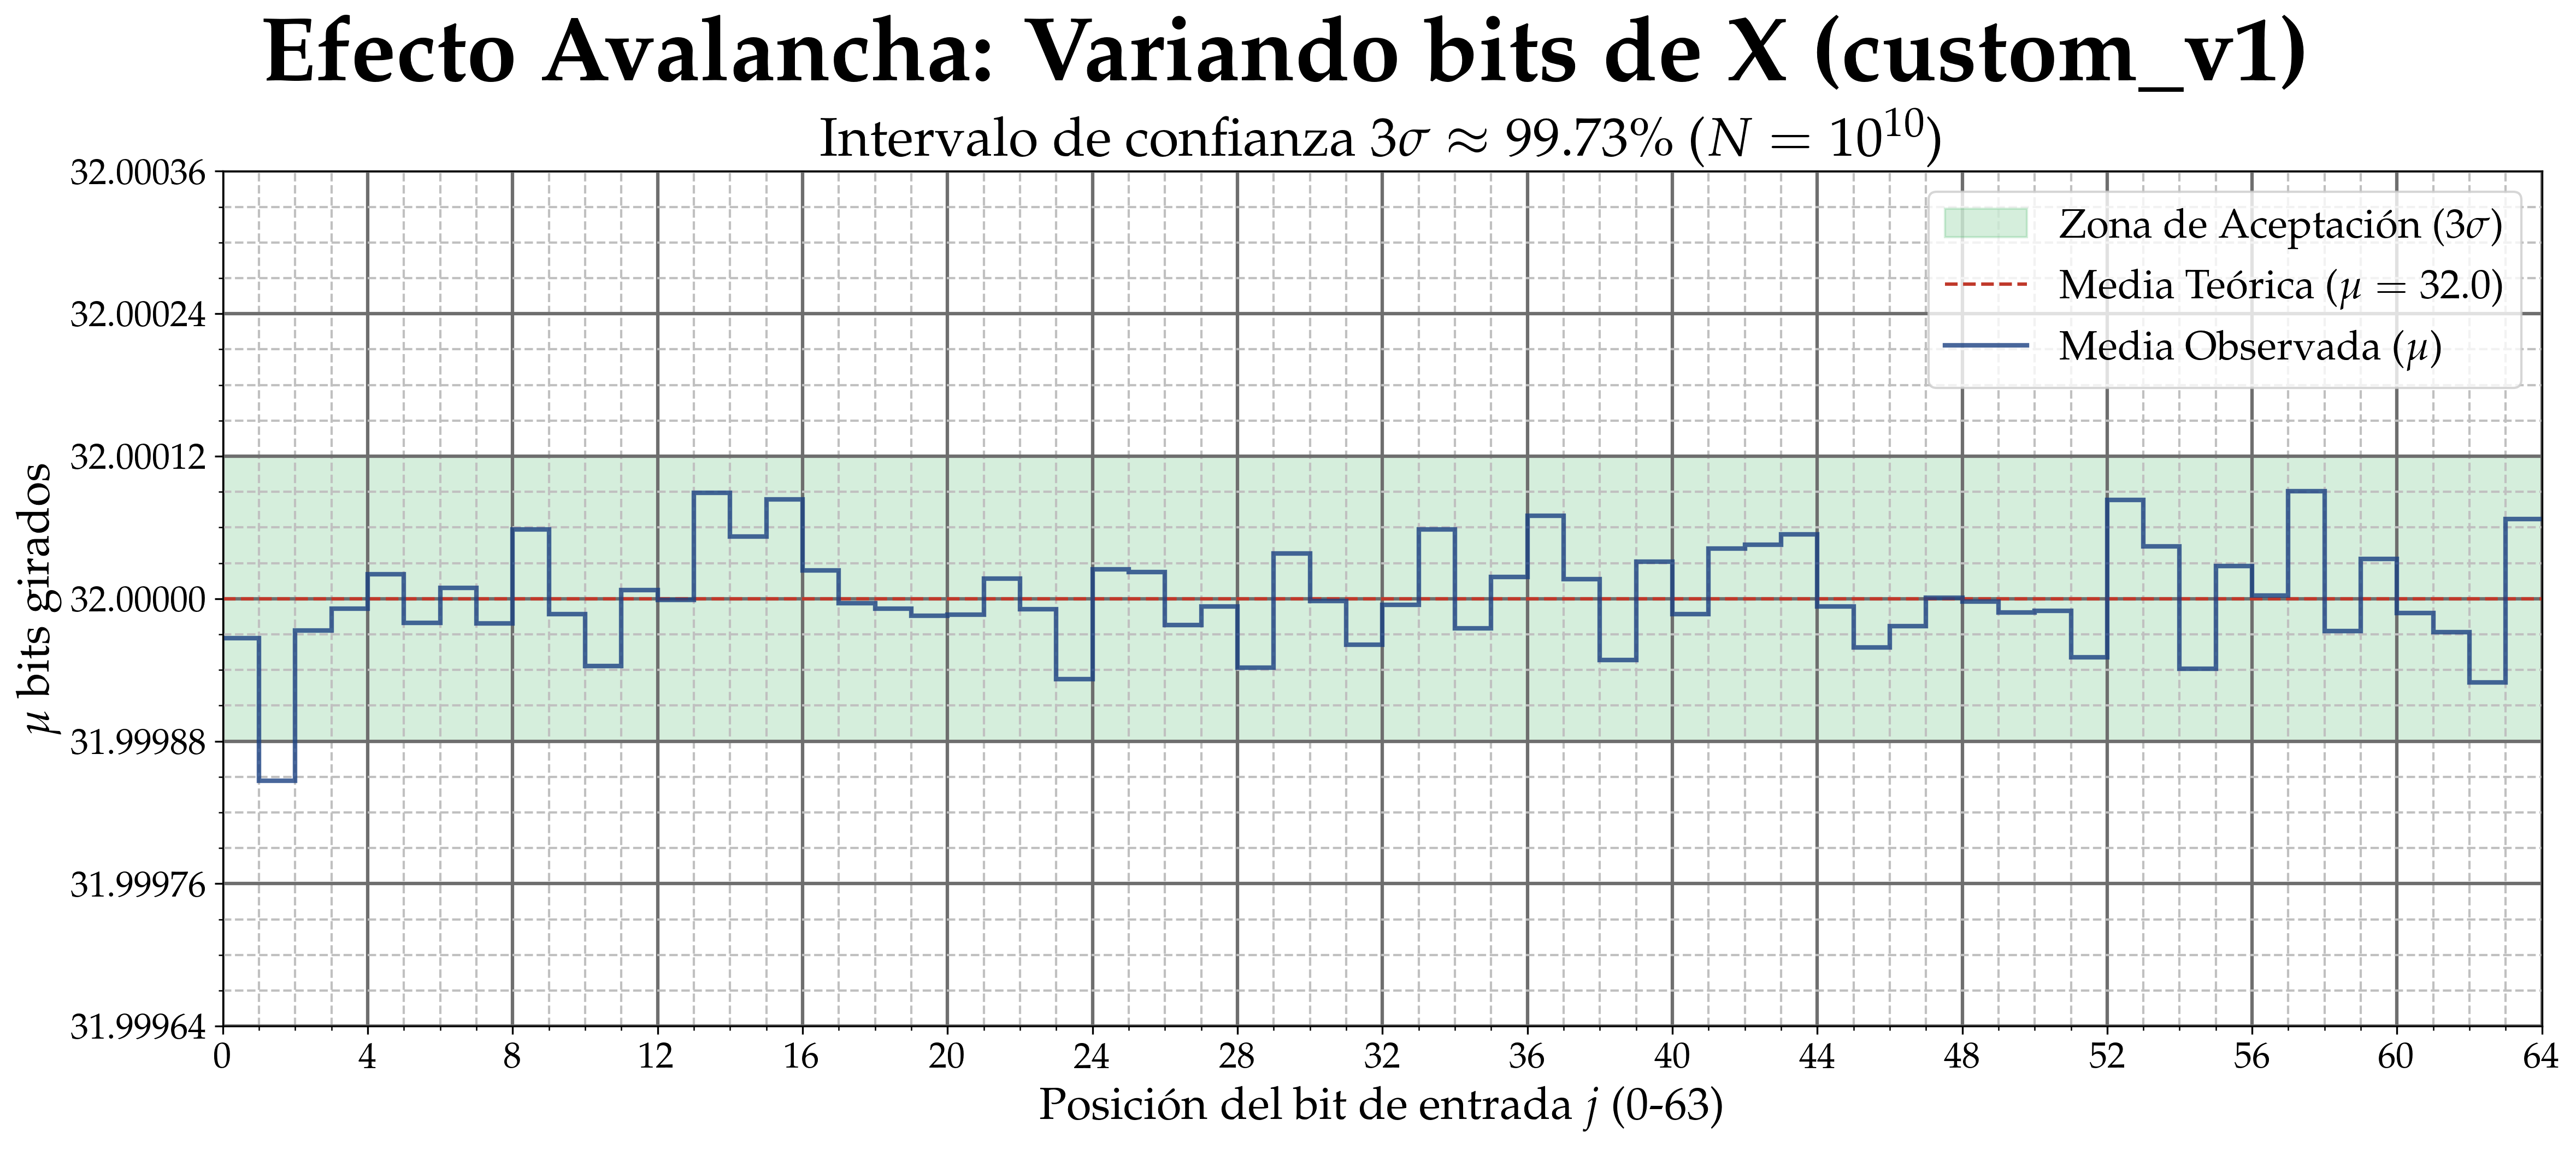

In [454]:
plot_avalanche_effect(mu_flips_x, f'Efecto Avalancha: Variando bits de $\\mathbf{{X}}$ ({(HASH_FUNCTION)})', 'x')

#### 2.3.4 Efecto Avalancha: Variando bits de $Y$

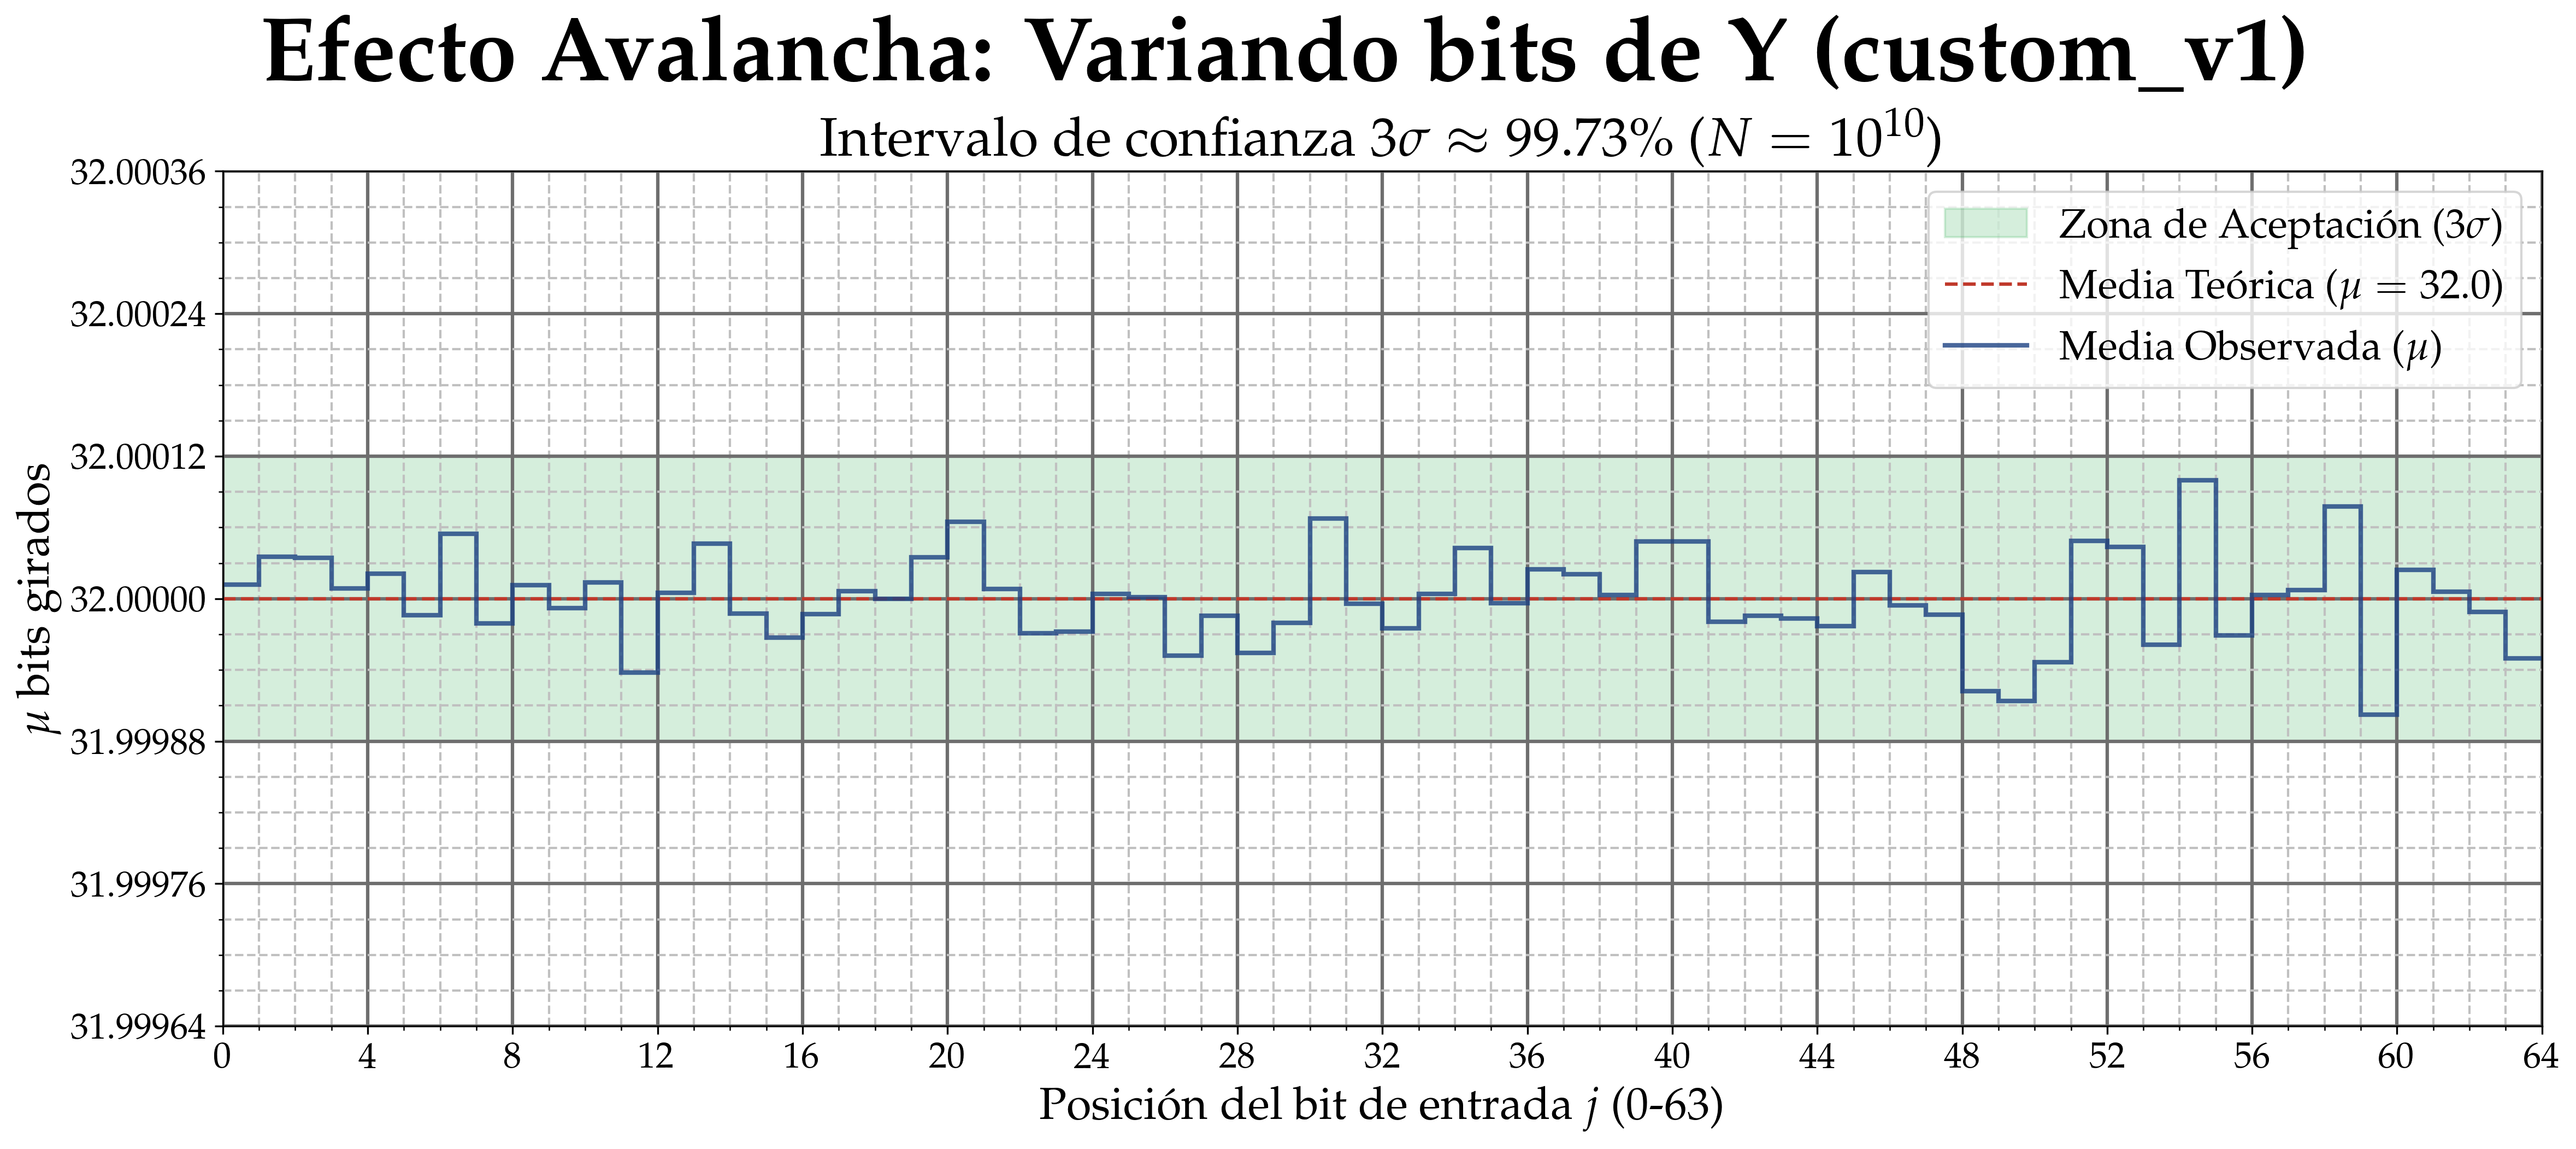

In [455]:
plot_avalanche_effect(mu_flips_y, f'Efecto Avalancha: Variando bits de $\\mathbf{{Y}}$ ({(HASH_FUNCTION)})', 'y')

#### 2.3.5 Distribución de Bits Cambiados (Distancia de Hamming $h$)

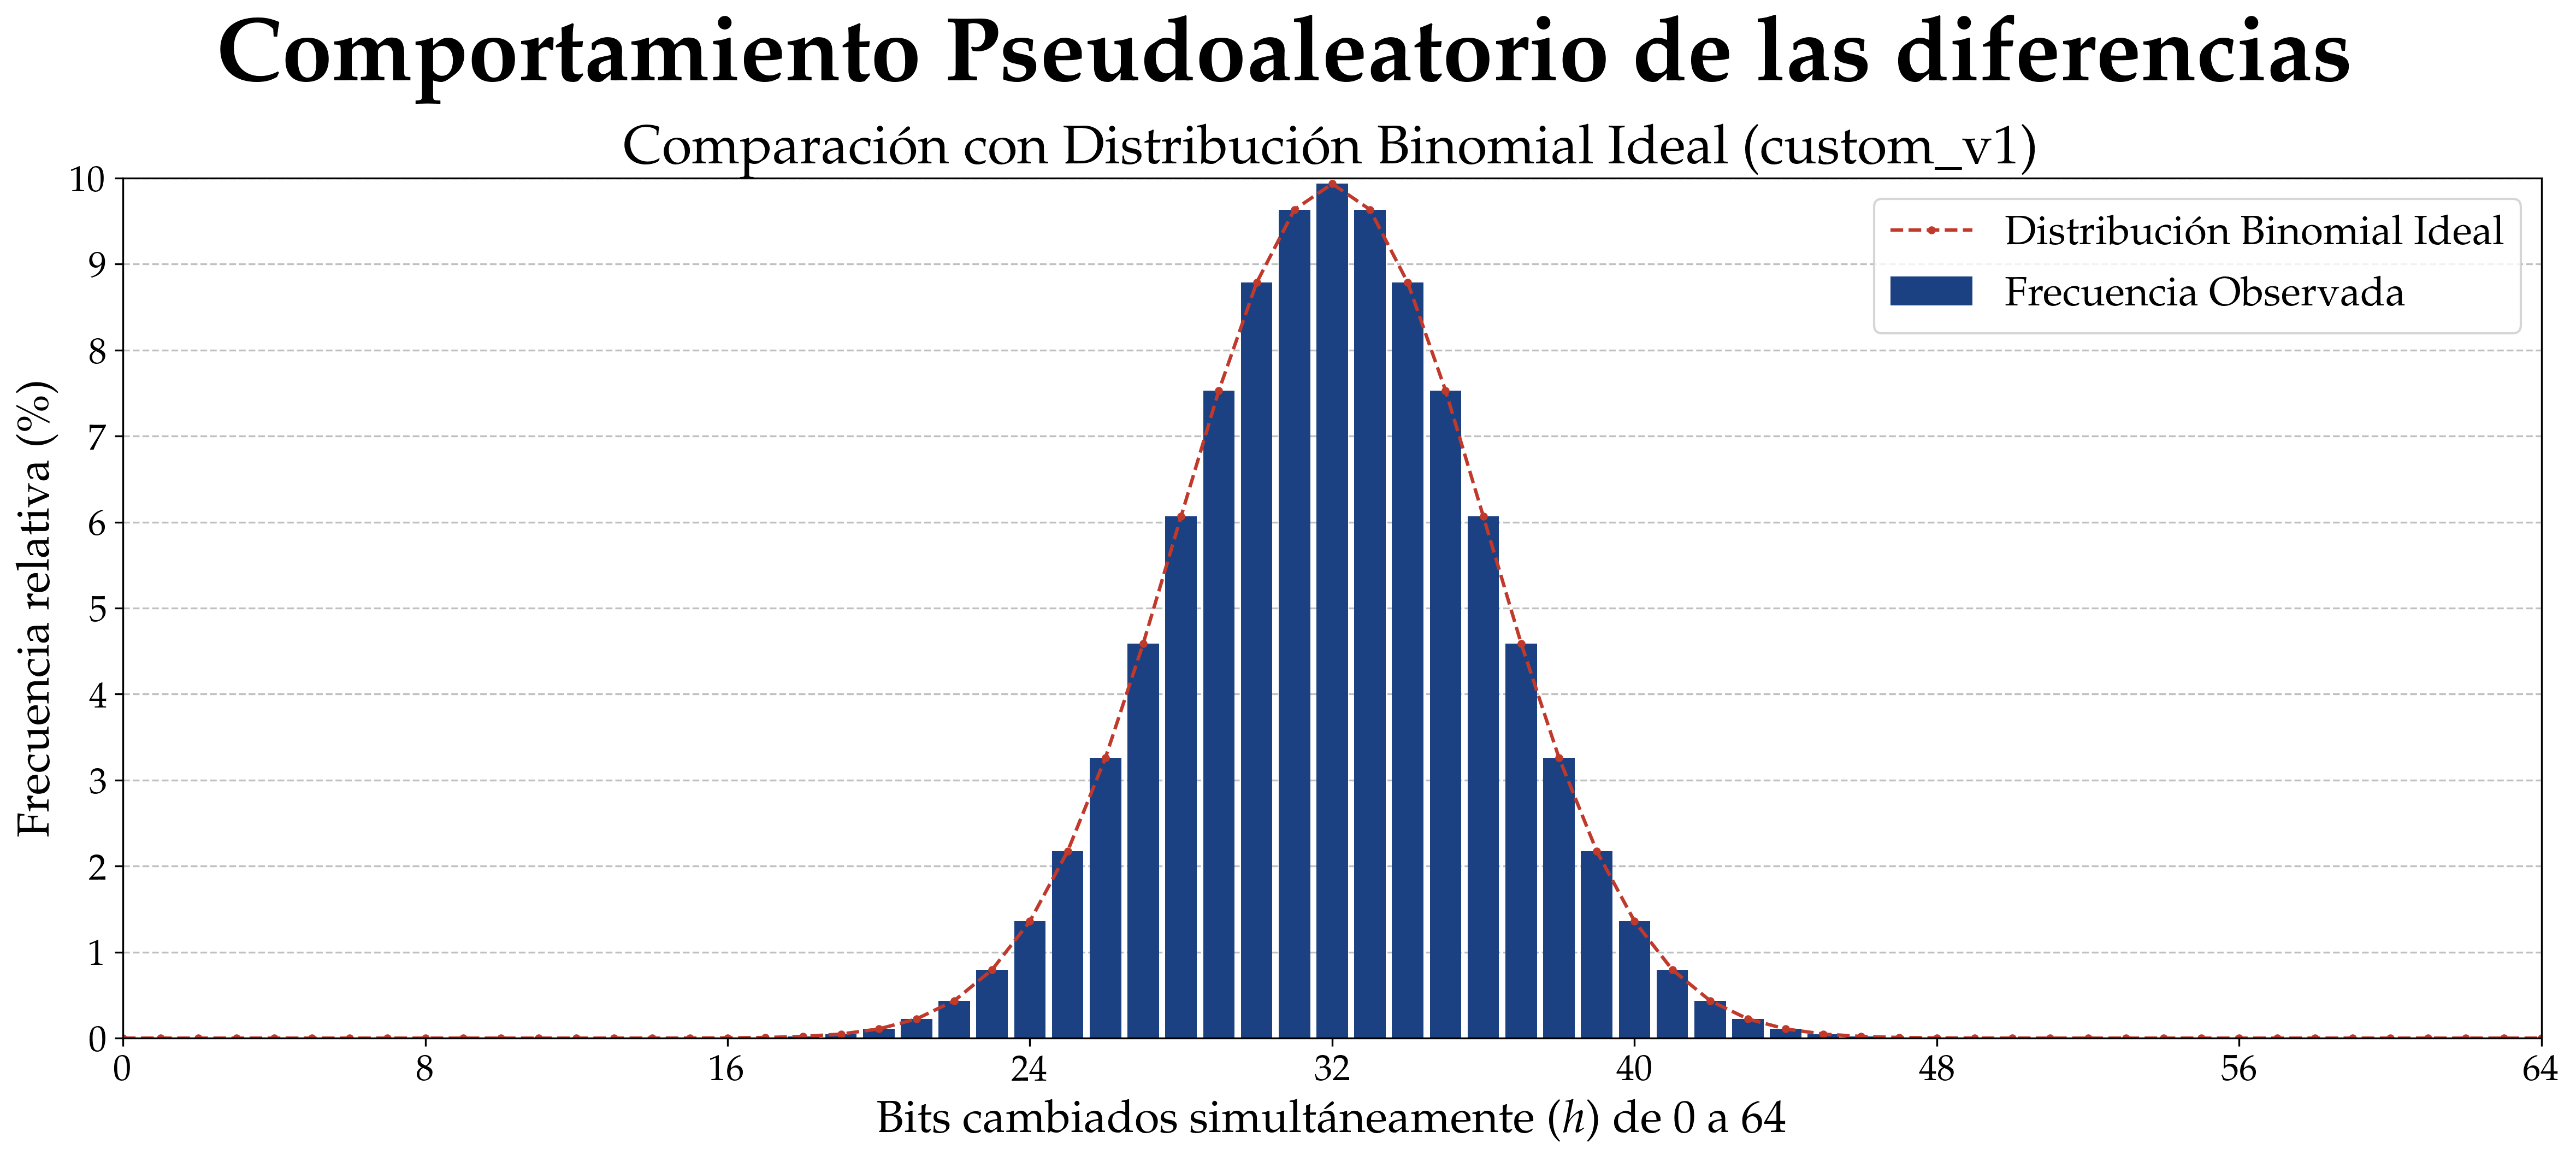

In [464]:
fig, ax = plt.subplots(figsize=(16, 7.5))

# 1. Ejes
h_vals = np.arange(len(f_h_total))
ax.set_xlabel('Bits cambiados simultáneamente ($h$) de 0 a 64', fontsize=20)
ax.set_ylabel('Frecuencia relativa (\\%)', fontsize=20)
ax.set_xlim(0, 64)
ax.set_ylim(0, 0.1)

# 2. Ticks
ax.set_xticks(range(0, 65, 8))
yticks_vals = np.linspace(0, 0.1, 11)
ax.set_yticks(yticks_vals)
ax.set_yticklabels([f'{y * 100:.0f}%' for y in yticks_vals])

# 3. Rejilla
ax.grid(axis='y', linestyle='--', color=GRAY)

# 4. Títulos
fig.suptitle('\\textbf{Comportamiento Pseudoaleatorio de las diferencias}', 
             fontsize=40, y=0.95)
ax.set_title(f'Comparación con Distribución Binomial Ideal ({HASH_FUNCTION})', 
             fontsize=24)

# 5. Elementos principales
total_ensayos = 3 * 64 * AVALANCHE_SAMPLES
f_rel_total = np.array(f_h_total) / total_ensayos
dist_binomial = binom.pmf(h_vals, 64, 0.5)

ax.bar(h_vals, f_rel_total, width=5/6, color=COLOR_BLUE, label='Frecuencia Observada', zorder=2)
ax.plot(h_vals, dist_binomial, color=COLOR_RED, linestyle='--', marker='.',
        markersize=5, label='Distribución Binomial Ideal')

ax.legend()

plt.tight_layout()

fig.savefig(OUTPUT_DIR / "avalancha" / f'avalanche_hamming_distribution_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()

#### 2.3.6 Análisis del Criterio de Avalancha Estricto (SAC)

Evaluación detallada de la independencia de bits.
*   **Izquierda:** Matriz $(i, j)$ donde varía S.
*   **Centro:** Matriz $(i, j)$ donde varía X.
*   **Derecha:** Matriz $(i, j)$ donde varía Y.

Cada celda representa la probabilidad de cambio en el bit de salida $j$ al invertir el bit de entrada $i$. El valor ideal es $0.5$ (verde). Desviaciones significativas (rojo) indican correlaciones no deseadas.

#### 2.3.7 Análisis Integral del SAC (S, X, Y)


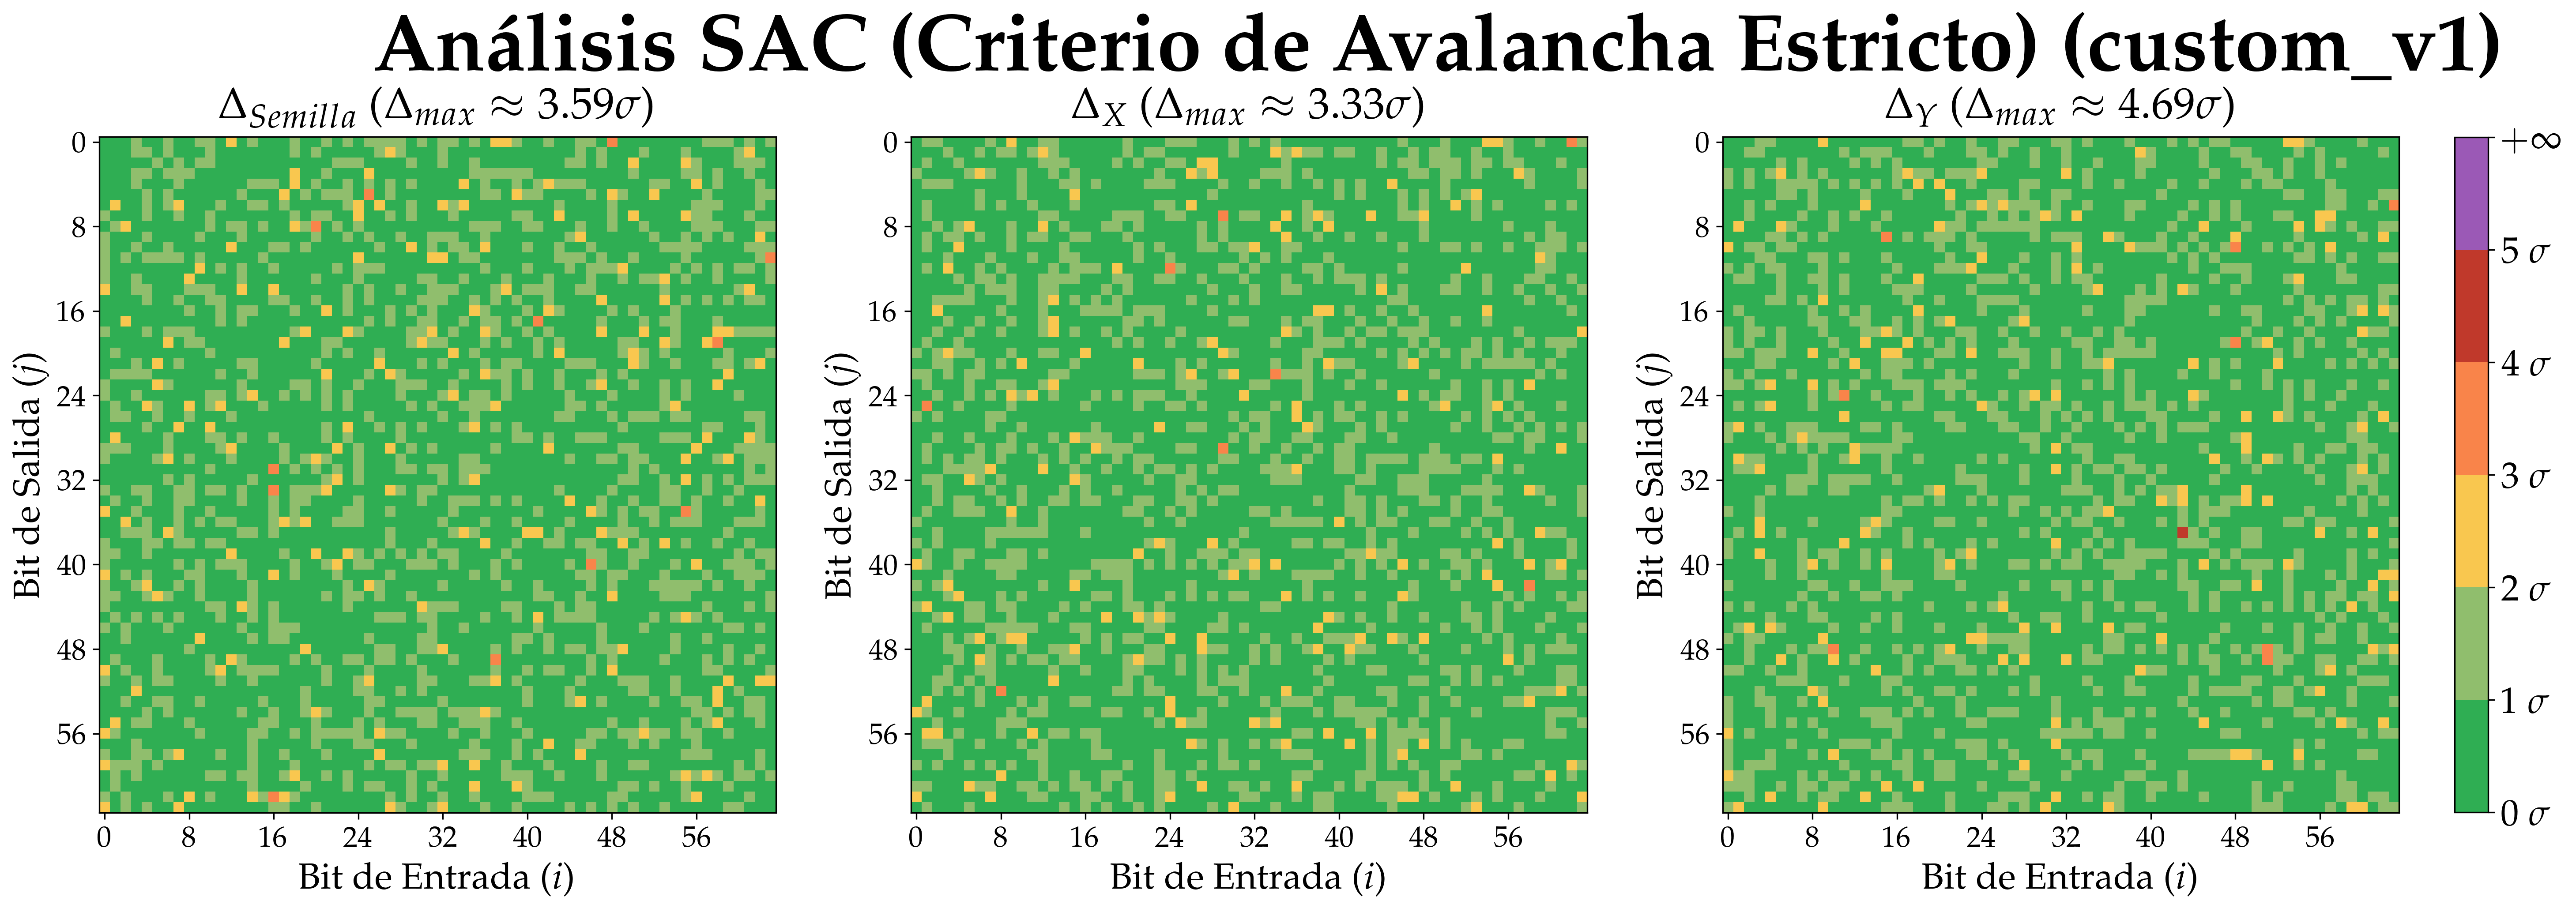

In [471]:
sac_configs = [
    (sac_matrix_s, '$\\Delta_{{Semilla}}$'),
    (sac_matrix_x, '$\\Delta_{{X}}$'),
    (sac_matrix_y, '$\\Delta_{{Y}}$')
]

fig, axes = plt.subplots(1, len(sac_configs), figsize=(27, 7.5))
axes = axes.flatten()

std_err_bit = 0.5 / np.sqrt(AVALANCHE_SAMPLES)
cmap = ListedColormap([COLOR_GREEN, COLOR_LIGHT_GREEN, COLOR_YELLOW, COLOR_ORANGE, COLOR_RED, COLOR_PURPLE])

for i, (matrix, title) in enumerate(sac_configs):
    ax = axes[i]
    z_scores = np.abs(matrix.T - 0.5) / std_err_bit
    z_mapped = np.digitize(z_scores, [1, 2, 3, 4, 5, 100])
    dev_max_sigma = np.max(z_scores)

    # 1. Ejes
    ax.set_xlim(-0.5, 63.5)
    ax.set_ylim(63.5, -0.5)
    ax.set_xlabel('Bit de Entrada ($i$)', fontsize=20)
    ax.set_ylabel('Bit de Salida ($j$)', fontsize=20)

    # 2. Ticks
    ax.set_xticks(np.arange(0, 64, 8))
    ax.set_yticks(np.arange(0, 64, 8))

    # 3. Títulos
    ax.set_title(f"{title} ($\\Delta_{{max}} \\approx {dev_max_sigma:.2f}\\sigma$)",
                 fontsize=24, pad=10)

    # 4. Elementos principales
    im = ax.imshow(z_mapped, cmap=cmap, vmin=0, vmax=len(cmap.colors), aspect='equal', zorder=2)

# 5. Título y leyenda global
fig.suptitle(f'\\textbf{{Análisis SAC (Criterio de Avalancha Estricto) ({HASH_FUNCTION})}}', 
             fontsize=44, y=0.96)

cbar = fig.colorbar(im, ax=axes.tolist(), pad=0.02, shrink=883/1000)
cbar.set_ticks(np.arange(len(cbar.cmap.colors) + 1))
cbar.set_ticklabels(
    ['0 $\\sigma$', '1 $\\sigma$', '2 $\\sigma$', '3 $\\sigma$', '4 $\\sigma$', '5 $\\sigma$', '$+\\infty$'],
    fontsize=20
    )

fig.savefig(OUTPUT_DIR / "avalancha" / f'avalanche_sac_analysis_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()

## 3. Test de Patrones

Evaluación dual para detectar repeticiones no deseadas:
1. **Dominio Espacial:** Inspección visual directa para identificar artefactos geométricos.
2. **Dominio de Frecuencia (FFT):** Verificación matemática de la ausencia de periodicidad oculta.

### 3.1 Extracción de Datos

Generación de arrays binarios de secciones 2D (planos XY, XS, SY) de tamaño visualizable. 

(buscando visualizar el punto conflictivo $(0,0)$)

In [474]:
PATTERN_S = 0
PATTERN_X = -16
PATTERN_Y = -16
PATTERN_SIZE = 32
# Usamos el directorio de logs dinámico
PATTERN_OUT_DIR = LOGS_DIR / "patterns"
PATTERN_OUT_DIR.mkdir(parents=True, exist_ok=True)

# Lista de archivos esperados para verificar si ya existen
pattern_files = ['pattern_sy.bin', 'pattern_xs.bin', 'pattern_xy.bin']
all_exist = all((PATTERN_OUT_DIR / f).exists() for f in pattern_files)

if all_exist:
    print(f"Cargando patrones existentes desde {PATTERN_OUT_DIR}...")
else:
    print("\nEjecutando test de patrones...")
    cmd = ["./zig-out/bin/pattern_64b", str(PATTERN_S), str(PATTERN_X), str(PATTERN_Y), str(PATTERN_SIZE), str(PATTERN_OUT_DIR), HASH_FUNCTION]
    subprocess.run(cmd, check=True)
    print(' '.join(cmd))


Cargando patrones existentes desde logs/custom_v1/Zen_3/patterns...


In [475]:
configs = [
    ('x', PATTERN_X, 'pattern_sy.bin', "Coordenada Y", "Semilla"), 
    ('y', PATTERN_Y, 'pattern_xs.bin', "Coordenada X", "Semilla"),
    ('seed', PATTERN_S, 'pattern_xy.bin', "Coordenada X", "Coordenada Y")
]

def load_pattern_bin_u64(path, size):
    raw = np.fromfile(path, dtype=np.uint64)
    expected = size * size
    if raw.size != expected:
        raise ValueError(f"Tamaño invalido en {path}: {raw.size} elementos, esperado {expected}.")
    return raw.reshape((size, size))

pattern_data_u64 = [load_pattern_bin_u64(Path.joinpath(PATTERN_OUT_DIR, c[2]), PATTERN_SIZE) for c in configs]

In [476]:
def plot_matrix_2x4(matrix_list, config_info, main_title, xlabel, ylabel, filename_prefix, cbar_label=None, vmin=None, vmax=None):
    fig, axes = plt.subplots(2, 4, figsize=(16, 9.7))
    
    config_name = config_info[0]
    fixed_val = config_info[1]
    
    # Determinamos los límites dinámicamente según la configuración
    # configs = [
    #    ('x', PATTERN_X, 'pattern_sy.bin', "Coordenada Y", "Semilla"), 
    #    ('y', PATTERN_Y, 'pattern_xs.bin', "Coordenada X", "Semilla"),
    #    ('seed', PATTERN_S, 'pattern_xy.bin', "Coordenada X", "Coordenada Y")
    # ]
    
    if config_name == 'x':
        # fijo X: Varían Y (H) y S (V)
        start_x, end_x = PATTERN_Y, PATTERN_Y + PATTERN_SIZE
        start_y, end_y = PATTERN_S, PATTERN_S + PATTERN_SIZE
    elif config_name == 'y':
        # fijo Y: Varían X (H) y S (V)
        start_x, end_x = PATTERN_X, PATTERN_X + PATTERN_SIZE
        start_y, end_y = PATTERN_S, PATTERN_S + PATTERN_SIZE
    else:
        # fijo Seed: Varían X (H) e Y (V)
        start_x, end_x = PATTERN_X, PATTERN_X + PATTERN_SIZE
        start_y, end_y = PATTERN_Y, PATTERN_Y + PATTERN_SIZE

    for idx, matrix in enumerate(matrix_list):
        row = idx // 4
        col = idx % 4
        ax = axes[row, col]
        
        # extent=[left, right, bottom, top]
        _ = ax.imshow(matrix, cmap='gray', origin='lower', vmin=vmin, vmax=vmax,
                     extent=[start_x, end_x, start_y, end_y])
        
        # Configuramos los ticks con puntos de control (Inicio, Centro, Fin)
        # O Inicio, 0, Fin si el 0 está dentro del rango
        xticks = [start_x, (start_x + end_x) / 2, end_x]
        if start_x < 0 < end_x: xticks = [start_x, 0, end_x]
        
        yticks = [start_y, (start_y + end_y) / 2, end_y]
        if start_y < 0 < end_y: yticks = [start_y, 0, end_y]
            
        ax.set_xticks(xticks)
        ax.set_yticks(yticks)
        
        # Eje Y: Solo mostramos números y etiqueta en la primera columna (Izquierda)
        if col == 0:
            ax.set_ylabel(ylabel, fontsize=20)
        else:
            ax.set_yticklabels([])
            
        # Eje X: Solo mostramos números y etiqueta en la segunda fila (Abajo)
        if row == 1:
            ax.set_xlabel(xlabel, fontsize=20)
        else:
            ax.set_xticklabels([])
            

        title = f"Byte {idx} (Bits {idx*8}-{(idx*8)+7})"
        ax.set_title(title, fontsize=20)

        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.tick_params(length=0)
        

    fig.text(0.5, 0.86, f"Configuración: ${config_name}$ fijo en {fixed_val}", 
             ha='center', fontsize=28)
    fig.suptitle(f"\\textbf{{{main_title}}}\n", fontsize=36, y=0.95)

    plt.tight_layout()
    
    fig.savefig(OUTPUT_DIR / "patrones" / f'pattern_{filename_prefix}_{config_name}_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)
    
    plt.show()

### 3.2 Inspección Visual (Dominio Espacial)

Visualización directa de los cortes generados (ficheros binarios `pattern_*.bin`).

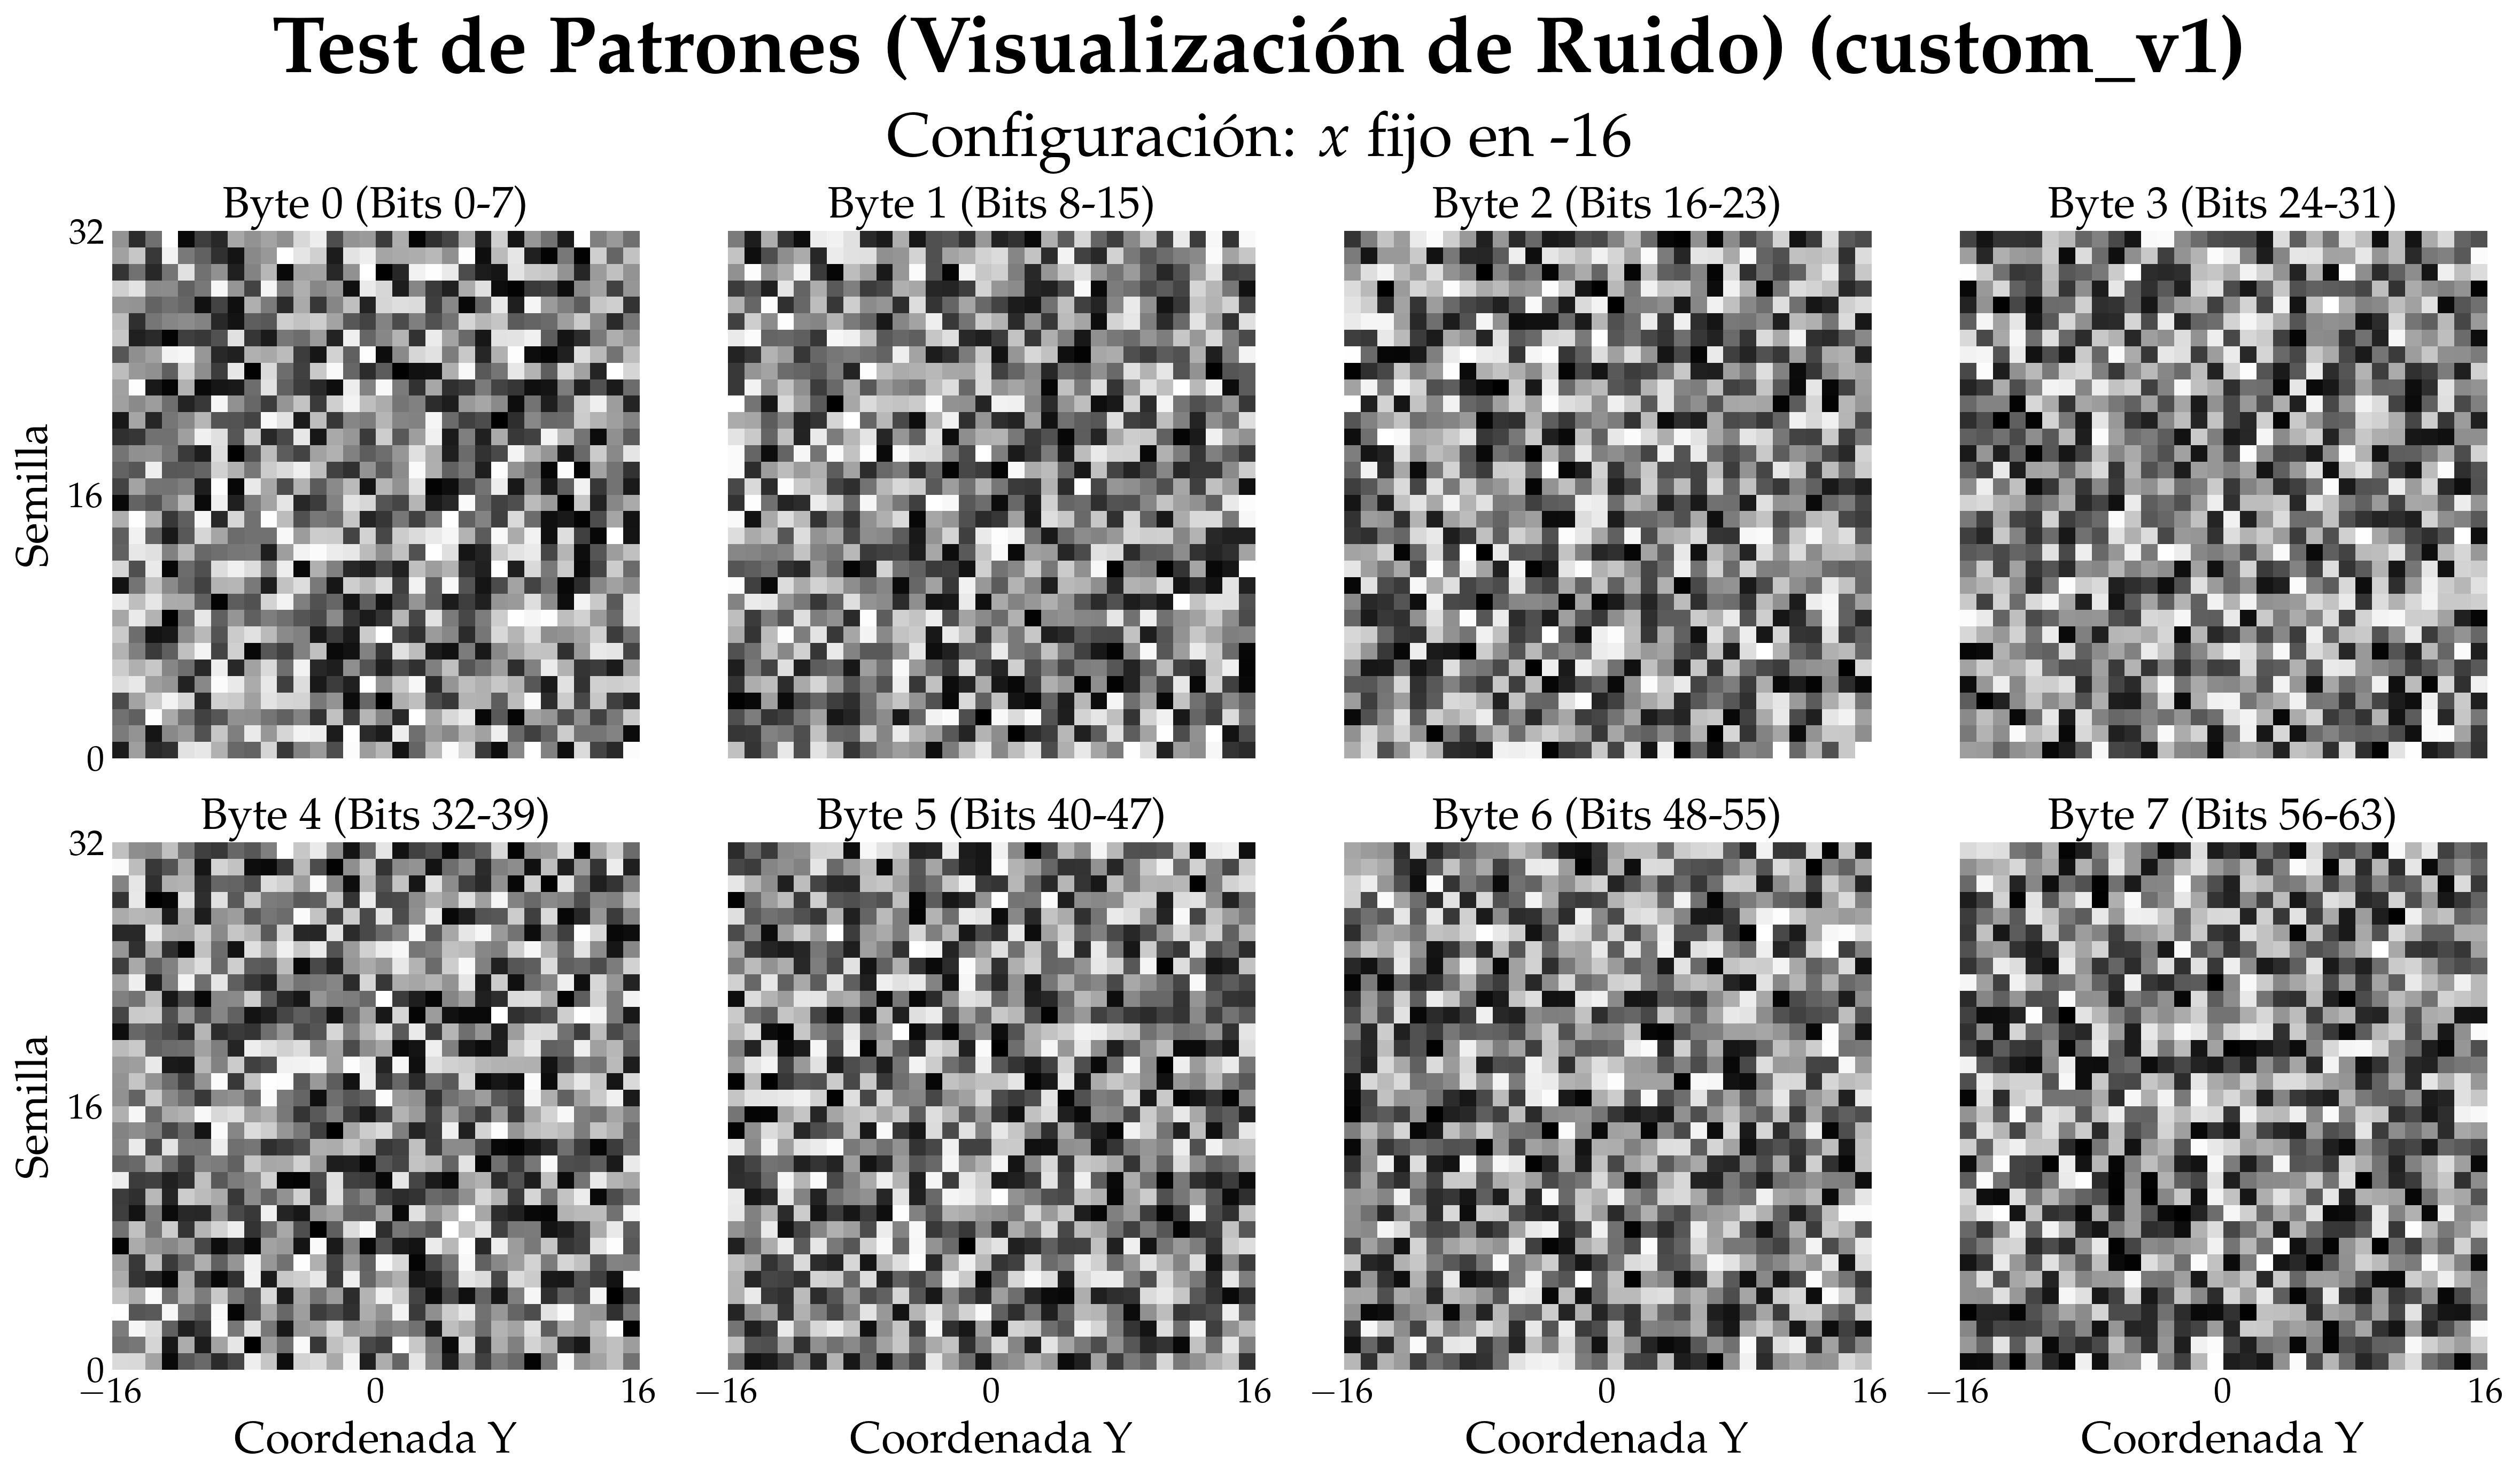

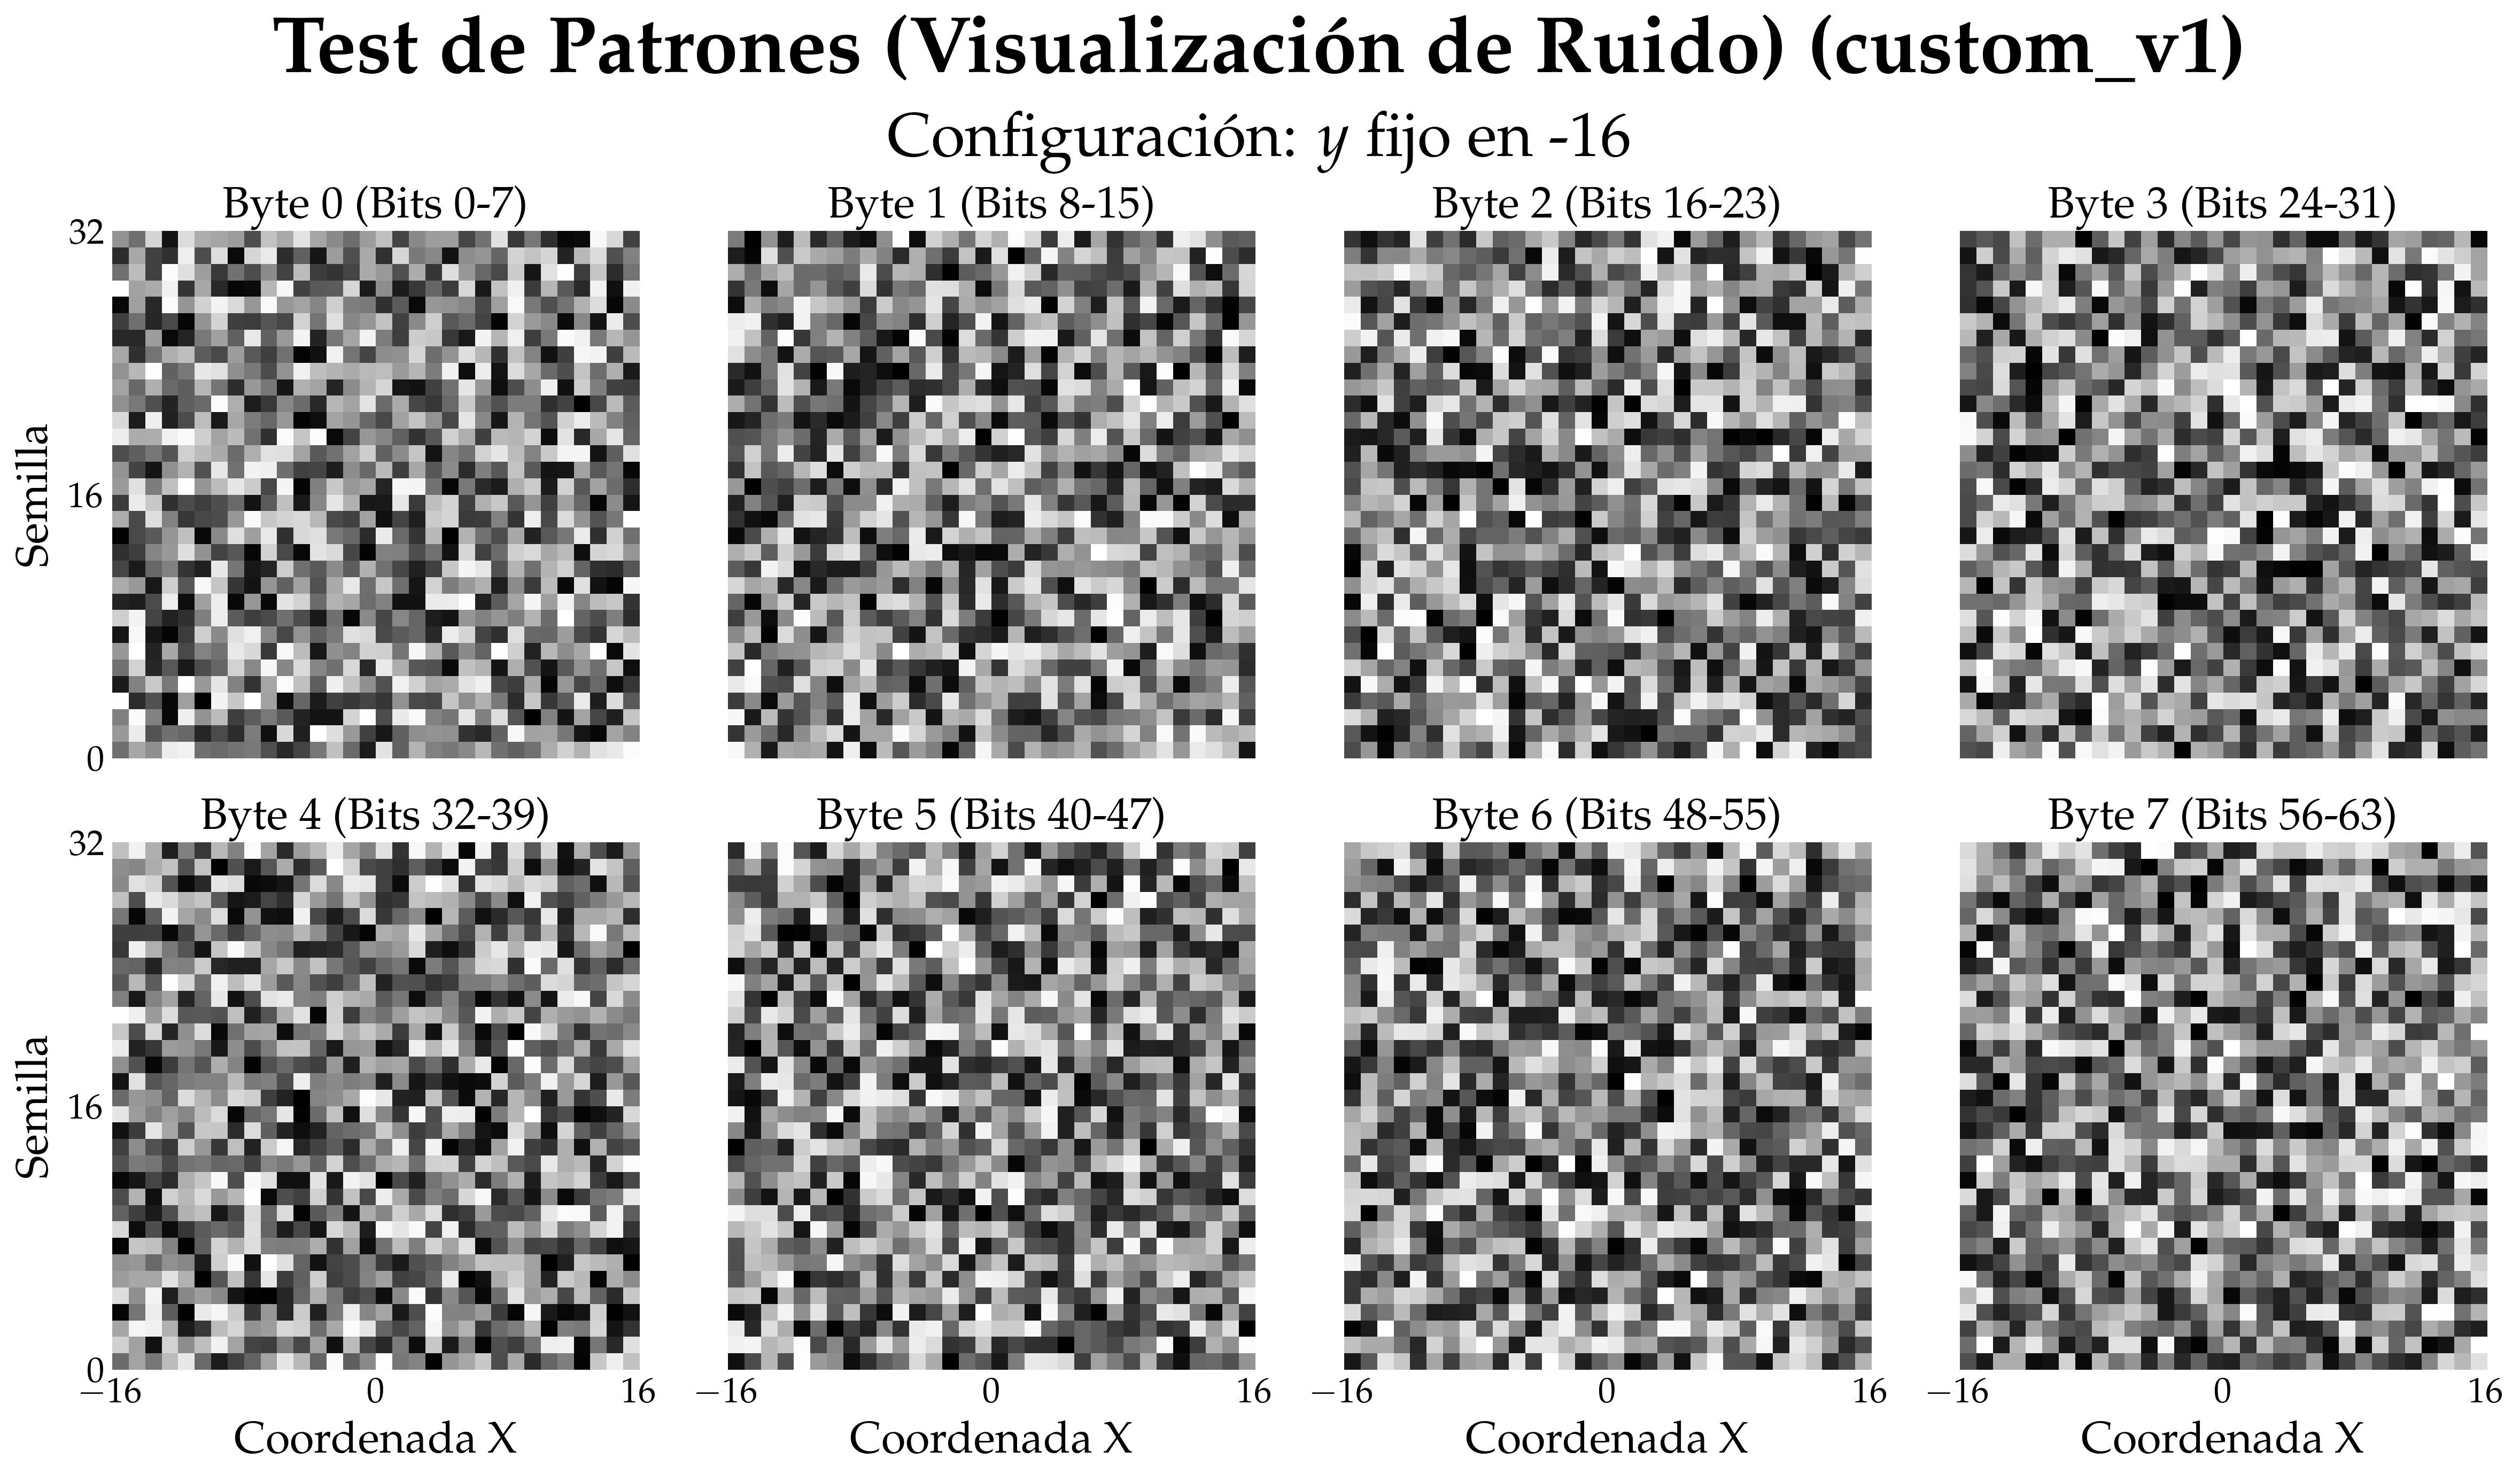

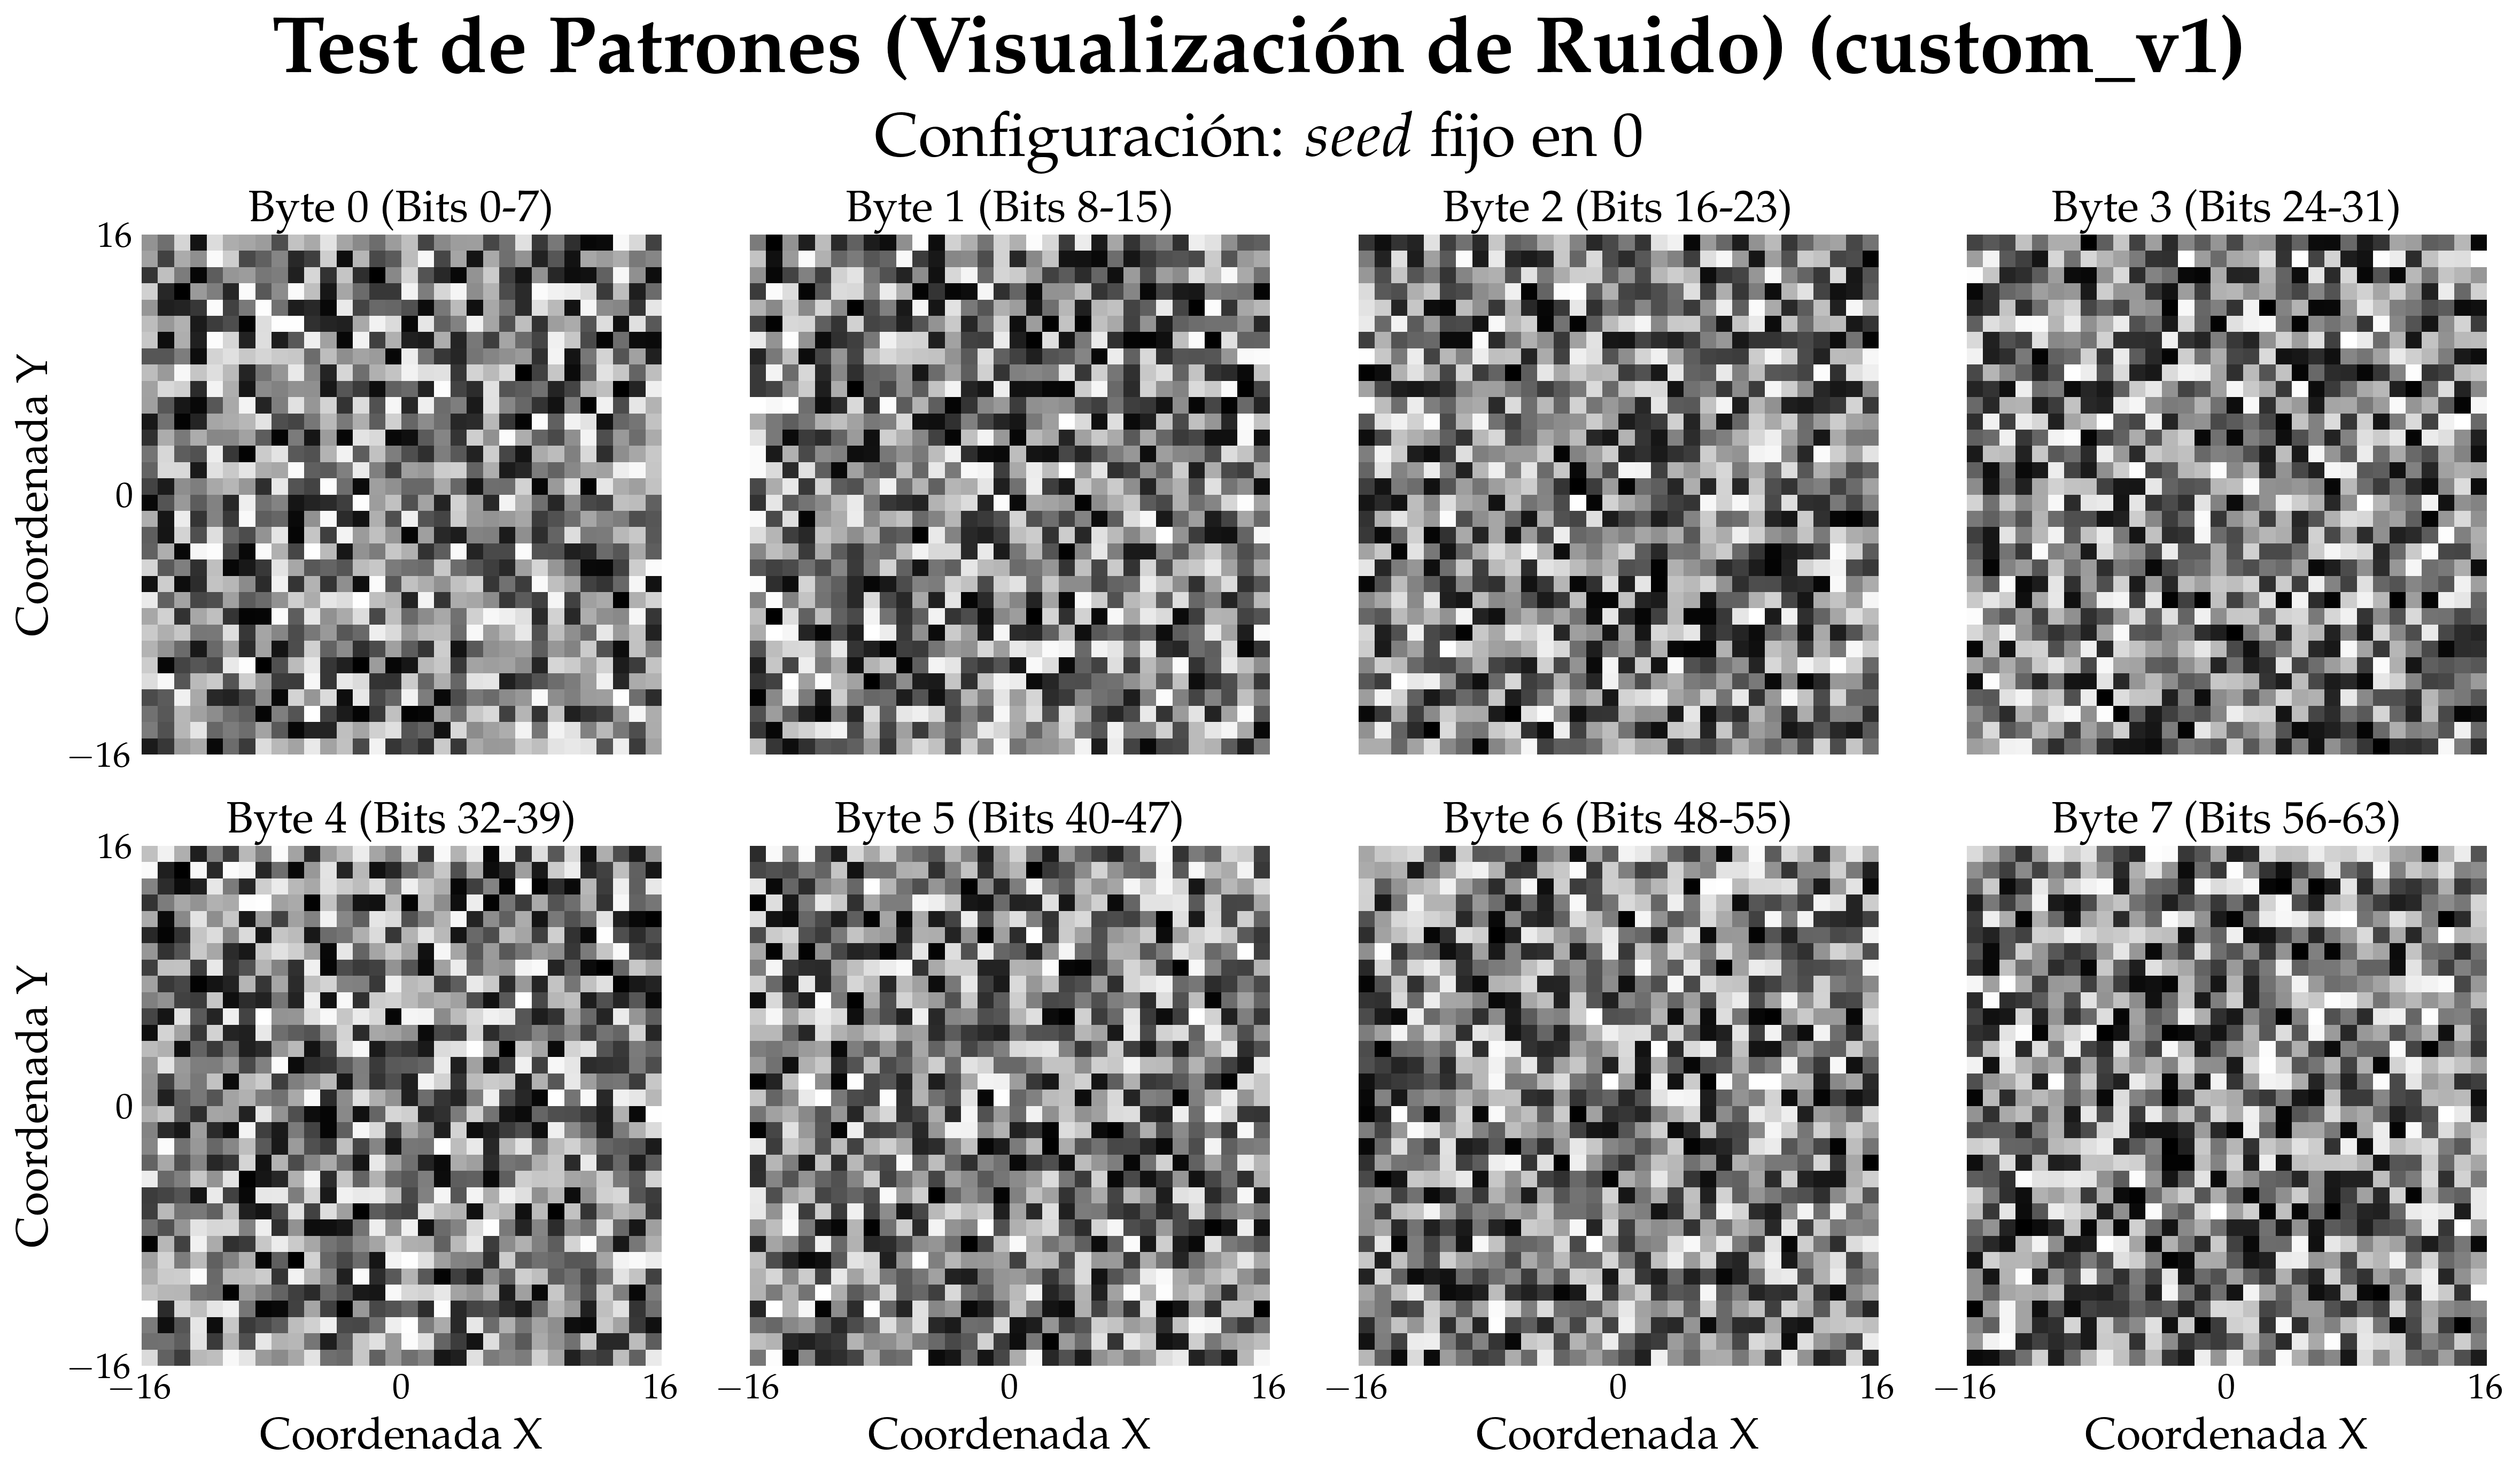

In [477]:
for idx, config_data in enumerate(pattern_data_u64):
    
    spatial_matrices = [((config_data >> (i * 8)) & 0xFF).astype(np.uint8) for i in range(8)]
    
    plot_matrix_2x4(
        matrix_list=spatial_matrices,
        config_info=configs[idx],
        main_title=f"Test de Patrones (Visualización de Ruido) ({HASH_FUNCTION})",
        xlabel=configs[idx][3],
        ylabel=configs[idx][4],
        filename_prefix="spatial",
        cbar_label="Valor del Byte (0-255)",
        vmin=0, vmax=255 
    )

### 3.3 Análisis Espectral (FFT)

Transformada de Fourier 2D para analizar el dominio de la frecuencia.

**Objetivo:** Verificar la ausencia de periodicidad. Un buen ruido aleatorio (ruido blanco) debe mostrar una distribución de energía uniforme (espectro plano) sin picos dominantes o patrones geométricos claros (estrellas, líneas fuertes) que revelarían regularidades en el hash.

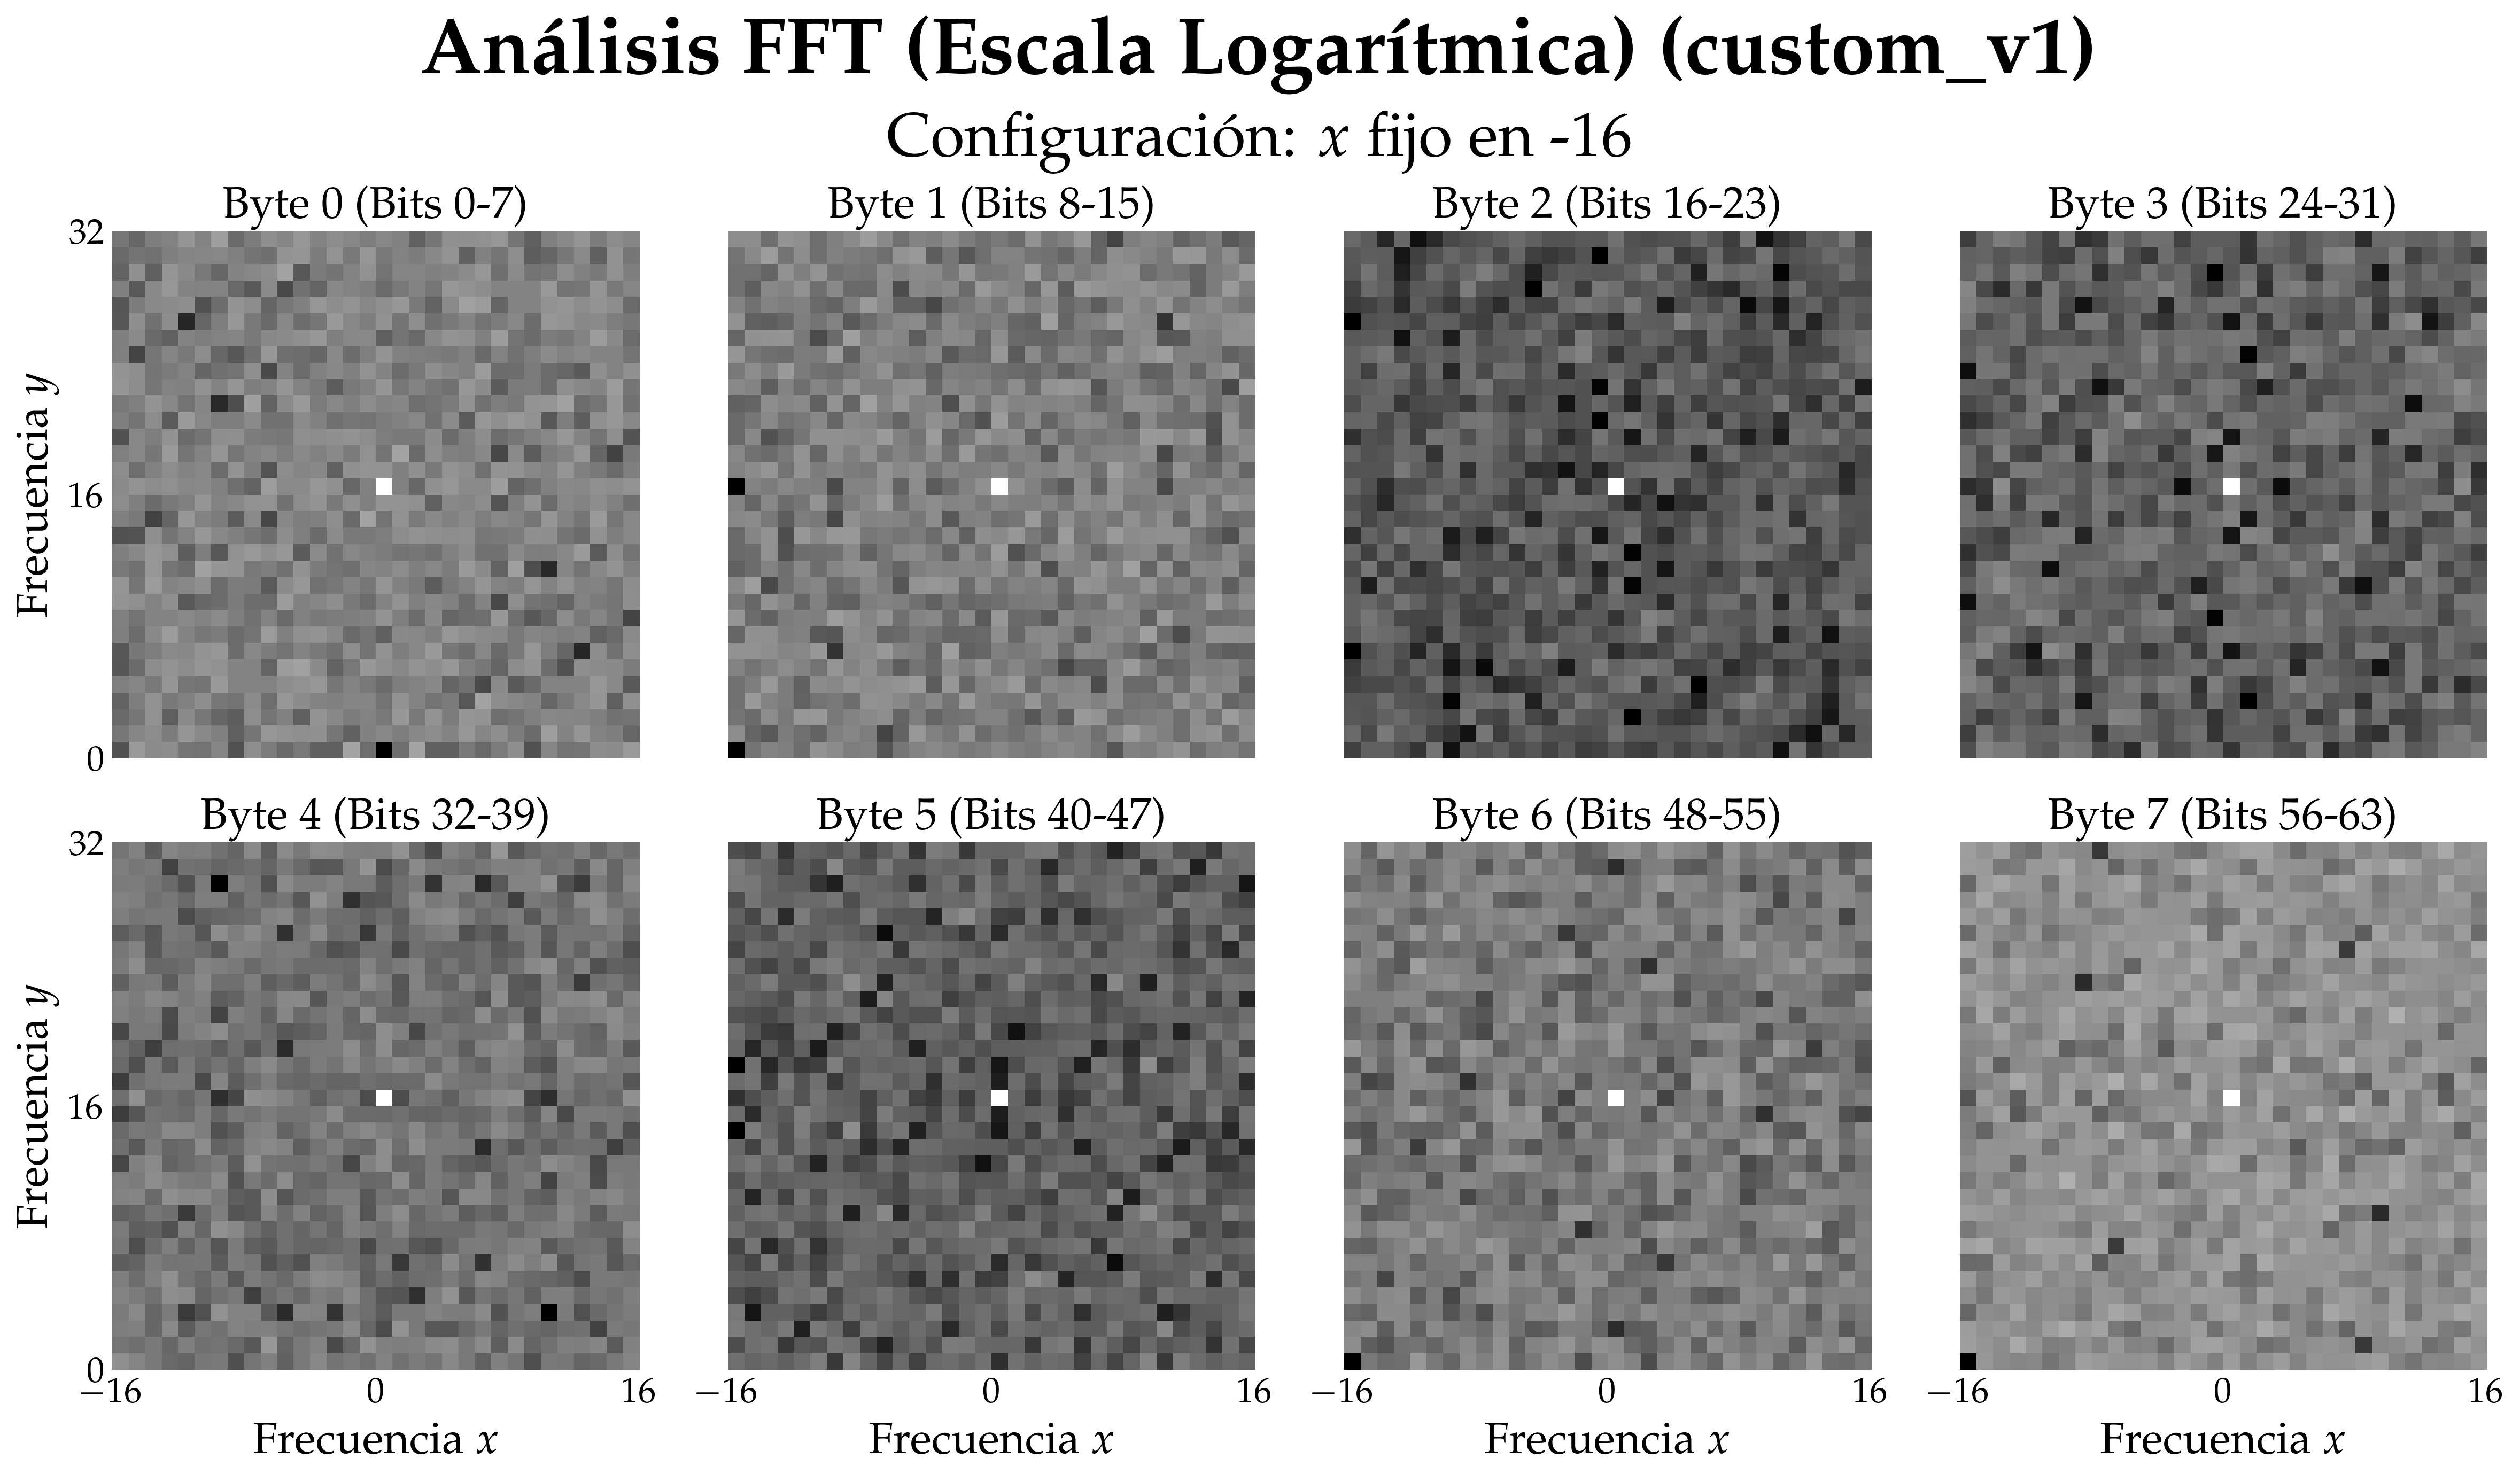

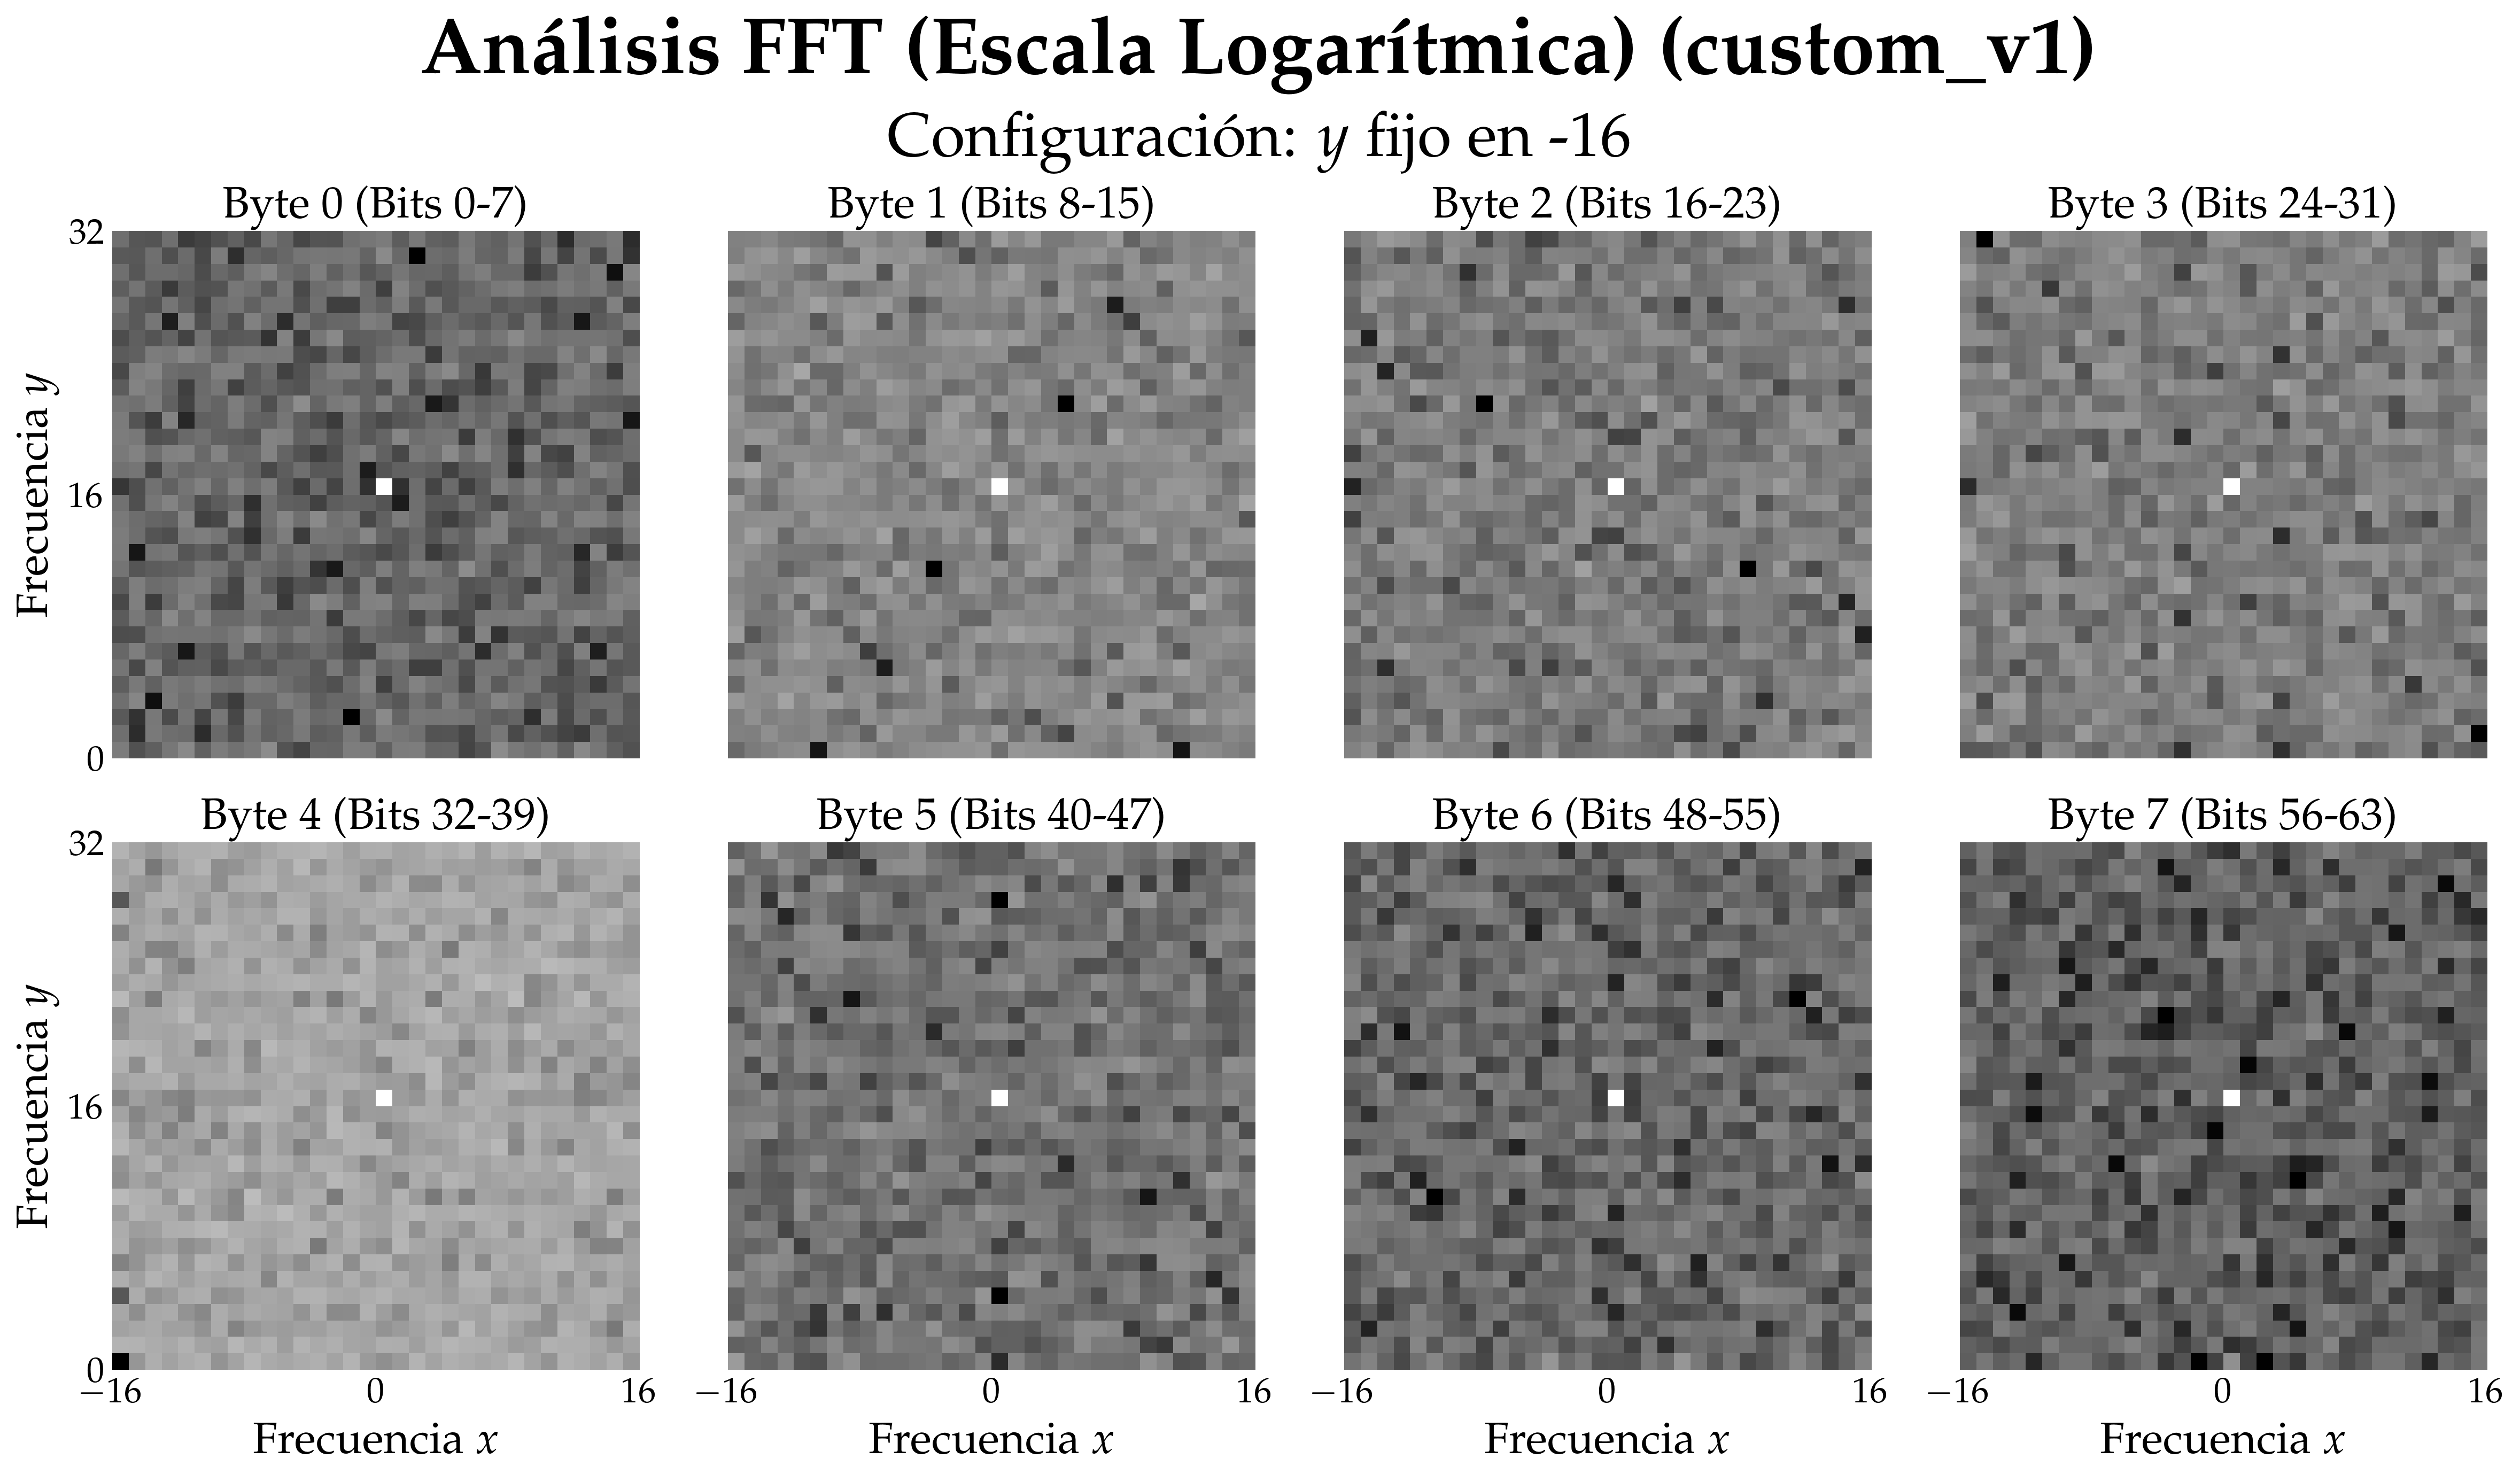

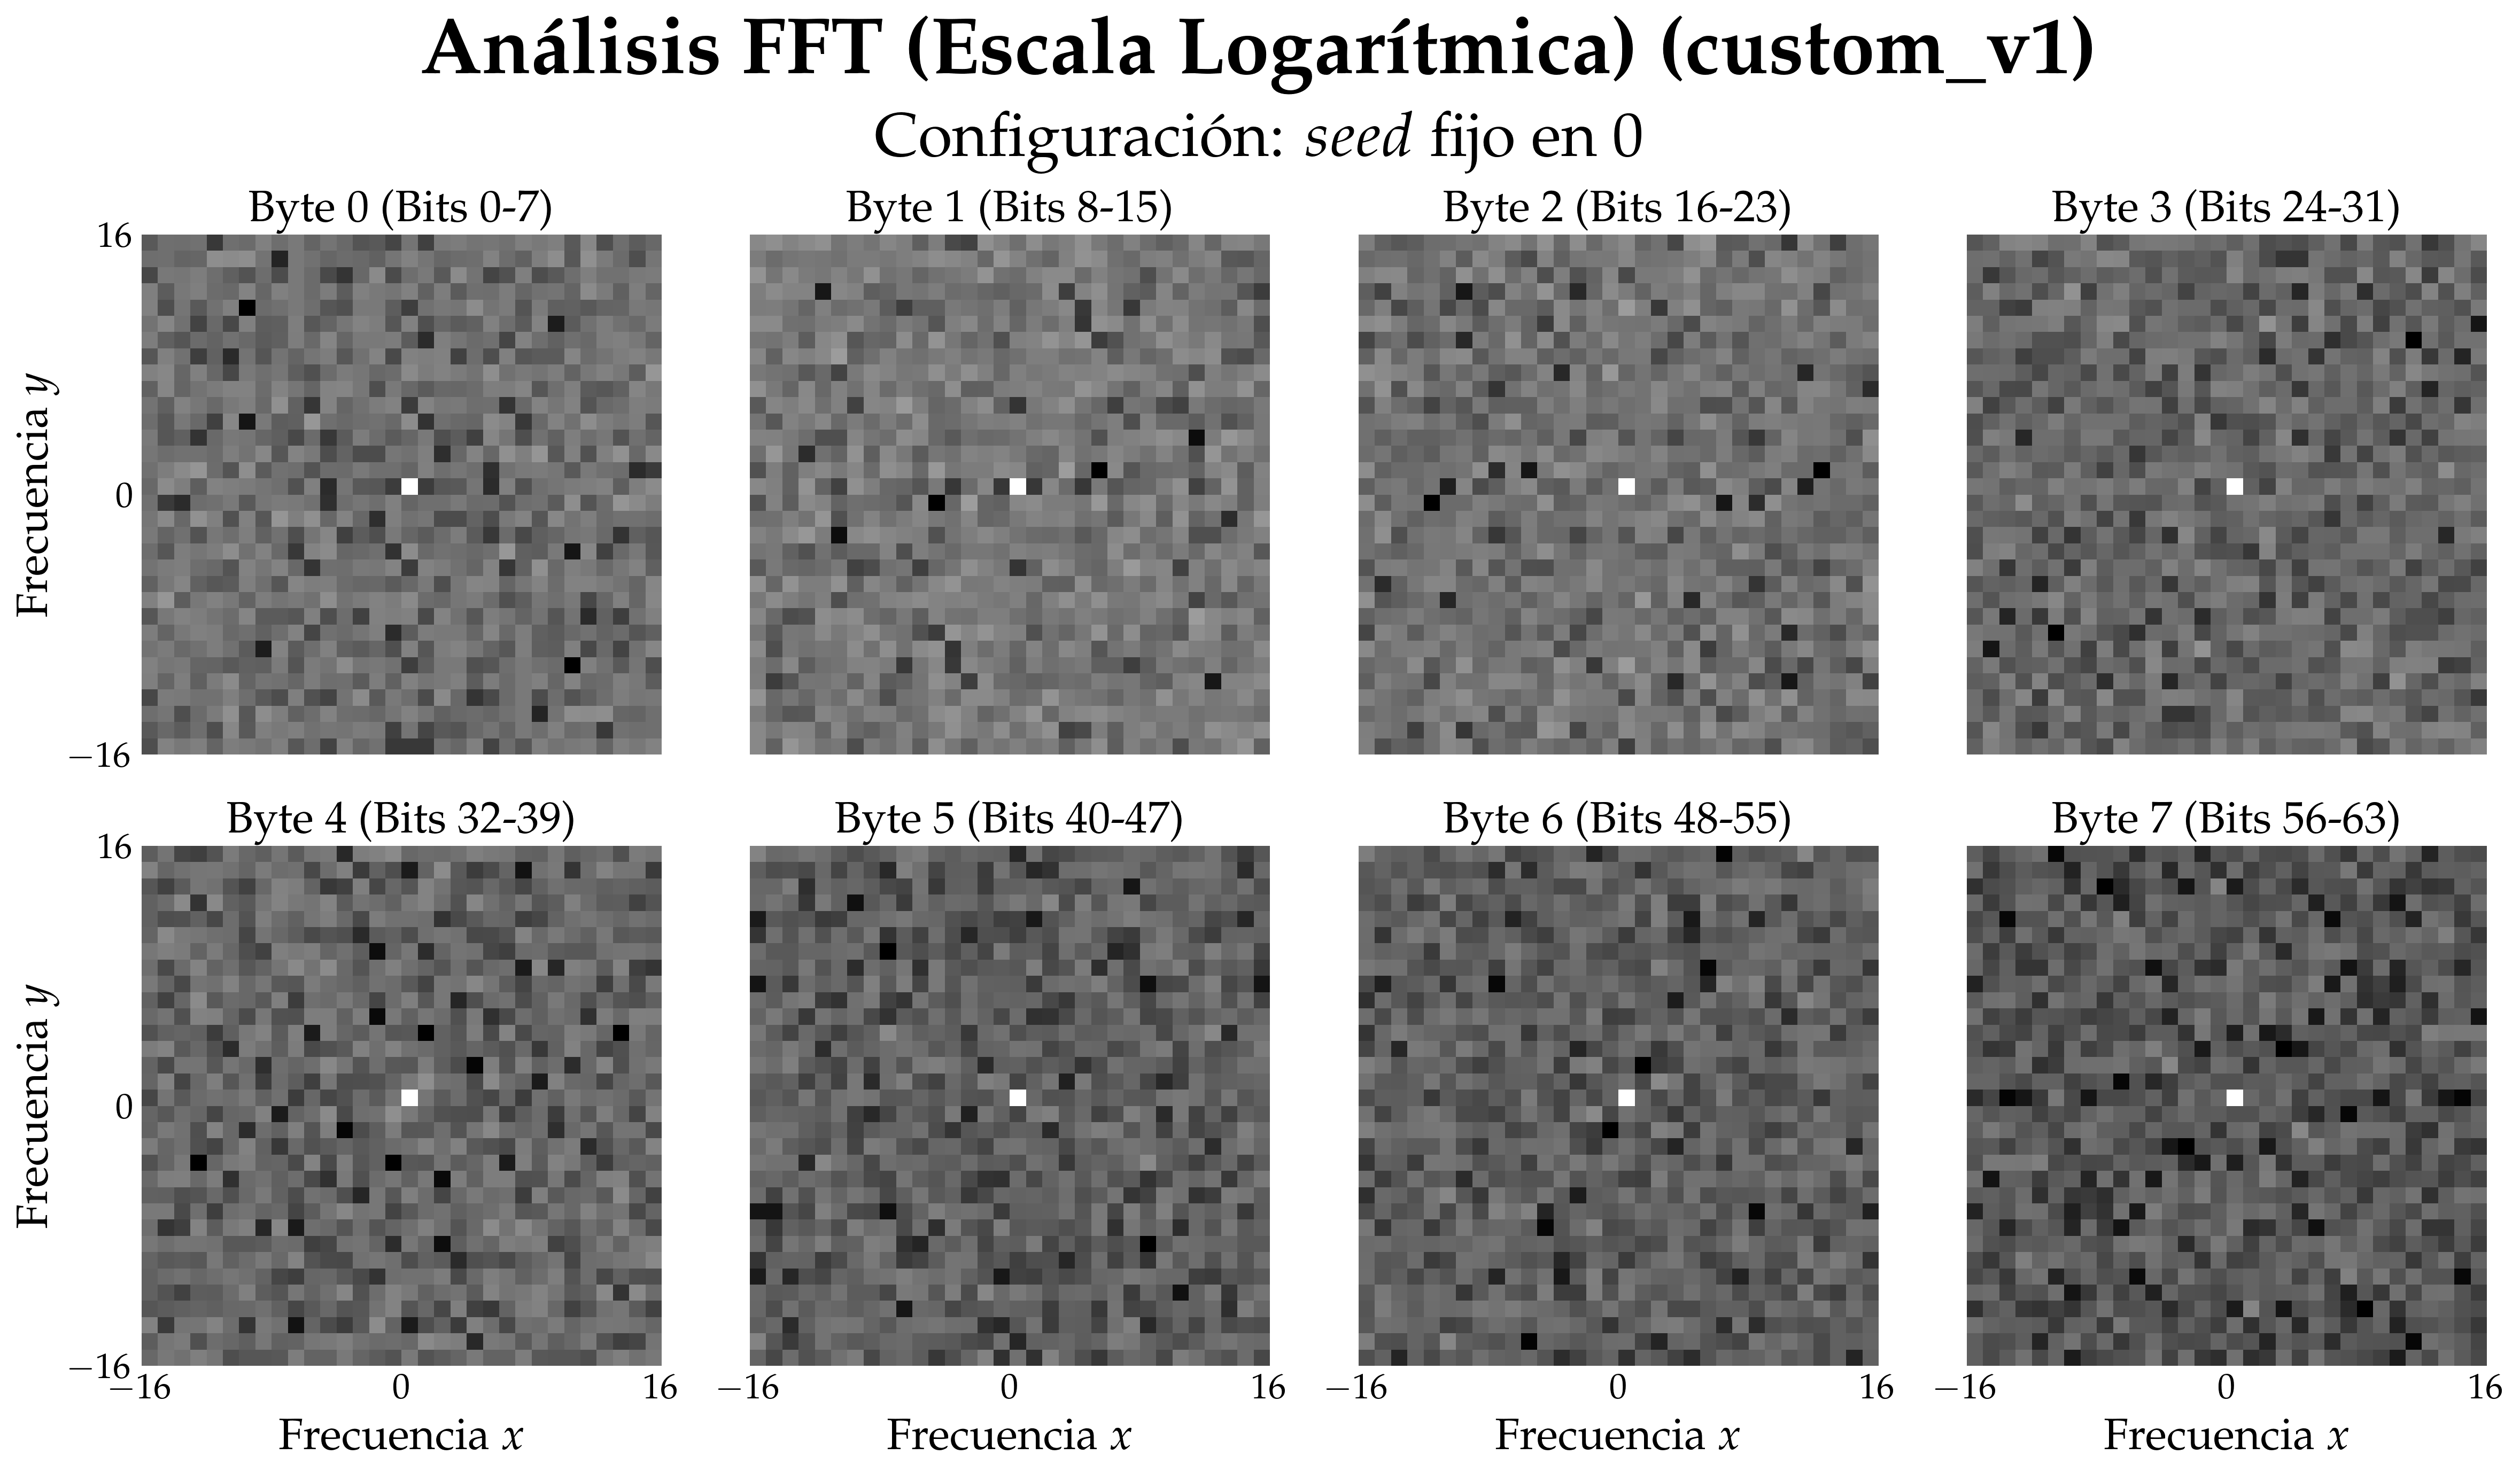

In [478]:
for idx, config_data in enumerate(pattern_data_u64):
    fft_matrices = []
    for i in range(8):
        byte_data = ((config_data >> (i * 8)) & 0xFF).astype(np.float64) 
        f_shift = np.fft.fftshift(np.fft.fft2(byte_data))
        f_shift_log = np.log2(np.abs(f_shift) + 1e-9)
        fft_matrices.append(f_shift_log)
    
    plot_matrix_2x4(
        matrix_list=fft_matrices,
        config_info=configs[idx],
        main_title=f"Análisis FFT (Escala Logarítmica) ({HASH_FUNCTION})",
        xlabel="Frecuencia $x$",
        ylabel="Frecuencia $y$",
        filename_prefix="spectral",
        cbar_label="Magnitud (dB)",
    )

## 4. Análisis de colisiones

### 4.1 Extracción de Datos

In [255]:
#40 minutos
SEEDS = 10_000_000_000
EXPLORATION_DEPTH = 1024
SEED_VAL = 0xDEADBEEFCAFEBABE

collisions_output_file = LOGS_DIR / "colisiones" / "collisions_64b.txt"

if collisions_output_file.exists():
    print(f"Cargando datos existentes desde {collisions_output_file}...")
    salida_zig = collisions_output_file.read_text()
else:
    print("\nEjecutando test...")
    cmd = ["./zig-out/bin/collisions_64b", str(SEEDS), str(EXPLORATION_DEPTH), str(SEED_VAL), HASH_FUNCTION]
    result = subprocess.run(cmd, check=True, capture_output=True, text=True)
    print(' '.join(cmd))
    salida_zig = result.stdout
    collisions_output_file.write_text(salida_zig)

Cargando datos existentes desde logs/custom_v1/Zen_3/colisiones/collisions_64b.txt...


#### 4.1.1 Datos en bruto obtenidos

In [256]:
for line in salida_zig.splitlines()[:10]:
    print(line.strip())

Byte 0 |  39999998659 |  40000281458
Byte 1 |  40000066736 |  39999536693
Byte 2 |  39999753741 |  40000014696
Byte 3 |  40000059778 |  40000214682
Byte 4 |  39999982906 |  39999908045
Byte 5 |  40000092047 |  40000085529
Byte 6 |  39999975459 |  40000127369
Byte 7 |  40000083941 |  39999837365


### 4.2 Refinado de datos

In [257]:
bytes_regex = re.compile(r'Byte\s+(\d+)\s*\|\s*(\d+)\s*\|\s*(\d+)')

bytes_matches = bytes_regex.findall(salida_zig)

total_comparisons = SEEDS * EXPLORATION_DEPTH

col_x = np.zeros(8)
col_y = np.zeros(8)

for w_idx, val_x, val_y in bytes_matches:
    idx = int(w_idx)
    col_x[idx] = int(val_x)
    col_y[idx] = int(val_y)

print(f"Total de comparaciones base (N): {total_comparisons}")

Total de comparaciones base (N): 10240000000000


### 4.2 Test de Colisiones en coordenadas colindantes

In [ ]:
def plot_colisiones_espaciales(total_N, col_x, col_y):
    bits = 8
    num_bloques = 64 // bits
    p = 1.0 / (2 ** bits)
    
    mu = total_N * p
    sigma = np.sqrt(total_N * p * (1 - p))
    
    z_x_real = (col_x - mu) / sigma
    z_y_real = (col_y - mu) / sigma
    
    valores_reales = [-27, -9, -3, 0, 3, 9, 27]
    alturas_visuales = [-3, -2, -1, 0, 1, 2, 3]
    
    z_x = np.interp(z_x_real, valores_reales, alturas_visuales)
    z_y = np.interp(z_y_real, valores_reales, alturas_visuales)
    
    x = np.arange(num_bloques)
    width = 1/3
    x_labels = [f'[{j*bits}-{(j+1)*bits-1}]' for j in range(num_bloques)]

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.tick_params(length=0)
    ax.set_ylim(-3, 3) 
    
    ax.set_yticks(alturas_visuales)
    ax.set_yticklabels([str(val) for val in valores_reales], fontsize=TICK_FONT_SIZE)

    ax.fill_between([-1, num_bloques], -1, 1, color='lightgreen', alpha=0.2, 
                    label='Zona de Aceptación (3$\\sigma$)', zorder=1)
    ax.axhline(0, color='darkgray', linestyle='--', linewidth=1.5, zorder=2)
    
    rects1 = ax.bar(x - width/2, z_x, width, color='coral', alpha=0.8, label='Horizontal (X)', zorder=3)
    rects2 = ax.bar(x + width/2, z_y, width, color='steelblue', alpha=0.8, label='Vertical (Y)', zorder=3)

    # --- Lógica para mostrar etiquetas sobre/bajo las barras ---
    def annotate_bars(rects, real_values):
        for rect, val_real in zip(rects, real_values):
            height = rect.get_height()
            if abs(val_real) > 3:
                va = 'bottom' if height > 0 else 'top'
                offset = 0.05 if height > 0 else -0.05
                ax.text(rect.get_x() + rect.get_width()/2., height + offset,
                        f'{val_real:.2f}',
                        ha='center', va=va, fontsize=10, fontweight='bold',
                        color='black', zorder=5)

    annotate_bars(rects1, z_x_real)
    annotate_bars(rects2, z_y_real)
    # ----------------------------------------------------------

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=24)
    ax.set_xticks(x + 0.5, minor=True)
    ax.tick_params(axis='x', which='minor', bottom=False)

    ax.grid(which='major', axis='y', linestyle='-', linewidth=1, color='gray', alpha=0.5)
    ax.grid(which='minor', axis='x', linestyle='-', linewidth=1, color='gray', alpha=0.5)
    ax.grid(False, which='major', axis='x')

    ax.set_xlim(-0.5, num_bloques - 0.5)


    ax.set_title('Colisiones en coordenadas colindantes por ventanas de 8 bits', 
                 fontsize=24)
    ax.set_ylabel('Z-Score ($\\sigma$)', fontweight='bold', fontsize=24)
    ax.legend(loc='upper right', fontsize=LEGEND_FONT_SIZE)

    plt.suptitle(f'\\textbf{{Test de colisiones ({HASH_FUNCTION})}}', 
                y=0.94, fontsize=40)

    plt.tight_layout()
    
    fig.savefig(OUTPUT_DIR / "colisiones" / f'collisions_spatial_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)
    
    plt.show()

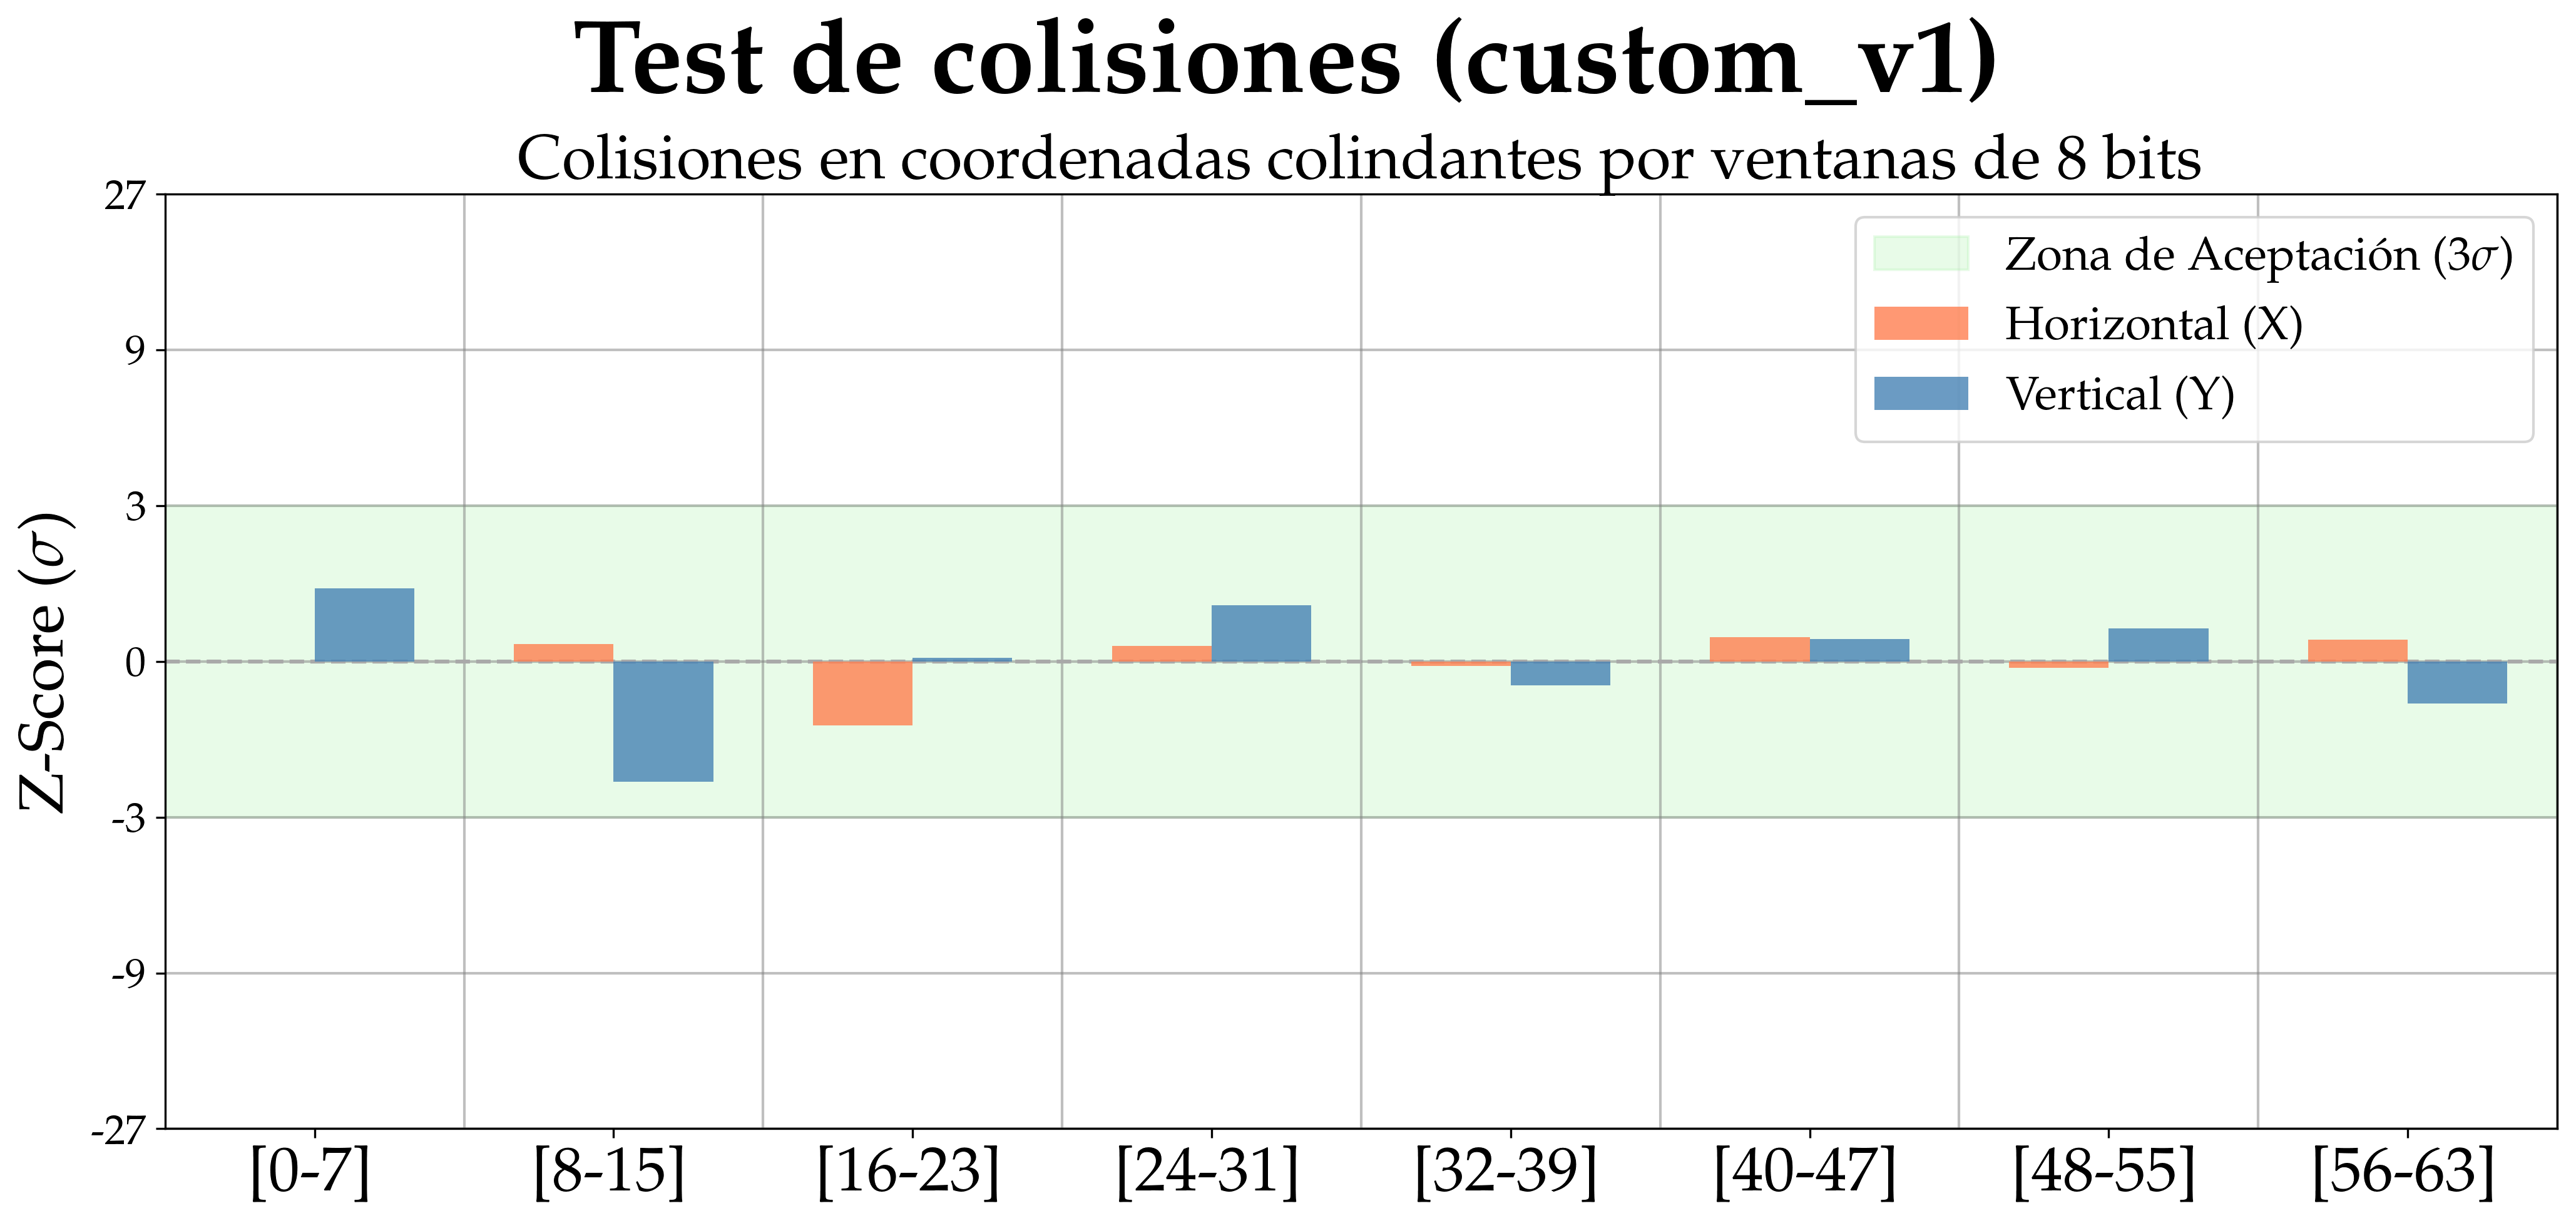

In [278]:
plot_colisiones_espaciales(total_comparisons, col_x, col_y)

## 5. Test de Throughput (Monohilo)

Este apartado mide el coste de `hash(seed, x, y)` en ciclos por llamada.
El benchmark esta diseñado para reducir ruido de microbenchmarking:

- ejecuta una fase de warm-up antes de medir,
- mide lotes grandes y divide por el numero de hashes, evitando que el compilador optimize
- repite la medicion varias veces,

> Si ejecutas el benchmark en un procesador ARM, las mediciones de ciclos serán incorrectas en
> valores absolutos, pero sirven para comparar entre implementaciones a nivel local.
> Esto se debe a que es necesario el acceso al registro `PMCR_EL0`, al que hay que 
> solicitar acceso a invel de kernel. Puedes recalcular sabiendo la frecuencia del reloj 
> virtual y la frecuencia del reloj real

### 5.1 Extracción de Datos

Compilación y ejecución del benchmark C para obtención de métricas de rendimiento (ciclos/hash).

In [243]:
hashes = ["custom_v1", "custom_v2", "rapidhash"]
results_throughput = {}

UNROLL_FACTOR = 32
THROUGHPUT_REPS = 2**16 * 3
THROUGHPUT_BATCH = 2**16
THROUGHPUT_SEED = 0xDEADBEEFCAFEBABE

for hash_fn in hashes:
    # Usamos subcarpetas específicas para cada hash dentro de logs/
    hash_logs_dir = Path(f"logs/{hash_fn}/{ARCHITECTURE.replace(' ', '_')}")
    # Aseguramos que la subcuenta de throughput exista
    (hash_logs_dir / "throughput").mkdir(parents=True, exist_ok=True)
    
    throughput_output_file = hash_logs_dir / "throughput" / "throughput_64b.txt"

    if throughput_output_file.exists():
        print(f"Cargando datos existentes para {hash_fn} desde {throughput_output_file}...")
        results_throughput[hash_fn] = throughput_output_file.read_text()
    else:
        print(f"\nEjecutando test para {hash_fn}...")
        cmd = ["./zig-out/bin/throughput_64b",  str(THROUGHPUT_REPS), str(THROUGHPUT_BATCH), str(THROUGHPUT_SEED), hash_fn, str(UNROLL_FACTOR)]
        print(' '.join(cmd))

        result = subprocess.run(cmd, capture_output=True, text=True, check=True)
        data_throughput = result.stdout

        throughput_output_file.write_text(data_throughput)
        results_throughput[hash_fn] = data_throughput

Cargando datos existentes para custom_v1 desde logs/custom_v1/Zen_3/throughput/throughput_64b.txt...
Cargando datos existentes para custom_v2 desde logs/custom_v2/Zen_3/throughput/throughput_64b.txt...
Cargando datos existentes para rapidhash desde logs/rapidhash/Zen_3/throughput/throughput_64b.txt...


#### 5.1.1 Datos en bruto obtenidos

In [244]:
for hash_fn in hashes:
    print(f"Hash: {hash_fn}")
    print("Primeras líneas:")
    print("\t" + "\n\t".join(results_throughput[hash_fn].strip().splitlines()[:5]))
    print("")

Hash: custom_v1
Primeras líneas:
	REP    0 : 4.2469 cycles/hash
	REP    1 : 4.2827 cycles/hash
	REP    2 : 4.1172 cycles/hash
	REP    3 : 4.4757 cycles/hash
	REP    4 : 4.1161 cycles/hash

Hash: custom_v2
Primeras líneas:
	REP    0 : 4.0627 cycles/hash
	REP    1 : 4.0451 cycles/hash
	REP    2 : 4.0482 cycles/hash
	REP    3 : 4.0482 cycles/hash
	REP    4 : 4.0388 cycles/hash

Hash: rapidhash
Primeras líneas:
	REP    0 : 4.5037 cycles/hash
	REP    1 : 4.4700 cycles/hash
	REP    2 : 4.9457 cycles/hash
	REP    3 : 4.4669 cycles/hash
	REP    4 : 4.4798 cycles/hash



### 5.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas (repeticiones, ciclos/hash, estadísticos).

In [245]:
REP_PATTERN = re.compile(r"REP\s+\d+\s+:\s+([0-9]+(?:\.[0-9]+)?)\s+cycles/hash")

def process_hash_statistics(values, sigma_threshold=6):
    mean_val = sum(values) / len(values)
    std_val = (sum((x - mean_val) ** 2 for x in values) / len(values)) ** 0.5
    
    limit = mean_val + (sigma_threshold * std_val)
    
    clean_values = [v for v in values if v <= limit]
    outliers_count = len(values) - len(clean_values)
    n_clean = len(clean_values)

    stats = {
        "cycles_per_rep": clean_values,
        "median": sorted(clean_values)[n_clean // 2],
        "min": min(clean_values),
        "max": max(clean_values),
        "mean": sum(clean_values) / n_clean,
        "threshold": limit
    }
    
    return stats, outliers_count

tp_stats = {}
for hash_fn in hashes:
    raw_results = results_throughput.get(hash_fn, "")
    
    cycles = [float(val) for val in REP_PATTERN.findall(raw_results)]
    
    sigma_threshold = 2
    stats, num_outliers = process_hash_statistics(cycles, sigma_threshold)
    tp_stats[hash_fn] = stats

    print(f"[!] {hash_fn}: {num_outliers:3} outliers eliminados (umbral > {stats['threshold']:.3f} cycles/hash | {sigma_threshold}σ)")

[!] custom_v1: 1793 outliers eliminados (umbral > 5.638 cycles/hash | 2σ)
[!] custom_v2: 2326 outliers eliminados (umbral > 5.609 cycles/hash | 2σ)
[!] rapidhash: 8541 outliers eliminados (umbral > 5.428 cycles/hash | 2σ)


### 5.3 Visualización de Datos

#### 5.3.1 Distribución de Ciclos por Hash

Histograma y boxplot para ver dispersión, outliers y concentración de las mediciones.

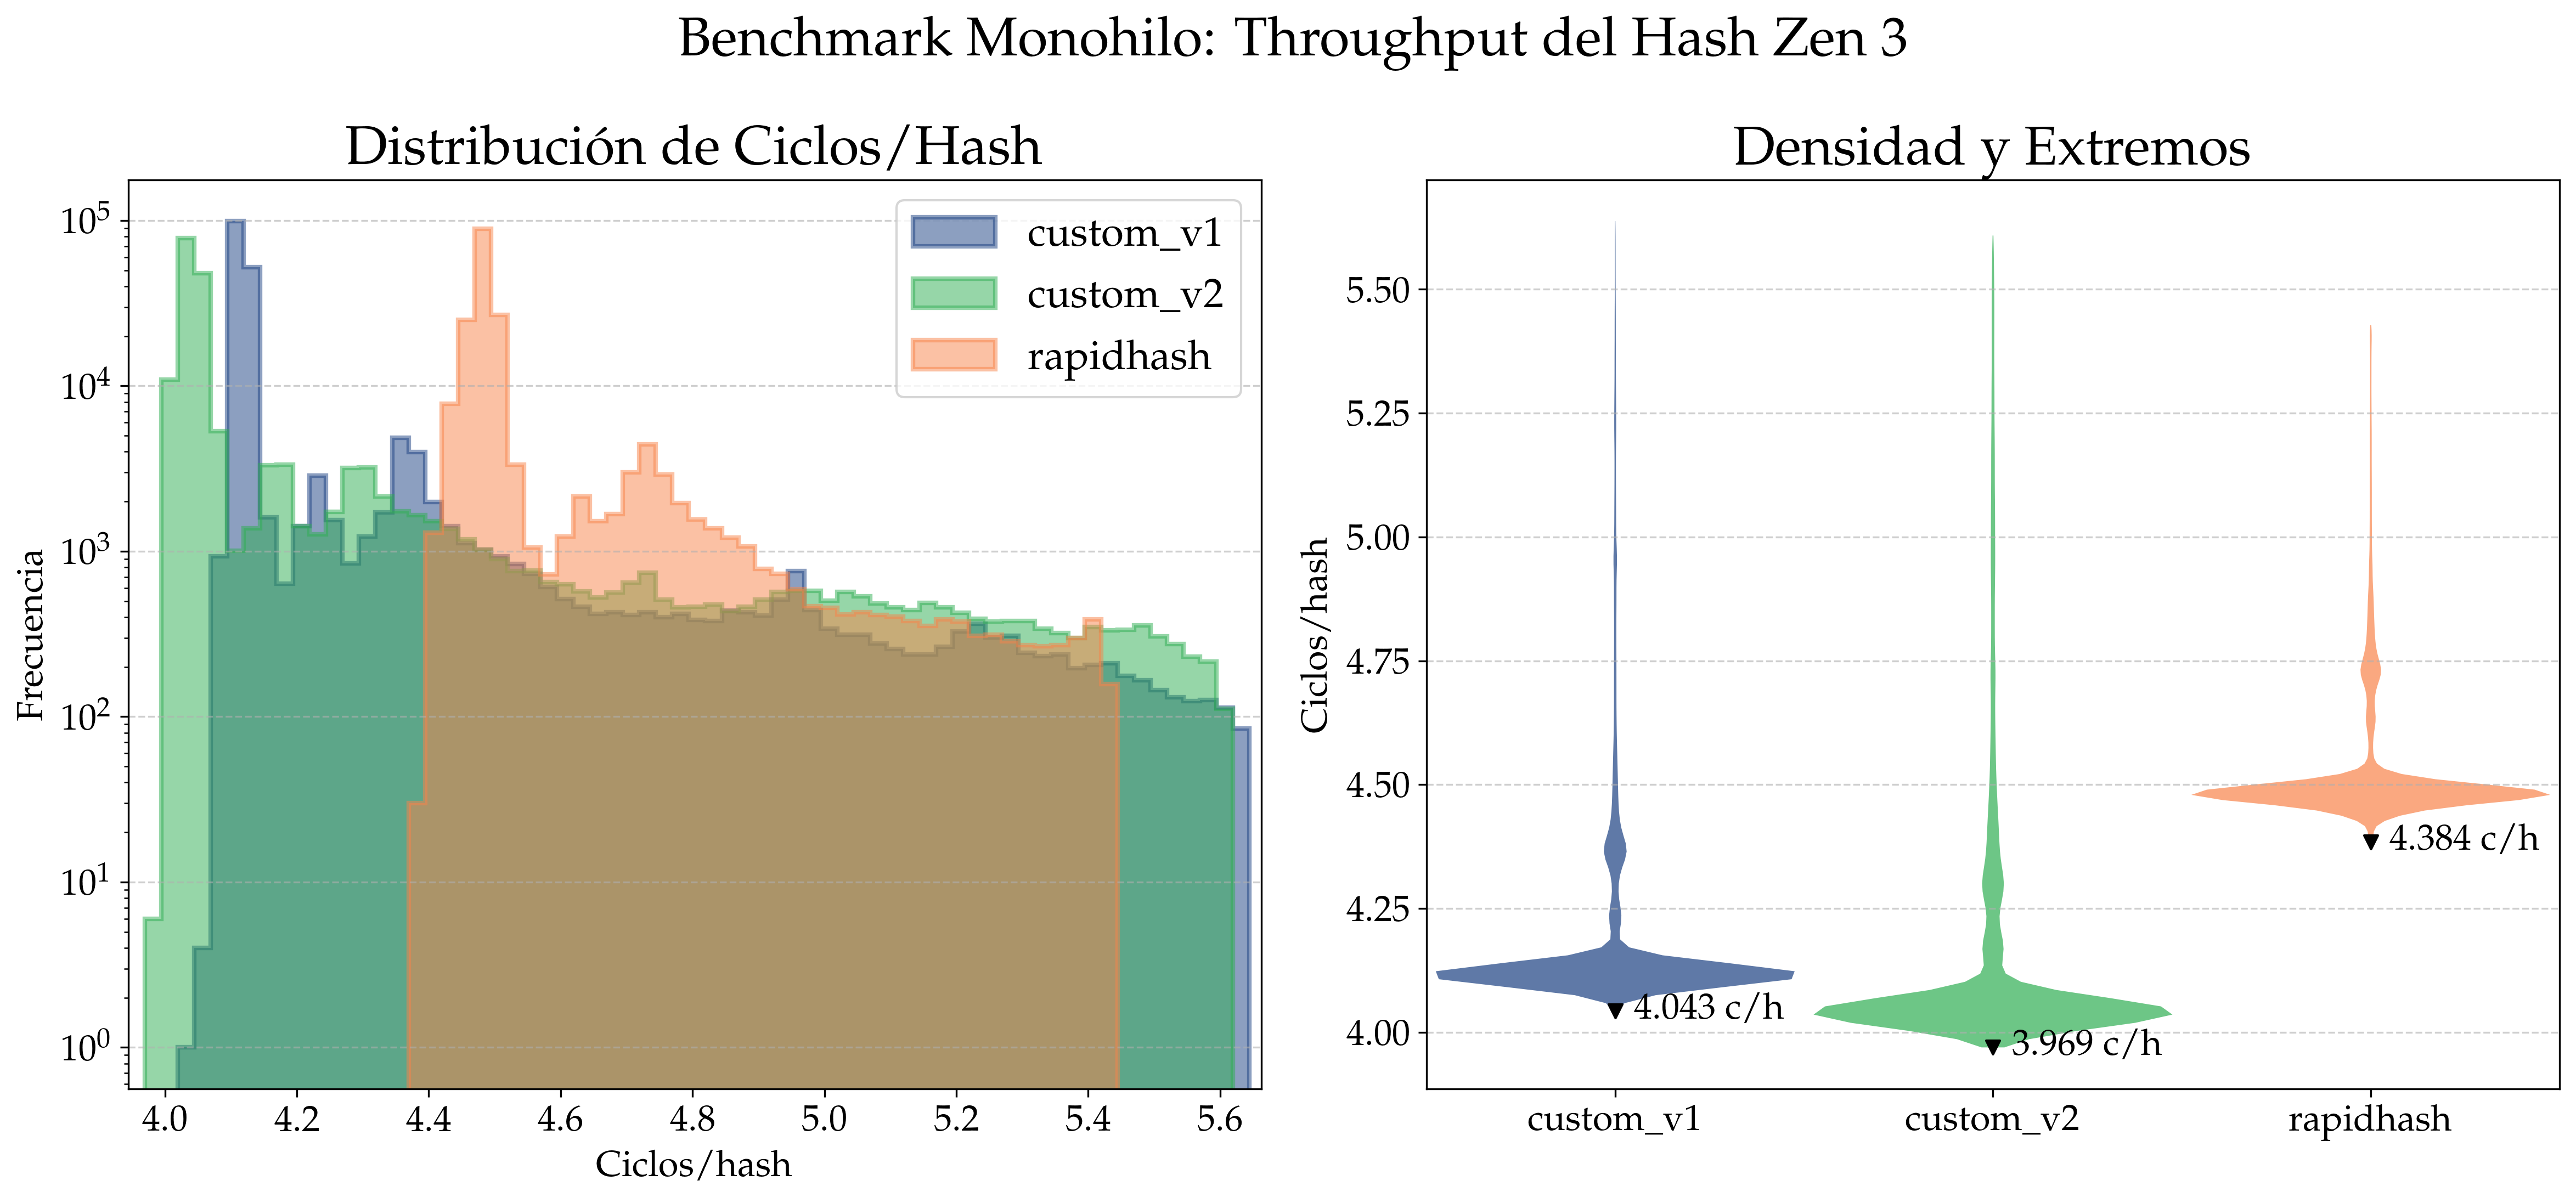

In [253]:
data_list = [tp_stats[hash_fn]["cycles_per_rep"] for hash_fn in hashes]

bins = np.arange(min(min(d) for d in data_list), max(max(d) for d in data_list) + 0.025, 0.025)

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
colors = [COLOR_BLUE, COLOR_GREEN, COLOR_ORANGE][:len(hashes)]

# --- 1. Histograma ---
for idx, d in enumerate(data_list):
    axes[0].hist(d, bins=bins, color=colors[idx], alpha=0.5, 
        histtype='stepfilled', edgecolor=colors[idx], linewidth=2, label=hashes[idx])

axes[0].set_title("Distribución de Ciclos/Hash")
axes[0].set_xlabel("Ciclos/hash")
axes[0].set_xlim(min(min(d) for d in data_list) - 0.025, max(max(d) for d in data_list) + 0.025)
axes[0].set_ylabel("Frecuencia")
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)
axes[0].set_yscale('log')

# --- 2. Gráfico de Violín ---
parts = axes[1].violinplot(data_list, showextrema=False, widths=0.95)

for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[idx])
    pc.set_alpha(0.7)

for idx, d in enumerate(data_list):
    min_c = min(d)
    axes[1].scatter(idx + 1, min_c, color='black', marker='v', zorder=3)
    axes[1].text(idx + 1 + 0.05, min_c, f"{min_c:.3f} c/h", color='black', va='center')

axes[1].set_title("Densidad y Extremos")
axes[1].set_ylabel("Ciclos/hash")
axes[1].set_xticks(range(1, len(hashes) + 1))
axes[1].set_xticklabels(hashes)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
axes[1].set_xlim(0.5, len(hashes) + 0.5)

fig.suptitle(f"Benchmark Monohilo: Throughput del Hash {ARCHITECTURE}", fontweight='bold')
fig.tight_layout()

# Guardamos en la carpeta del hash principal configurado (aunque muestre todos)
fig.savefig(OUTPUT_DIR / "throughput" / f'throughput_distribution_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()

In [247]:
unroll_factors = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32]
min_cycles_per_hash = {h: [] for h in hashes}

print("Recolectando datos de escalabilidad por factor de unroll...\n")

for uf in unroll_factors:
    current_batch = THROUGHPUT_BATCH if THROUGHPUT_BATCH % uf == 0 else (THROUGHPUT_BATCH // uf) * uf
    for hash_fn in hashes:
        # Directorio de logs para este hash y arquitectura
        hash_logs_dir = Path(f"logs/{hash_fn}/{ARCHITECTURE.replace(' ', '_')}")
        unroll_log_file = hash_logs_dir / "throughput" / f"throughput_64b_unroll_{uf}.txt"
        
        if unroll_log_file.exists():
            # print(f"\t{hash_fn:12s} | Unroll {uf:2d} | Cargando desde log...")
            data_unroll = unroll_log_file.read_text()
        else:
            print(f"\t{hash_fn:12s} | Unroll {uf:2d} | Ejecutando...")
            cmd = [
                "./zig-out/bin/throughput_64b",  
                str(THROUGHPUT_REPS), 
                str(current_batch), 
                str(THROUGHPUT_SEED), 
                hash_fn, 
                str(uf)
            ]
            result = subprocess.run(cmd, capture_output=True, text=True, check=True)
            data_unroll = result.stdout
            unroll_log_file.write_text(data_unroll)
        
        cycles = [float(val) for val in REP_PATTERN.findall(data_unroll)]
        if not cycles:
            print(f"Advertencia: No se encontraron datos en {unroll_log_file}")
            continue
            
        min_cycle = min(cycles)
        min_cycles_per_hash[hash_fn].append(min_cycle)
        # print(f"\t{hash_fn:12s} | Unroll {uf:2d} | Min Cycles/Hash: {min_cycle:.3f}")

print("\nFinalizado.")


Recolectando datos de escalabilidad por factor de unroll...


Finalizado.


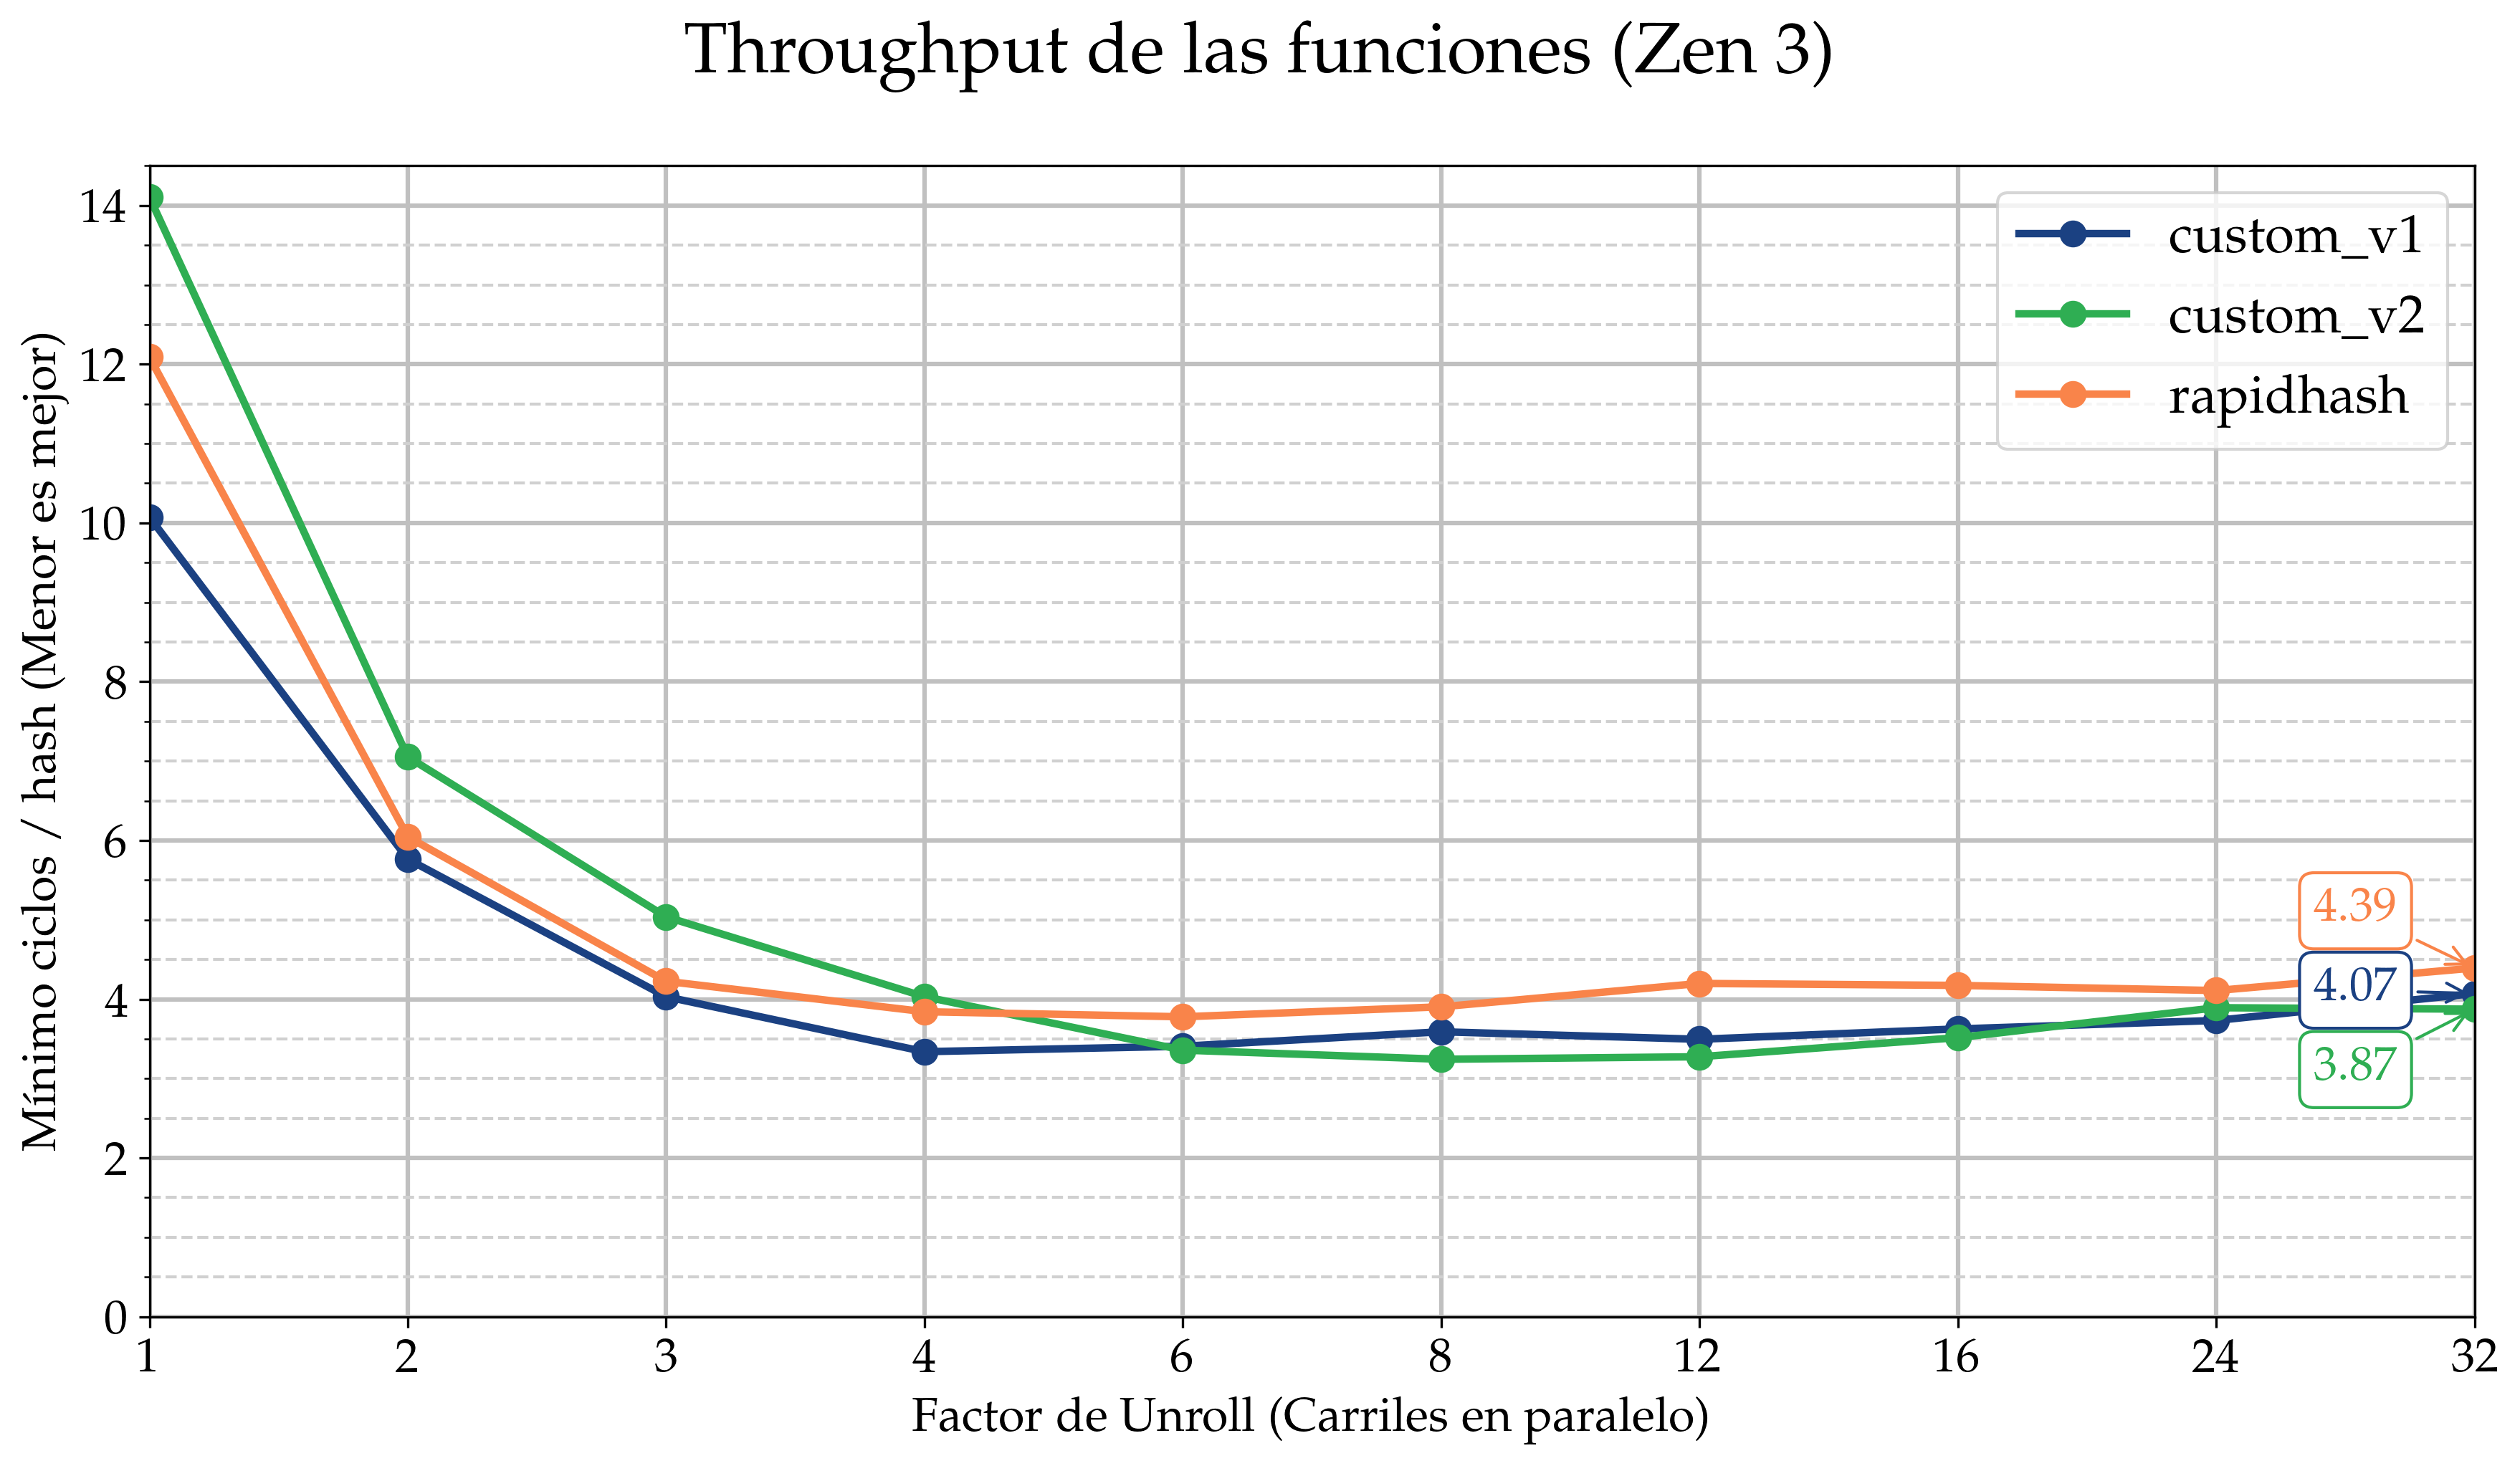

In [248]:
fig, ax = plt.subplots(figsize=(12,7))

colors = [COLOR_BLUE, COLOR_GREEN, COLOR_ORANGE]
x_indices = range(len(unroll_factors))

global_min = min([min(min_cycles_per_hash[h]) for h in hashes])
global_max = max([max(min_cycles_per_hash[h]) for h in hashes])

final_points = []

for idx, hash_fn in enumerate(hashes):
    y_values = min_cycles_per_hash[hash_fn]
    
    ax.plot(x_indices, y_values, 
            marker='o', linestyle='-', linewidth=2.5, markersize=8,
            color=colors[idx], label=hash_fn)
    
    final_points.append({
        'hash': hash_fn,
        'y': y_values[-1],
        'color': colors[idx]
    })

# Lógica de separación de etiquetas
final_points.sort(key=lambda item: item['y'])
min_spacing = 1
text_y_positions = [item['y'] for item in final_points]

for i in range(1, len(text_y_positions)):
    if text_y_positions[i] - text_y_positions[i-1] < min_spacing:
        text_y_positions[i] = text_y_positions[i-1] + min_spacing

shift_down = (sum(text_y_positions) - sum(item['y'] for item in final_points)) / len(final_points)
text_y_positions = [y - shift_down for y in text_y_positions]

final_x = x_indices[-1]
for i, point in enumerate(final_points):
    final_y = point['y']
    text_y = text_y_positions[i]
    
    ax.annotate(
        f"{final_y:.2f}", 
        xy=(final_x, final_y), 
        xytext=(final_x - 0.3, text_y),
        color=point['color'], va='center', ha='right', fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor=point['color']),
        arrowprops=dict(arrowstyle="->", color=point['color'])
    )

# Títulos y etiquetas
fig.suptitle(f"Throughput de las funciones ({ARCHITECTURE})", fontweight='bold', fontsize=TITLE_FONT_SIZE)
ax.set_xlabel("Factor de Unroll (Carriles en paralelo)", fontsize=LABEL_FONT_SIZE)
ax.set_ylabel("Mínimo ciclos / hash (Menor es mejor)", fontsize=LABEL_FONT_SIZE)

# Configuración del eje X
ax.set_xticks(x_indices)
ax.set_xticklabels([str(x) for x in unroll_factors], fontsize=TICK_FONT_SIZE)

ax.set_ylim(bottom=0, top=math.floor(global_max * 2) / 2 + 0.5)
ax.set_xlim(0, len(unroll_factors) - 1) 

# Configuración estructural de Ticks y Grid
ax.yaxis.set_minor_locator(plt.MultipleLocator(0.5))
ax.grid(which='major', color=GRAY, linestyle='-', linewidth=1.5)
ax.grid(which='minor', color=GRAY_LIGHT, linestyle='--', linewidth=1)

ax.legend(fontsize=LEGEND_FONT_SIZE)

fig.tight_layout()

fig.savefig(OUTPUT_DIR / "throughput" / f'throughput_scalability_{HASH_FUNCTION}_{ARCHITECTURE.replace(" ", "_")}.pdf', dpi=300)

plt.show()